In [53]:
# measure_curvature_targets.py
# Compute whole-dataset hilltop curvature targets (median |κ|) for GM and AP
# Uses the same first-order divide method and A_crit thresholds as your tiles.

import json
import numpy as np
from TopoAnalysis import dem as d
import topo_analysis as ta

# --- config (adjust paths if needed) ------------------------------------
DATA = {
    "GM": dict(
        elev="data/GM_Lidar_overlap_10m_filled",
        area="data/GM_Lidar_overlap_10m_area",
        flow="data/GM_Lidar_overlap_10m_fd",
    ),
    "AP": dict(
        elev="data/AP_Lidar_overlap_30m_filled",
        area="data/AP_Lidar_overlap_30m_area",
        flow="data/AP_Lidar_overlap_30m_fd",
    ),
}

# Taylor Acrit thresholds (same ones you use per-tile)
ACRIT = {"GM": 1.0e4, "AP": 5.04e4}  # m^2

DIVIDE_MIN_PIXELS = 5   # require at least this many hilltop curvature samples
STENCIL = 9             # same stencil as in your tile code
OUTFILE = "curvature_targets.json"

def load_full(tag):
    cfg = DATA[tag]
    elev = d.Elevation.load(cfg["elev"])
    area = d.Area.load(cfg["area"])
    fd   = d.FlowDirectionD8.load(cfg["flow"])
    print(f"[{tag}] loaded: DEM shape = {elev._griddata.shape}")
    return elev, area, fd

def measure_curv_target(tag):
    """Return (curv_target, stats_dict) where curv_target = median |κ| (float)."""
    elev, area, fd = load_full(tag)
    acrit = float(ACRIT[tag])

    # First-order divide curvature across the whole grid
    curvs, divide_pts, labels, outlets = ta.extract_hilltop_curvature_first_order(
        elev, area, fd, acrit, stencil=STENCIL
    )

    n_div = len(divide_pts)
    n_curv = len(curvs)

    if n_curv < DIVIDE_MIN_PIXELS:
        raise RuntimeError(
            f"[{tag}] Too few hilltop curvature samples: {n_curv} < {DIVIDE_MIN_PIXELS}"
        )

    # Your sign convention: compare positive magnitude to targets → use -(median of values)
    curv_target = -float(np.median(curvs))  # m^-1

    stats = dict(
        tag=tag,
        Acrit=acrit,
        stencil=STENCIL,
        n_divides=n_div,
        n_curv=n_curv,
        median_abs_kappa=curv_target,   # our positive-magnitude convention
        p10_abs_kappa=-float(np.percentile(curvs, 10)),
        p90_abs_kappa=-float(np.percentile(curvs, 90)),
    )

    print(
        f"[{tag}] |κ| target (median) = {curv_target:.3e} m^-1  "
        f"(N_div={n_div}, N_curv={n_curv}, Acrit={acrit:.2e})"
    )
    return curv_target, stats

def main():
    results = {}
    details = {}

    for tag in ("GM", "AP"):
        try:
            ct, st = measure_curv_target(tag)
            results[tag] = ct
            details[tag] = st
        except Exception as e:
            print(f"[{tag}] ⚠️ curvature measurement failed: {e}")

    # Save concise targets + full stats in one JSON file
    payload = dict(curv_targets=results, stats=details)
    with open(OUTFILE, "w") as f:
        json.dump(payload, f, indent=2)

    print(f"\nSaved curvature targets to {OUTFILE}")
    for tag, val in results.items():
        print(f"  {tag}: {val:.3e} m^-1")

if __name__ == "__main__":
    main()


[GM] loaded: DEM shape = (2997, 2297)


KeyboardInterrupt: 

In [54]:
#### Configuration and Data Setup

import numpy as np
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d
from scipy.stats import linregress
from utils import crop
import topo_analysis as ta

# Taylor reference values for calibration
TAYLOR_ACRIT = {"GM": 1.0e4, "AP": 5.04e4}   # m² from Taylor et al. (2006)
TAYLOR_REF = {
    "GM": dict(curv=-1.28e-2, U=147.0, K=100.2, Acrit=1.0e4, theta = 0.292, ks = 1.9),
    "AP": dict(curv= -5.93e-3, U= 55.0, K=12.5,  Acrit=5.04e4, theta = 0.54, ks = 47.2),
}

error_weights = {
    "curv": 5.0,
    "steepness": 1.0,
    "theta": 1.0
}

# Dataset configuration - full landscape data for tile selection
DATA = {
    "GM": dict(
        elev="data/GM_Lidar_overlap_10m_filled",
        area="data/GM_Lidar_overlap_10m_area",
        flow="data/GM_Lidar_overlap_10m_fd",
        crop=None,
        U=1.47e-4, m_exp=0.3, n_exp=1.0,
        dx=10),
    "AP": dict(
        elev="data/AP_Lidar_overlap_30m_filled",
        area="data/AP_Lidar_overlap_30m_area",
        flow="data/AP_Lidar_overlap_30m_fd",
        crop=None,
        U=5.5e-5, m_exp=0.55, n_exp=1.0,
        dx=30)
}

def load_site(tag, vertical_interval=10):
    """
    Load elevation, area, flow direction data WITHOUT pre-calculating slopes.
    
    This reverts to the original approach where slopes are calculated per tile
    to avoid NaN propagation issues from landscape-level slope calculation.
    
    Parameters:
    -----------
    tag : str
        Dataset identifier
    vertical_interval : int, optional
        Vertical interval for slope smoothing (default 10) - used per tile
        
    Returns:
    --------
    elev, area, fd, cfg
        Elevation, area, flow direction objects and configuration
    """
    cfg = DATA[tag]
    
    # Load base data
    elev = d.Elevation.load(cfg["elev"])
    area = d.Area.load(cfg["area"])
    fd   = d.FlowDirectionD8.load(cfg["flow"])
    
    print(f"Loaded {tag} dataset: {elev._griddata.shape} pixels")
    
    # Apply cropping if specified
    if cfg["crop"] is not None:
        elev, area, fd = crop((elev, area, fd), extent_indexes=cfg["crop"])
        print(f"  Cropped to: {elev._griddata.shape} pixels")
    
    return elev, area, fd, cfg

import numpy as np
from scipy.stats import linregress   # only used for quick fallback if desired
from TopoAnalysis import dem as d

def slope_area_regression_binned(
    elev_obj,
    area_obj,
    fd_obj,
    min_area,
    vertical_interval=10,
    nbins=24,
    min_per_bin=10,
    agg="median",              # "median" (robust) or "mean"
    require_weighted=True,     # if True, use weighted LS on bin aggregates
    relax_if_sparse=True       # if too few bins survive, relax min_per_bin
):
    """
    Estimate channel steepness (k_s) and concavity (theta) using log-binned
    slope–area regression to avoid overweighting the numerous small-drainage pixels.

    Parameters
    ----------
    elev_obj : Elevation object
    area_obj : Area object
    fd_obj   : FlowDirectionD8 object
    min_area : float
        Minimum drainage area threshold (in same units as `area_obj`) for channel pixels.
    vertical_interval : int, default 10
        Vertical interval for ChannelSlopeWithSmoothing.
    nbins : int, default 24
        Number of equal-width bins in log10(A). 16–32 is typical.
    min_per_bin : int, default 10
        Minimum # of raw points required for a bin to be used.
    agg : {"median","mean"}, default "median"
        Aggregate statistic within each bin (of log10 S and log10 A).
    require_weighted : bool, default True
        Perform weighted least squares on binned points with weights = bin counts.
    relax_if_sparse : bool, default True
        If <3 bins pass the filter, progressively relax `min_per_bin` down to 3.

    Returns
    -------
    ks : float
        Channel steepness index (10**intercept in log10 space).
    theta : float
        Concavity (=-slope in log10 space).
    debug : dict
        Dictionary with arrays helpful for plotting/QA:
          - 'A' / 'S' : raw filtered arrays (1D)
          - 'logA'/'logS' : raw logs (1D)
          - 'bin_edges' : array (nbins+1,)
          - 'bin_centers' : array of used bin centers (log10 A)
          - 'bin_logA' : aggregated log10(A) per used bin
          - 'bin_logS' : aggregated log10(S) per used bin
          - 'bin_counts' : counts per used bin
    """
    # 1) Per-tile slope calculation (avoids NaN propagation from precomputed slopes)
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )

    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()

    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels after masking: {np.count_nonzero(m)} points")

    logA = np.log10(A[m])
    logS = np.log10(S[m])

    # 2) Define equal-width bins in log10(A)
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or not np.isfinite(a_max) or a_min == a_max:
        raise ValueError("Degenerate drainage area range for binning.")

    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    # 3) Aggregate by bin
    bin_logA, bin_logS, bin_counts = [], [], []
    for i in range(nbins):
        left, right = bin_edges[i], bin_edges[i + 1]
        # Include left edge, exclude right edge except on last bin
        idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
        if np.count_nonzero(idx) < min_per_bin:
            continue

        if agg == "median":
            a_val = np.median(logA[idx])
            s_val = np.median(logS[idx])
        elif agg == "mean":
            a_val = np.mean(logA[idx])
            s_val = np.mean(logS[idx])
        else:
            raise ValueError("agg must be 'median' or 'mean'.")

        bin_logA.append(a_val)
        bin_logS.append(s_val)
        bin_counts.append(int(np.count_nonzero(idx)))

    # 4) If too few bins survive, optionally relax min_per_bin
    if relax_if_sparse and len(bin_logA) < 3:
        # Iteratively relax min_per_bin down to 3
        for target in [max(3, min_per_bin // 2), 3]:
            bin_logA, bin_logS, bin_counts = [], [], []
            for i in range(nbins):
                left, right = bin_edges[i], bin_edges[i + 1]
                idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
                if np.count_nonzero(idx) < target:
                    continue
                if agg == "median":
                    a_val = np.median(logA[idx]); s_val = np.median(logS[idx])
                else:
                    a_val = np.mean(logA[idx]);   s_val = np.mean(logS[idx])
                bin_logA.append(a_val); bin_logS.append(s_val); bin_counts.append(int(np.count_nonzero(idx)))
            if len(bin_logA) >= 3:
                break

    if len(bin_logA) < 3:
        raise ValueError(
            f"Too few populated bins for regression (got {len(bin_logA)}). "
            "Consider lowering min_area, reducing nbins, or relaxing min_per_bin."
        )

    bin_logA = np.asarray(bin_logA)
    bin_logS = np.asarray(bin_logS)
    w = np.asarray(bin_counts, dtype=float)

    # 5) Weighted least squares on binned aggregates
    # Fit: bin_logS = b0 + b1 * bin_logA  (b1 = slope, b0 = intercept)
    if require_weighted:
        wx = np.sum(w * bin_logA) / np.sum(w)
        wy = np.sum(w * bin_logS) / np.sum(w)
        num = np.sum(w * (bin_logA - wx) * (bin_logS - wy))
        den = np.sum(w * (bin_logA - wx) ** 2)
        if den == 0:
            raise RuntimeError("Zero variance in binned log10(A); cannot fit.")
        b1 = num / den
        b0 = wy - b1 * wx
    else:
        # Unweighted fallback (rarely needed)
        b1, b0 = np.polyfit(bin_logA, bin_logS, 1)

    ks = 10 ** b0
    theta = -b1

    debug = dict(
        A=A[m], S=S[m], logA=logA, logS=logS,
        bin_edges=bin_edges,
        bin_centers=0.5 * (bin_edges[:-1] + bin_edges[1:]),
        bin_logA=bin_logA, bin_logS=bin_logS, bin_counts=w
    )
    return ks, theta, debug


def fallback_tile_selection(tag, n_random_tiles=50):
    """
    Fallback tile selection using random sampling when systematic search fails.
    """
    print(f"\n{'='*60}")
    print(f"FALLBACK TILE SELECTION FOR {tag}")
    print(f"{'='*60}")
    
    # Load full landscape data (no pre-calculated slopes)
    elev, area, fd, cfg = load_site(tag)
    dx = cfg["dx"]
    tile_px = int(1000 / dx)
    ref = TAYLOR_REF[tag]
    
    # Generate random tile positions
    ny, nx = elev._griddata.shape
    max_r = ny - tile_px - 2
    max_c = nx - tile_px - 2
    
    best_err = np.inf
    best_slc = None
    valid_tiles = 0
    
    print(f"Testing {n_random_tiles} random tiles...")
    
    for i in range(n_random_tiles):
        r0 = np.random.randint(1, max_r)
        c0 = np.random.randint(1, max_c)
        rs = slice(r0, r0 + tile_px)
        cs = slice(c0, c0 + tile_px)
        
        err = _tile_error(elev, area, fd, rs, cs, ref)
        
        if err != np.inf:
            valid_tiles += 1
            if err < best_err:
                best_err, best_slc = err, (rs, cs)
        
        if (i + 1) % 10 == 0:
            print(f"  Tested {i+1}/{n_random_tiles} tiles, valid: {valid_tiles}, best error: {best_err:.6f}")
    
    print(f"\nFallback results: {valid_tiles}/{n_random_tiles} valid tiles")
    
    if best_slc is not None:
        rsl, csl = best_slc
        print(f"Best tile: rows {rsl.start}:{rsl.stop}, cols {csl.start}:{csl.stop}")
        print(f"Error: {best_err:.6f}")
        return best_slc
    else:
        print("No valid tiles found in fallback selection")
        return None

print("Configuration and functions loaded (reverted to per-tile slope calculation).")

Configuration and functions loaded (reverted to per-tile slope calculation).


In [55]:
# Tile Selection Algorithm
# Find the best ~1km x 1km tile from each landscape based on:
# 1. Hilltop curvature (using first-order watershed divide method)
# 2. Channel steepness index (Ks)
# 3. Channel concavity (theta - negative of slope from area-slope regression)

# Tile selection parameters
MARGIN = 1                      # Keep window fully inside the raster
VALID_FRAC_MIN = 0.90          # ≥90% of pixels must be finite
DIVIDE_MIN_PIXELS = 5          # Minimum number of valid divide points (reduced from 10)

def _windows(shape, tile_px, stride_px=None):
    """Generate sliding windows for tile selection."""
    if stride_px is None:
        stride_px = tile_px
    ny, nx = shape
    for r0 in range(MARGIN, ny - tile_px - MARGIN + 1, stride_px):
        for c0 in range(MARGIN, nx - tile_px - MARGIN + 1, stride_px):
            yield slice(r0, r0 + tile_px), slice(c0, c0 + tile_px)

def _tile_error(elev, area, fd, rs, cs, ref,
                debug=False,
                nbins=24,            # primary name
                n_bins=None,         # alias for backward/other code paths
                min_per_bin=10,
                vertical_interval=10,
                agg="median",
                require_weighted=True,
                relax_if_sparse=True):
    """
    Evaluate one candidate tile using first-order watershed divide method,
    returning a weighted 3-term RMS error based on:
      1) hilltop curvature (first-order divides),
      2) channel steepness K_s,
      3) concavity θ,
    where K_s and θ come from a LOG-BINNED slope–area regression.

    Compatible with old calls (positional 'debug') and new kwargs (nbins/n_bins).
    """
    # Resolve alias
    if n_bins is not None:
        nbins = n_bins

    # --- crop -----------------------------------------------------------
    ext = (rs.start, rs.stop, cs.start, cs.stop)
    try:
        elev_t, area_t, fd_t = crop((elev, area, fd), extent_indexes=ext)
    except Exception as e:
        if debug:
            print(f"  Crop failed: {e}")
        return np.inf

    # --- basic validity check ------------------------------------------
    Z = elev_t._griddata
    A = area_t._griddata
    FD = fd_t._griddata
    valid = (np.isfinite(Z) & np.isfinite(A) & (FD != -1) & (A > 0))
    valid_frac = float(valid.mean())

    if debug:
        print(f"  Tile {rs.start}:{rs.stop}, {cs.start}:{cs.stop}")
        print(f"    Valid fraction: {valid_frac:.3f}")

    if valid_frac < VALID_FRAC_MIN:
        if debug:
            print(f"    REJECTED: Too many invalid pixels ({valid_frac:.3f} < {VALID_FRAC_MIN})")
        return np.inf

    # --- hilltop curvature (first-order divides) -----------------------
    try:
        curvature_values, divide_points, watershed_labels, outlets = ta.extract_hilltop_curvature_first_order(
            elev_t, area_t, fd_t, ref["Acrit"], stencil=9
        )
        if debug:
            print(f"    Outlets: {len(outlets)}, Divides: {len(divide_points)}, "
                  f"Valid curvatures: {len(curvature_values)}")

        if len(curvature_values) < DIVIDE_MIN_PIXELS:
            if debug:
                print(f"    REJECTED: Too few valid curvatures "
                      f"({len(curvature_values)} < {DIVIDE_MIN_PIXELS})")
            return np.inf

        # Preserve your convention: compare positive magnitude to ref['curv'] (often negative)
        med_curv = -np.median(curvature_values)

        if debug:
            print(f"    Median curvature (pos. magnitude): {med_curv:.3e} "
                  f"(target: {ref['curv']:.3e})")
    except Exception as e:
        if debug:
            print(f"    REJECTED: Curvature extraction failed: {e}")
        return np.inf

    # --- K_s & theta via LOG-BINNED slope–area regression --------------
    try:
        Ks_tile, theta_tile, _dbg = slope_area_regression_binned(
            elev_t, area_t, fd_t,
            min_area=ref["Acrit"],
            vertical_interval=vertical_interval,
            nbins=nbins,
            min_per_bin=min_per_bin,
            agg=agg,
            require_weighted=require_weighted,
            relax_if_sparse=relax_if_sparse
        )

        ks_target    = ref["ks"]
        theta_target = ref["theta"]

        if debug:
            print(f"    Ks: {Ks_tile:.3f} (target: {ks_target:.3f})")
            print(f"    Theta: {theta_tile:.3f} (target: {theta_target:.3f})")
    except Exception as e:
        if debug:
            print(f"    REJECTED: Steepness/concavity calculation failed: {e}")
        return np.inf

    # --- errors & weighted RMS -----------------------------------------
    err_curv  = (med_curv - ref["curv"]) / abs(ref["curv"])
    err_ks    = (Ks_tile - ks_target) / ks_target
    err_theta = (theta_tile - theta_target) / theta_target

    if debug:
        print("    Errors:")
        print(f"      Curvature:  {err_curv:.3f}")
        print(f"      Steepness:  {err_ks:.3f}")
        print(f"      Concavity:  {err_theta:.3f}")

    rms_error = np.sqrt(
        error_weights["curv"]       * err_curv**2 +
        error_weights["steepness"]  * err_ks**2 +
        error_weights["theta"]      * err_theta**2
    )

    if debug:
        print(f"    RMS error (weighted 3-term): {rms_error:.6f}")

    return float(rms_error)



def diagnose_tile_selection(tag, n_debug_tiles=5):
    """Diagnose why tiles might be failing validation."""
    print(f"\n{'='*60}")
    print(f"DIAGNOSING TILE SELECTION ISSUES FOR {tag}")
    print(f"{'='*60}")
    
    # Load full landscape data (no pre-calculated slopes)
    elev, area, fd, cfg = load_site(tag)
    dx = cfg["dx"]
    tile_px = int(1000 / dx)
    ref = TAYLOR_REF[tag]
    
    print(f"Full landscape size: {elev._griddata.shape}")
    print(f"Tile size: {tile_px}×{tile_px} pixels")
    print(f"A_crit threshold: {ref['Acrit']:.1e} m²")
    print(f"Target values:")
    print(f"  Curvature: {ref['curv']:.3e} m⁻¹")
    print(f"  Steepness: {ref['ks']:.3f}")
    print(f"  Concavity: {ref['theta']:.3f}")
    
    # Test first few tiles with debug output
    tile_count = 0
    valid_tiles = 0
    
    for rs, cs in _windows(elev._griddata.shape, tile_px):
        if tile_count >= n_debug_tiles:
            break
        
        print(f"\nTile {tile_count + 1}:")
        err = _tile_error(elev, area, fd, rs, cs, ref, debug=True)
        
        if err != np.inf:
            valid_tiles += 1
            print(f"    ✓ VALID TILE (3-term error: {err:.6f})")
        else:
            print(f"    ✗ INVALID TILE")
        
        tile_count += 1
    
    print(f"\nSummary: {valid_tiles}/{tile_count} tiles passed validation")
    
    return valid_tiles > 0

print("Improved tile selection functions defined with 3-term error calculation (curvature + steepness + concavity).")

Improved tile selection functions defined with 3-term error calculation (curvature + steepness + concavity).


In [76]:
# ════════════════════════════════════════════════════════════════════════
#  NEWER VERSIONN TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP-N REPORT
# ════════════════════════════════════════════════════════════════════════
N_BEST = 50        # ←── set how many top tiles you’d like to keep / print

print("="*80)
print(f"TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP {N_BEST}")
print("="*80)
print("1 km × 1 km candidates ranked by 3-term RMS error:")
print("• First-order divide curvature   • Ks   • θ\n")

BEST_TILE = {}               # tag → list[(err, (rs, cs))]

# ── clear any previous crop settings ────────────────────────────────────
for cfg in DATA.values():
    cfg["crop"] = None

# ── loop over landscapes ────────────────────────────────────────────────
for tag, cfg in DATA.items():
    print("\n" + "="*60)
    print(f"Processing {tag}")
    print("="*60)

    elev, area, fd, cfg_local = load_site(tag)
    dx       = cfg_local["dx"]
    tile_px  = int(1000 / dx)                 # ~1 km
    ref      = TAYLOR_REF[tag]

    total_tiles = len(list(_windows(elev._griddata.shape, tile_px)))
    print(f"DEM: {elev._griddata.shape}   Tile: {tile_px}×{tile_px} px   Candidates: {total_tiles}")

    ranked = []                               # collect all valid tiles
    n_tested = n_valid = 0

    for rs, cs in _windows(elev._griddata.shape, tile_px,
                           stride_px=int(tile_px/1)):        # 20 % stride
        n_tested += 1
        # ── uses the UPDATED log-binned method via _tile_error ─────────
        err = _tile_error(elev, area, fd, rs, cs, ref,
                          nbins=24, min_per_bin=10, vertical_interval=10)
        if err != np.inf:
            n_valid += 1
            ranked.append((err, (rs, cs)))

        if n_tested % 100 == 0:
            pct = 100*n_tested/total_tiles
            best_so_far = min(ranked)[0] if ranked else np.inf
            print(f"  {n_tested:>5}/{total_tiles} tested "
                  f"({pct:4.1f} %)  valid {n_valid}  best {best_so_far:.5f}")

    ranked.sort(key=lambda x: x[0])
    topN = ranked[:N_BEST]

    # fallback random if none valid
    if not topN:
        print("\n⚠️  No valid tiles in systematic search – random fallback …")
        slc = fallback_tile_selection(tag, n_random_tiles=100)
        if slc is None:
            print(f"❌  {tag}: still no valid tiles\n")
            continue
        err = _tile_error(elev, area, fd, *slc, ref,
                          nbins=24, min_per_bin=10, vertical_interval=10)
        topN = [(err, slc)]

    BEST_TILE[tag] = topN

    print(f"\nTop {len(topN)} tiles for {tag} (sorted by RMS error):")
    for rank, (err, (rs, cs)) in enumerate(topN, 1):
        print(f"  {rank:>2}. RMS={err:.6f}  rows {rs.start}:{rs.stop}  "
              f"cols {cs.start}:{cs.stop}")

    # store the very best for later cropping-based routines
    best_err, (best_rs, best_cs) = topN[0]
    DATA[tag]["crop"] = (best_rs.start, best_rs.stop, best_cs.start, best_cs.stop)

# ── summary ─────────────────────────────────────────────────────────────
print("\n" + "="*80)
print("TILE SELECTION COMPLETE")
print("="*80)
for tag, lst in BEST_TILE.items():
    print(f"{tag}: stored {len(lst)} tile(s)")


TILE SELECTION FOR DIFFUSIVITY CALIBRATION – TOP 50
1 km × 1 km candidates ranked by 3-term RMS error:
• First-order divide curvature   • Ks   • θ


Processing GM
Loaded GM dataset: (2997, 2297) pixels
DEM: (2997, 2297)   Tile: 100×100 px   Candidates: 638
    100/638 tested (15.7 %)  valid 0  best inf
    200/638 tested (31.3 %)  valid 0  best inf
    300/638 tested (47.0 %)  valid 0  best inf
    400/638 tested (62.7 %)  valid 15  best 0.50245
    500/638 tested (78.4 %)  valid 36  best 0.19261
    600/638 tested (94.0 %)  valid 40  best 0.19261

Top 40 tiles for GM (sorted by RMS error):
   1. RMS=0.192615  rows 1801:1901  cols 1301:1401
   2. RMS=0.261008  rows 1901:2001  cols 1101:1201
   3. RMS=0.348091  rows 1901:2001  cols 901:1001
   4. RMS=0.372818  rows 1901:2001  cols 1201:1301
   5. RMS=0.411934  rows 1901:2001  cols 801:901
   6. RMS=0.416290  rows 2001:2101  cols 1001:1101
   7. RMS=0.467635  rows 2001:2101  cols 801:901
   8. RMS=0.502451  rows 1701:1801  cols 1201:1301

ANALYSIS OF SELECTED TILES (TOP-3 PER LANDSCAPE)
Loaded GM dataset: (2997, 2297) pixels

GM – candidate #1   (RMS = 0.192615)
Tile: rows 1801:1901, cols 1301:1401   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 193   Valid curvatures: 168
  Median D: 1.11e-02 m²/yr  (IQR 7.5e-03–2.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -13.27  (Taylor  12.80)
  Ks (m):  2.230  (Taylor  1.900)
  θ      :  0.298  (Taylor  0.292)
  R²(sl–A fit): 0.948

Individual errors:
  Curvature:   -3.6%   Ks:  +17.3%   θ:   +2.0%
  3-term RMS error: 0.178338


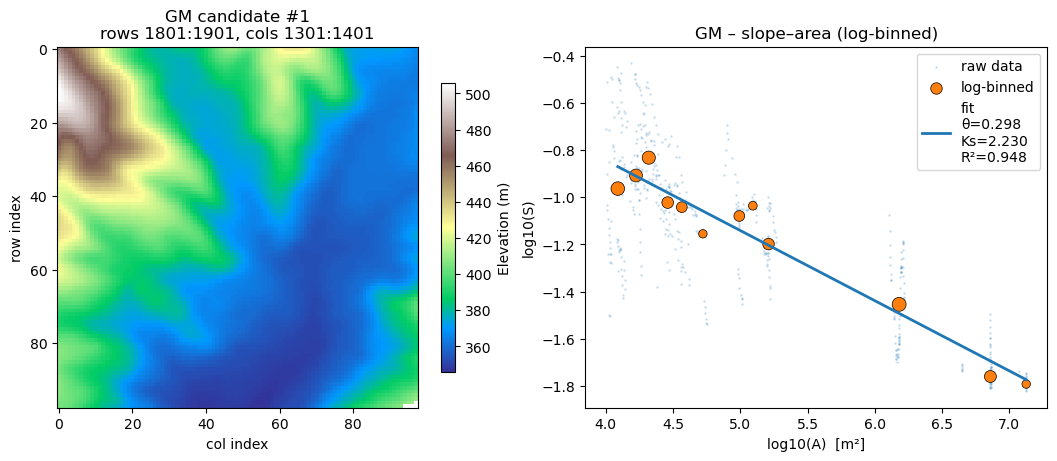


GM – candidate #2   (RMS = 0.261008)
Tile: rows 1901:2001, cols 1101:1201   (980 m × 980 m)

Results:
  Outlets: 17   Divides: 313   Valid curvatures: 290
  Median D: 1.29e-02 m²/yr  (IQR 8.8e-03–2.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.39  (Taylor  12.80)
  Ks (m):  2.018  (Taylor  1.900)
  θ      :  0.275  (Taylor  0.292)
  R²(sl–A fit): 0.940

Individual errors:
  Curvature:  +11.0%   Ks:   +6.2%   θ:   -5.9%
  3-term RMS error: 0.139432


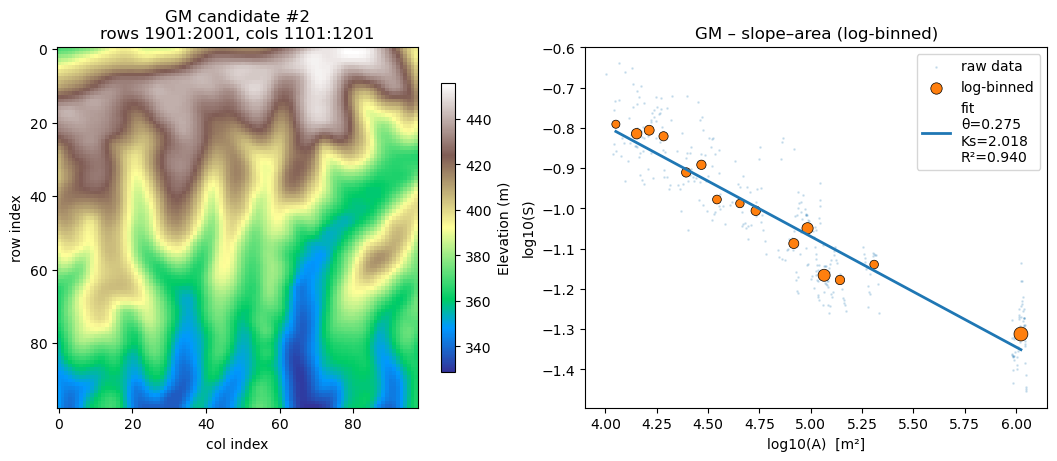


GM – candidate #3   (RMS = 0.348091)
Tile: rows 1901:2001, cols 901:1001   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 276   Valid curvatures: 266
  Median D: 1.22e-02 m²/yr  (IQR 8.6e-03–1.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.01  (Taylor  12.80)
  Ks (m):  1.374  (Taylor  1.900)
  θ      :  0.245  (Taylor  0.292)
  R²(sl–A fit): 0.853

Individual errors:
  Curvature:   +6.2%   Ks:  -27.7%   θ:  -15.9%
  3-term RMS error: 0.325403


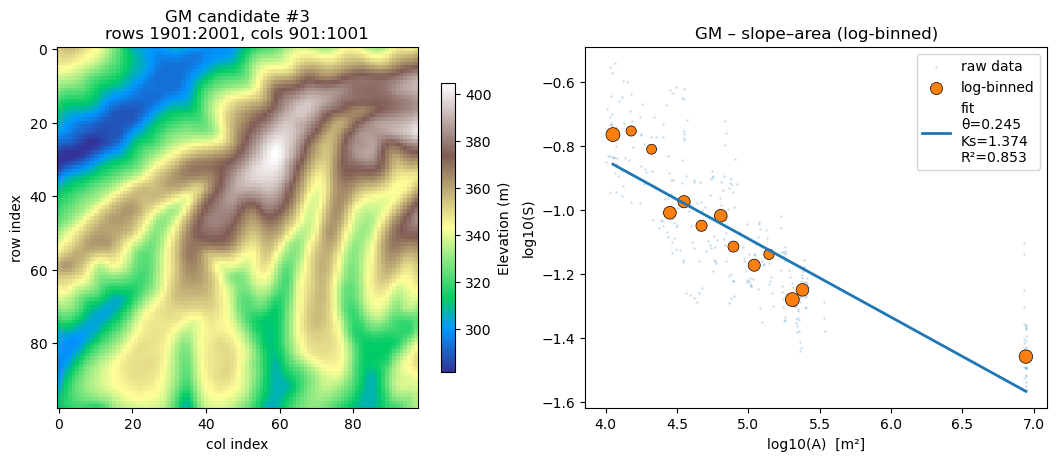


GM – candidate #4   (RMS = 0.372818)
Tile: rows 1901:2001, cols 1201:1301   (980 m × 980 m)

Results:
  Outlets: 20   Divides: 282   Valid curvatures: 248
  Median D: 1.00e-02 m²/yr  (IQR 7.0e-03–2.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -14.66  (Taylor  12.80)
  Ks (m):  2.229  (Taylor  1.900)
  θ      :  0.275  (Taylor  0.292)
  R²(sl–A fit): 0.961

Individual errors:
  Curvature:  -14.5%   Ks:  +17.3%   θ:   -5.9%
  3-term RMS error: 0.233592


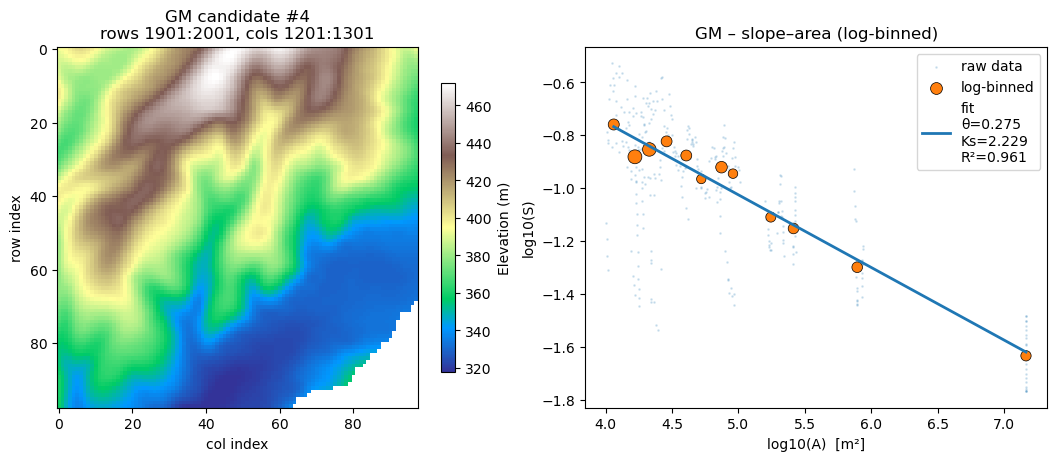


GM – candidate #5   (RMS = 0.411934)
Tile: rows 1901:2001, cols 801:901   (980 m × 980 m)

Results:
  Outlets: 20   Divides: 220   Valid curvatures: 205
  Median D: 1.33e-02 m²/yr  (IQR 8.5e-03–2.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.08  (Taylor  12.80)
  Ks (m):  1.421  (Taylor  1.900)
  θ      :  0.256  (Taylor  0.292)
  R²(sl–A fit): 0.934

Individual errors:
  Curvature:  +13.5%   Ks:  -25.2%   θ:  -12.4%
  3-term RMS error: 0.311606


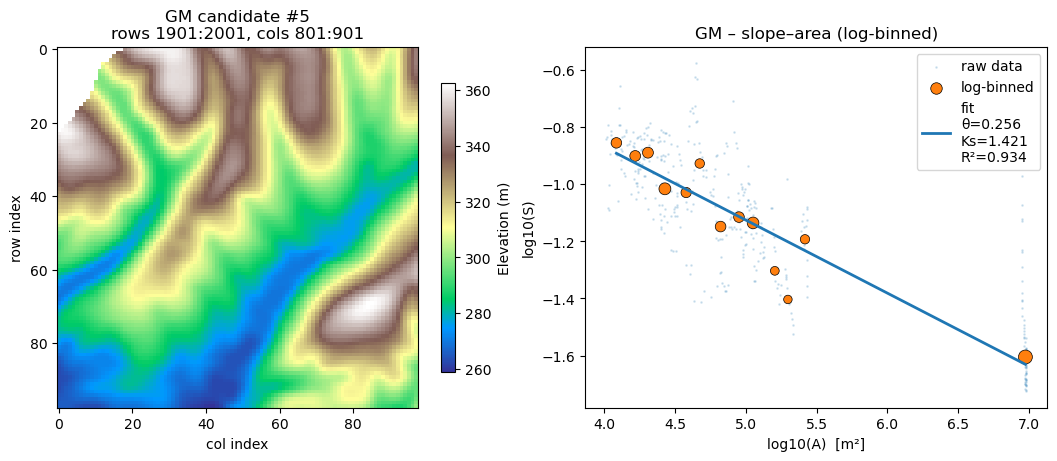


GM – candidate #6   (RMS = 0.416290)
Tile: rows 2001:2101, cols 1001:1101   (980 m × 980 m)

Results:
  Outlets: 18   Divides: 212   Valid curvatures: 191
  Median D: 1.26e-02 m²/yr  (IQR 6.9e-03–2.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.70  (Taylor  12.80)
  Ks (m):  1.256  (Taylor  1.900)
  θ      :  0.249  (Taylor  0.292)
  R²(sl–A fit): 0.811

Individual errors:
  Curvature:   +8.6%   Ks:  -33.9%   θ:  -14.7%
  3-term RMS error: 0.379130


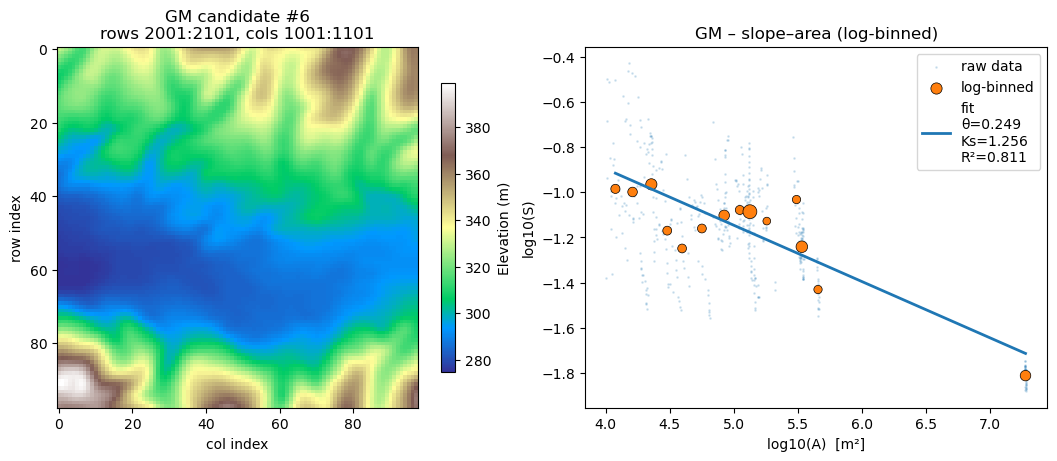


GM – candidate #7   (RMS = 0.467635)
Tile: rows 2001:2101, cols 801:901   (980 m × 980 m)

Results:
  Outlets: 28   Divides: 270   Valid curvatures: 238
  Median D: 1.21e-02 m²/yr  (IQR 7.9e-03–2.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.10  (Taylor  12.80)
  Ks (m):  1.105  (Taylor  1.900)
  θ      :  0.242  (Taylor  0.292)
  R²(sl–A fit): 0.818

Individual errors:
  Curvature:   +5.5%   Ks:  -41.8%   θ:  -17.0%
  3-term RMS error: 0.454676


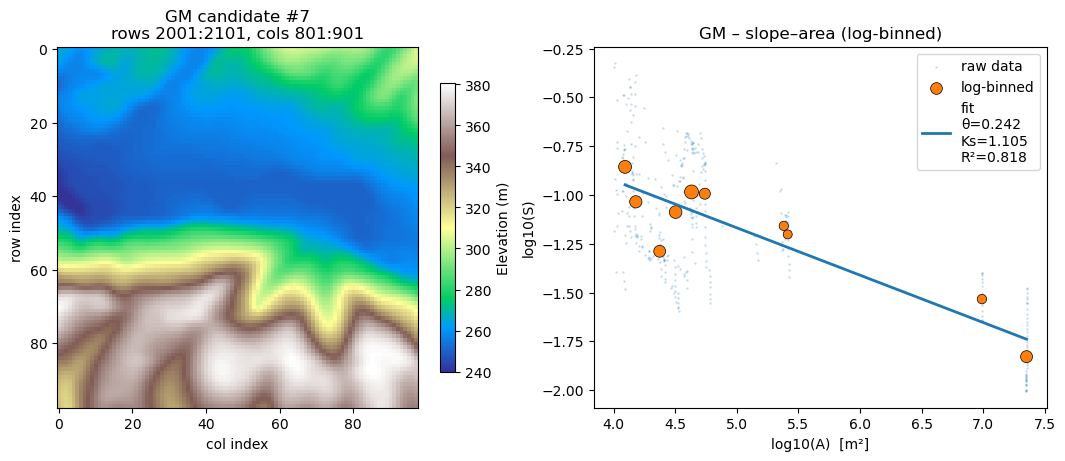


GM – candidate #8   (RMS = 0.502451)
Tile: rows 1701:1801, cols 1201:1301   (980 m × 980 m)

Results:
  Outlets: 19   Divides: 297   Valid curvatures: 271
  Median D: 1.41e-02 m²/yr  (IQR 9.3e-03–2.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.39  (Taylor  12.80)
  Ks (m):  1.459  (Taylor  1.900)
  θ      :  0.249  (Taylor  0.292)
  R²(sl–A fit): 0.665

Individual errors:
  Curvature:  +18.8%   Ks:  -23.2%   θ:  -14.8%
  3-term RMS error: 0.333341


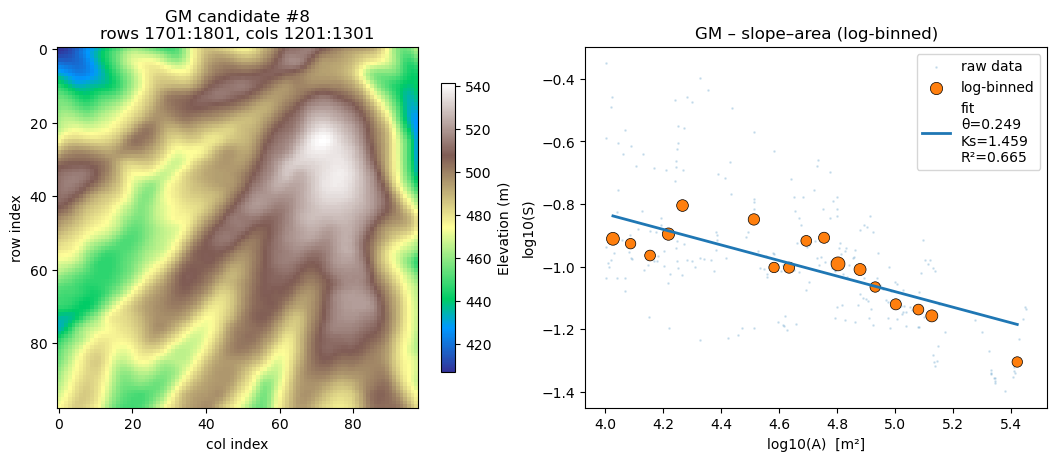


GM – candidate #9   (RMS = 0.661555)
Tile: rows 2401:2501, cols 501:601   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 276   Valid curvatures: 215
  Median D: 9.59e-03 m²/yr  (IQR 7.2e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.33  (Taylor  12.80)
  Ks (m):  2.823  (Taylor  1.900)
  θ      :  0.269  (Taylor  0.292)
  R²(sl–A fit): 0.953

Individual errors:
  Curvature:  -19.8%   Ks:  +48.6%   θ:   -7.7%
  3-term RMS error: 0.530070


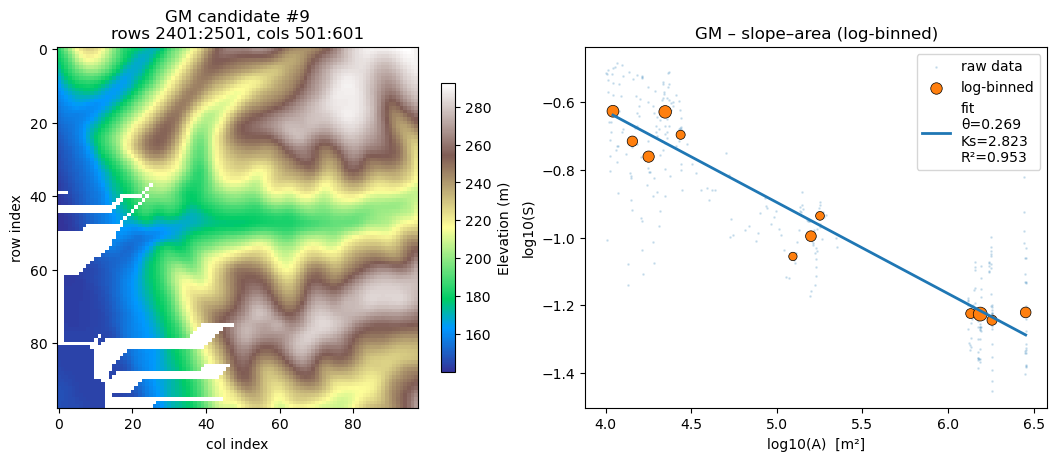


GM – candidate #10   (RMS = 0.666812)
Tile: rows 2101:2201, cols 601:701   (980 m × 980 m)

Results:
  Outlets: 22   Divides: 459   Valid curvatures: 428
  Median D: 1.62e-02 m²/yr  (IQR 1.0e-02–3.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.06  (Taylor  12.80)
  Ks (m):  1.673  (Taylor  1.900)
  θ      :  0.272  (Taylor  0.292)
  R²(sl–A fit): 0.802

Individual errors:
  Curvature:  +29.2%   Ks:  -11.9%   θ:   -6.8%
  3-term RMS error: 0.322479


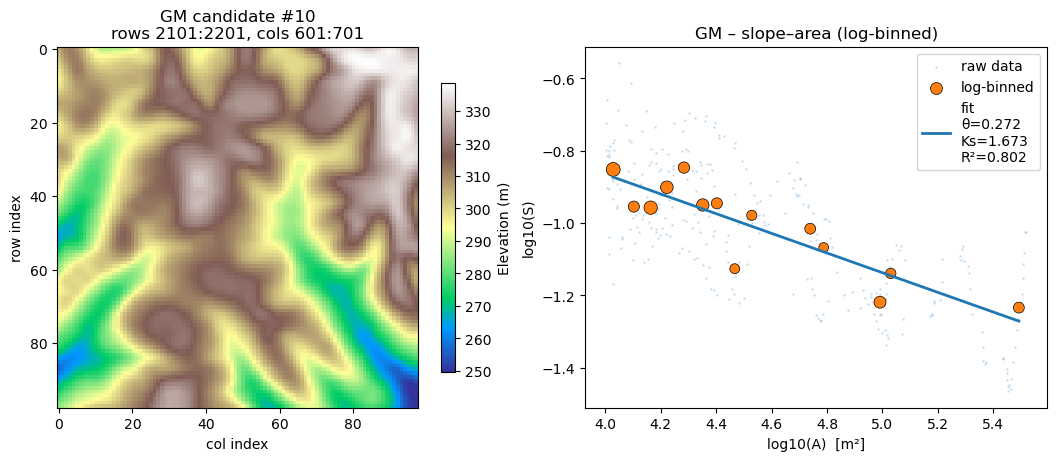


GM – candidate #11   (RMS = 0.717607)
Tile: rows 2301:2401, cols 501:601   (980 m × 980 m)

Results:
  Outlets: 19   Divides: 258   Valid curvatures: 247
  Median D: 9.66e-03 m²/yr  (IQR 7.4e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.21  (Taylor  12.80)
  Ks (m):  3.000  (Taylor  1.900)
  θ      :  0.279  (Taylor  0.292)
  R²(sl–A fit): 0.950

Individual errors:
  Curvature:  -18.9%   Ks:  +57.9%   θ:   -4.3%
  3-term RMS error: 0.610430


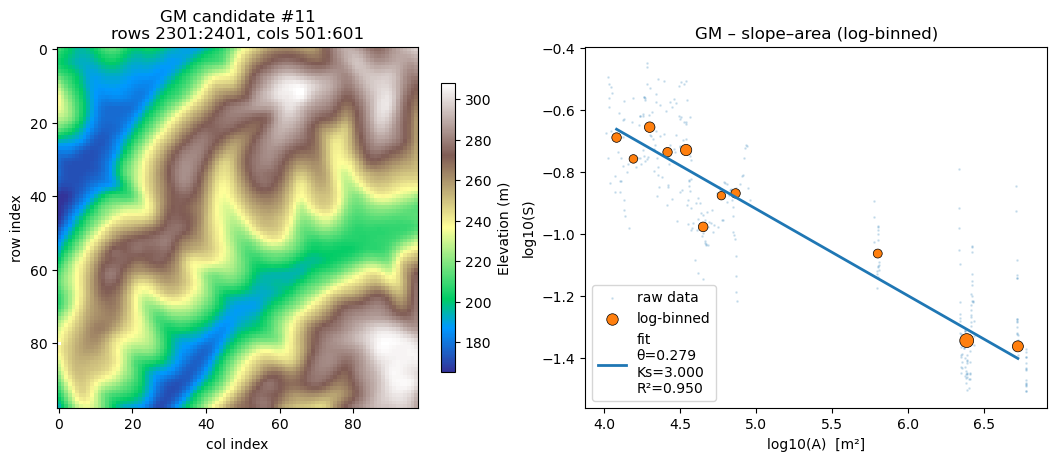


GM – candidate #12   (RMS = 0.835394)
Tile: rows 1801:1901, cols 1001:1101   (980 m × 980 m)

Results:
  Outlets: 27   Divides: 260   Valid curvatures: 247
  Median D: 9.84e-03 m²/yr  (IQR 7.3e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -14.95  (Taylor  12.80)
  Ks (m):  3.307  (Taylor  1.900)
  θ      :  0.320  (Taylor  0.292)
  R²(sl–A fit): 0.948

Individual errors:
  Curvature:  -16.8%   Ks:  +74.1%   θ:   +9.5%
  3-term RMS error: 0.765187


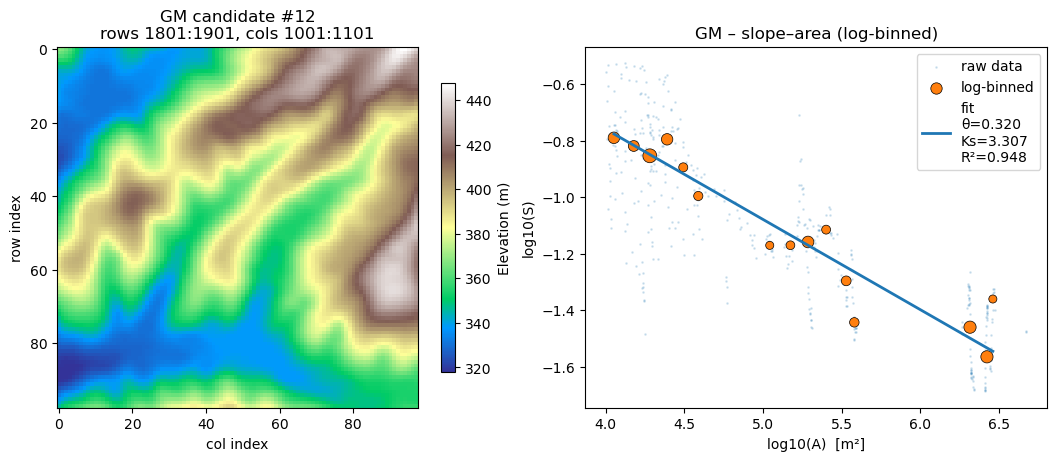


GM – candidate #13   (RMS = 0.962670)
Tile: rows 1601:1701, cols 1201:1301   (980 m × 980 m)

Results:
  Outlets: 27   Divides: 378   Valid curvatures: 346
  Median D: 1.07e-02 m²/yr  (IQR 7.8e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -13.77  (Taylor  12.80)
  Ks (m):  3.676  (Taylor  1.900)
  θ      :  0.338  (Taylor  0.292)
  R²(sl–A fit): 0.948

Individual errors:
  Curvature:   -7.5%   Ks:  +93.5%   θ:  +15.7%
  3-term RMS error: 0.950761


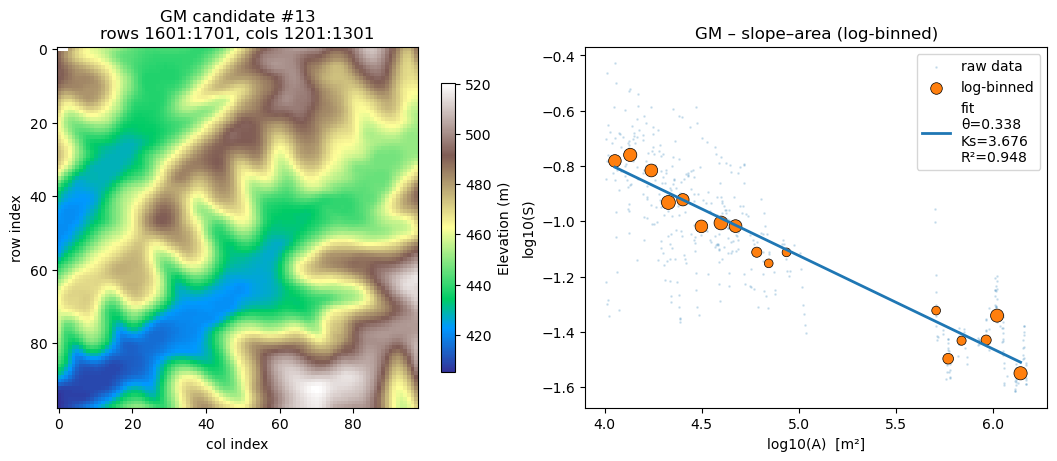


GM – candidate #14   (RMS = 1.006922)
Tile: rows 2201:2301, cols 801:901   (980 m × 980 m)

Results:
  Outlets: 27   Divides: 373   Valid curvatures: 340
  Median D: 2.01e-02 m²/yr  (IQR 1.3e-02–3.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.30  (Taylor  12.80)
  Ks (m):  2.460  (Taylor  1.900)
  θ      :  0.312  (Taylor  0.292)
  R²(sl–A fit): 0.916

Individual errors:
  Curvature:  +43.0%   Ks:  +29.5%   θ:   +6.8%
  3-term RMS error: 0.525355


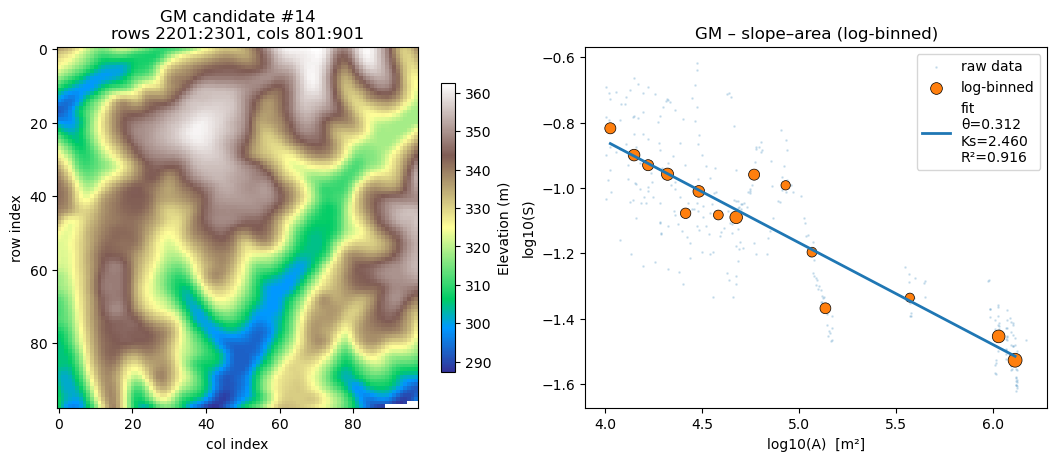


GM – candidate #15   (RMS = 1.039039)
Tile: rows 1701:1801, cols 1101:1201   (980 m × 980 m)

Results:
  Outlets: 35   Divides: 415   Valid curvatures: 385
  Median D: 1.20e-02 m²/yr  (IQR 8.4e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.26  (Taylor  12.80)
  Ks (m):  3.851  (Taylor  1.900)
  θ      :  0.330  (Taylor  0.292)
  R²(sl–A fit): 0.937

Individual errors:
  Curvature:   +4.2%   Ks: +102.7%   θ:  +12.9%
  3-term RMS error: 1.035569


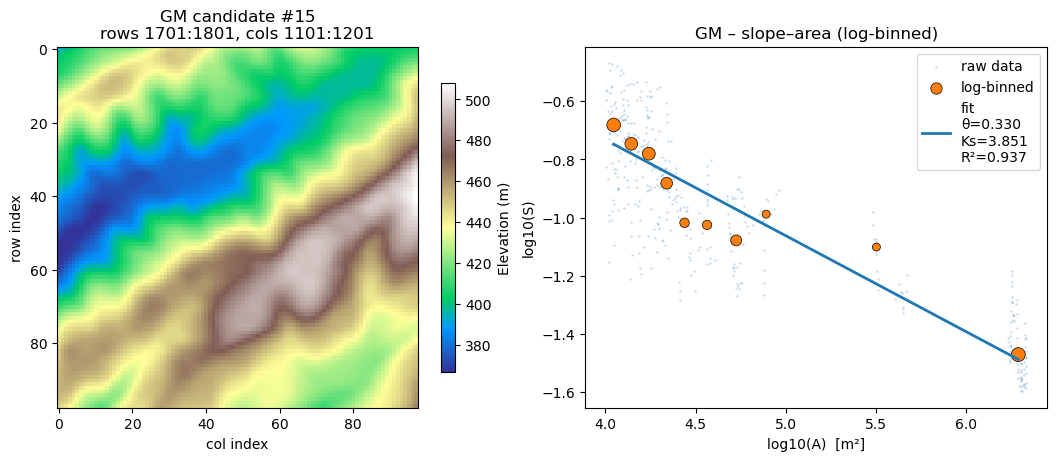


GM – candidate #16   (RMS = 1.312631)
Tile: rows 2001:2101, cols 901:1001   (980 m × 980 m)

Results:
  Outlets: 27   Divides: 231   Valid curvatures: 211
  Median D: 2.26e-02 m²/yr  (IQR 9.3e-03–5.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.50  (Taylor  12.80)
  Ks (m):  0.683  (Taylor  1.900)
  θ      :  0.200  (Taylor  0.292)
  R²(sl–A fit): 0.889

Individual errors:
  Curvature:  +49.2%   Ks:  -64.1%   θ:  -31.6%
  3-term RMS error: 0.867728


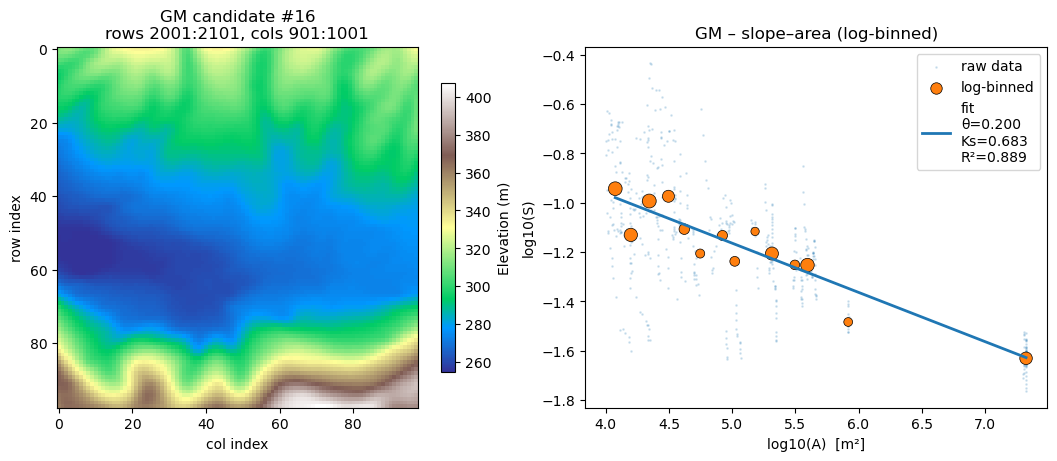


GM – candidate #17   (RMS = 1.449408)
Tile: rows 2201:2301, cols 501:601   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 296   Valid curvatures: 274
  Median D: 1.29e-02 m²/yr  (IQR 9.2e-03–2.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.43  (Taylor  12.80)
  Ks (m):  4.603  (Taylor  1.900)
  θ      :  0.332  (Taylor  0.292)
  R²(sl–A fit): 0.929

Individual errors:
  Curvature:  +10.7%   Ks: +142.3%   θ:  +13.8%
  3-term RMS error: 1.433546


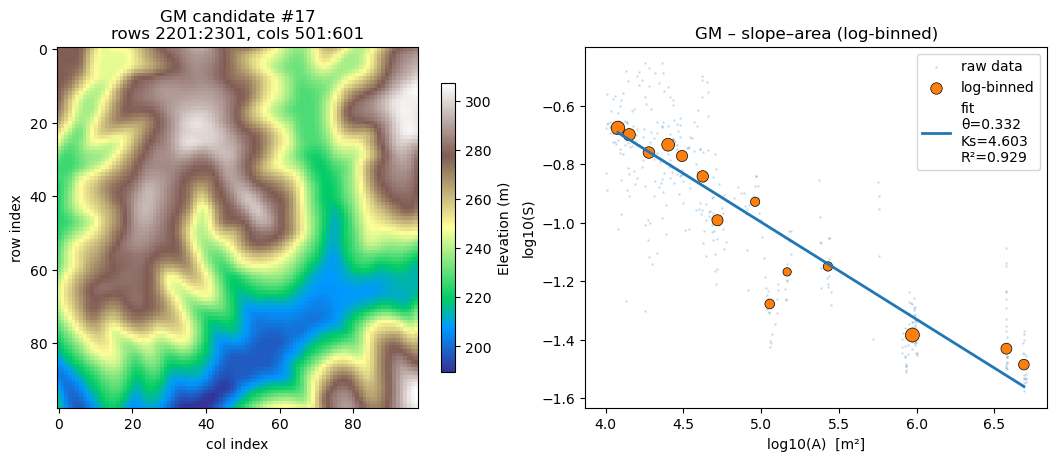


GM – candidate #18   (RMS = 1.545281)
Tile: rows 2101:2201, cols 701:801   (980 m × 980 m)

Results:
  Outlets: 18   Divides: 282   Valid curvatures: 265
  Median D: 1.15e-02 m²/yr  (IQR 7.6e-03–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.74  (Taylor  12.80)
  Ks (m):  4.804  (Taylor  1.900)
  θ      :  0.358  (Taylor  0.292)
  R²(sl–A fit): 0.956

Individual errors:
  Curvature:   +0.5%   Ks: +152.9%   θ:  +22.6%
  3-term RMS error: 1.545254


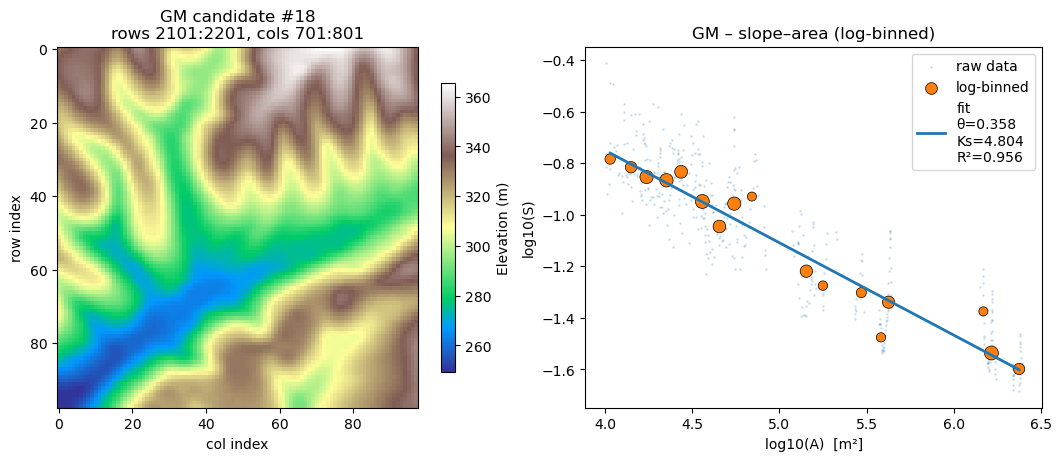


GM – candidate #19   (RMS = 1.626342)
Tile: rows 1701:1801, cols 1401:1501   (980 m × 980 m)

Results:
  Outlets: 27   Divides: 252   Valid curvatures: 223
  Median D: 7.96e-03 m²/yr  (IQR 5.8e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -18.47  (Taylor  12.80)
  Ks (m):  4.321  (Taylor  1.900)
  θ      :  0.351  (Taylor  0.292)
  R²(sl–A fit): 0.896

Individual errors:
  Curvature:  -44.3%   Ks: +127.4%   θ:  +20.4%
  3-term RMS error: 1.364137


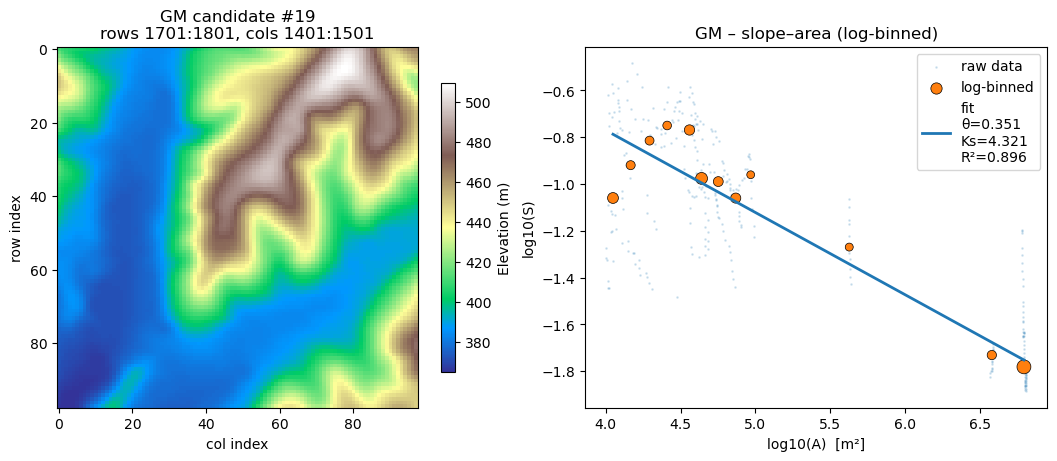


GM – candidate #20   (RMS = 1.707497)
Tile: rows 2001:2101, cols 701:801   (980 m × 980 m)

Results:
  Outlets: 21   Divides: 344   Valid curvatures: 318
  Median D: 1.82e-02 m²/yr  (IQR 9.9e-03–3.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -8.08  (Taylor  12.80)
  Ks (m):  4.710  (Taylor  1.900)
  θ      :  0.355  (Taylor  0.292)
  R²(sl–A fit): 0.439

Individual errors:
  Curvature:  +36.9%   Ks: +147.9%   θ:  +21.7%
  3-term RMS error: 1.539872


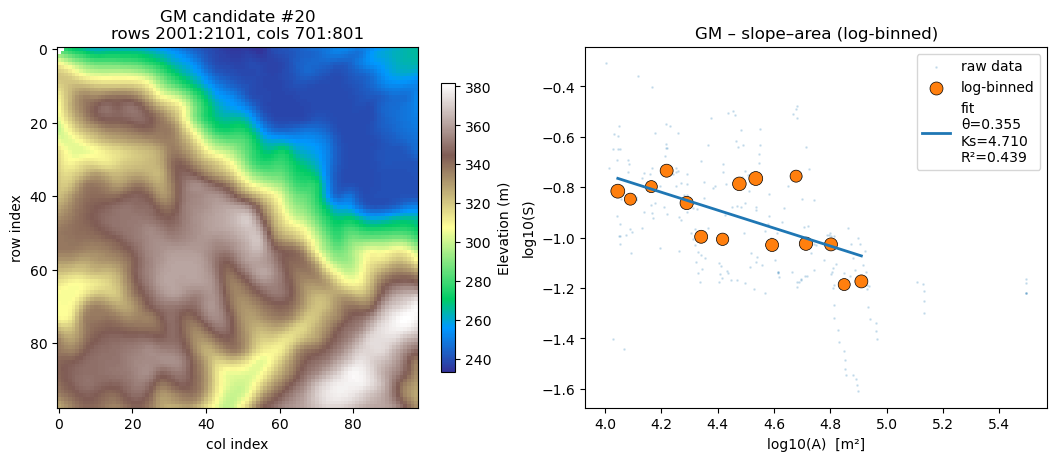


GM – candidate #21   (RMS = 1.790526)
Tile: rows 2201:2301, cols 701:801   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 330   Valid curvatures: 299
  Median D: 1.64e-02 m²/yr  (IQR 9.8e-03–3.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -8.95  (Taylor  12.80)
  Ks (m):  5.020  (Taylor  1.900)
  θ      :  0.362  (Taylor  0.292)
  R²(sl–A fit): 0.866

Individual errors:
  Curvature:  +30.1%   Ks: +164.2%   θ:  +24.1%
  3-term RMS error: 1.686519


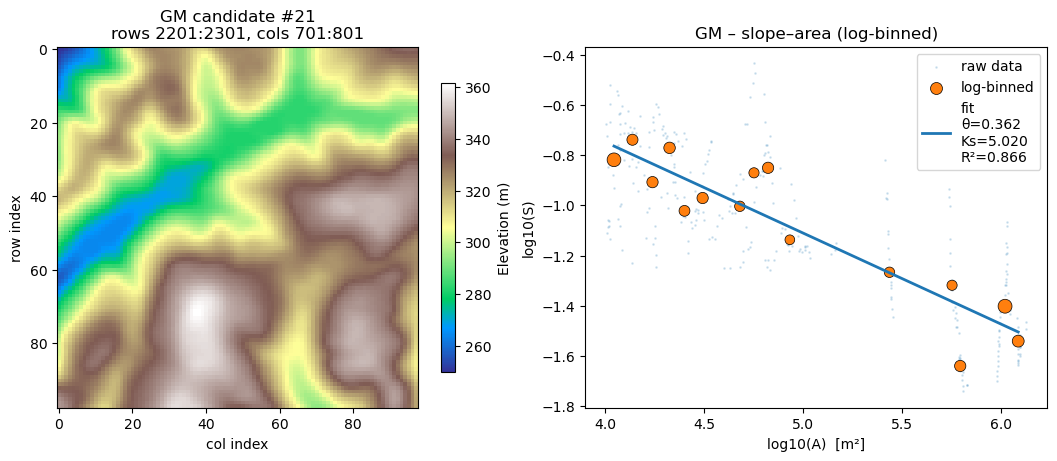


GM – candidate #22   (RMS = 1.835196)
Tile: rows 1901:2001, cols 1001:1101   (980 m × 980 m)

Results:
  Outlets: 16   Divides: 309   Valid curvatures: 292
  Median D: 1.29e-02 m²/yr  (IQR 1.0e-02–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -11.39  (Taylor  12.80)
  Ks (m):  5.319  (Taylor  1.900)
  θ      :  0.369  (Taylor  0.292)
  R²(sl–A fit): 0.761

Individual errors:
  Curvature:  +11.0%   Ks: +179.9%   θ:  +26.3%
  3-term RMS error: 1.821962


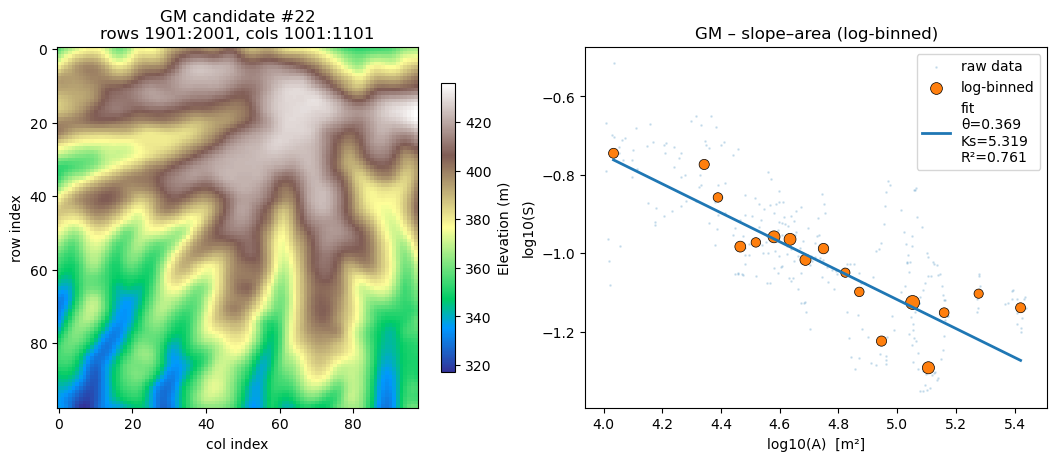


GM – candidate #23   (RMS = 1.979643)
Tile: rows 1801:1901, cols 1101:1201   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 218   Valid curvatures: 202
  Median D: 1.11e-02 m²/yr  (IQR 6.9e-03–1.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -13.30  (Taylor  12.80)
  Ks (m):  5.637  (Taylor  1.900)
  θ      :  0.352  (Taylor  0.292)
  R²(sl–A fit): 0.964

Individual errors:
  Curvature:   -3.9%   Ks: +196.7%   θ:  +20.5%
  3-term RMS error: 1.978106


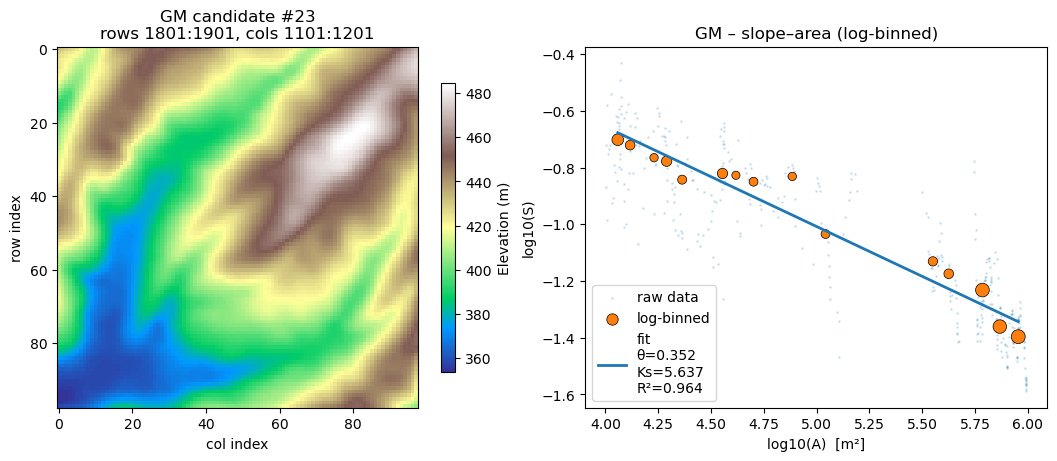


GM – candidate #24   (RMS = 2.096103)
Tile: rows 1801:1901, cols 1201:1301   (980 m × 980 m)

Results:
  Outlets: 25   Divides: 360   Valid curvatures: 347
  Median D: 1.52e-02 m²/yr  (IQR 9.9e-03–2.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.68  (Taylor  12.80)
  Ks (m):  5.718  (Taylor  1.900)
  θ      :  0.362  (Taylor  0.292)
  R²(sl–A fit): 0.927

Individual errors:
  Curvature:  +24.4%   Ks: +201.0%   θ:  +23.9%
  3-term RMS error: 2.038539


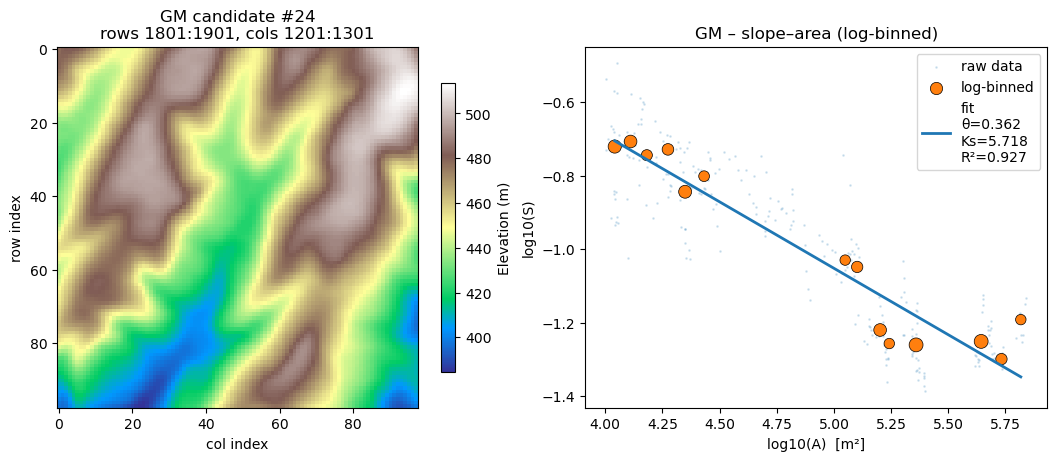


GM – candidate #25   (RMS = 2.262184)
Tile: rows 2301:2401, cols 701:801   (980 m × 980 m)

Results:
  Outlets: 18   Divides: 297   Valid curvatures: 275
  Median D: 1.53e-02 m²/yr  (IQR 8.2e-03–2.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.64  (Taylor  12.80)
  Ks (m):  6.026  (Taylor  1.900)
  θ      :  0.383  (Taylor  0.292)
  R²(sl–A fit): 0.906

Individual errors:
  Curvature:  +24.7%   Ks: +217.1%   θ:  +31.2%
  3-term RMS error: 2.207606


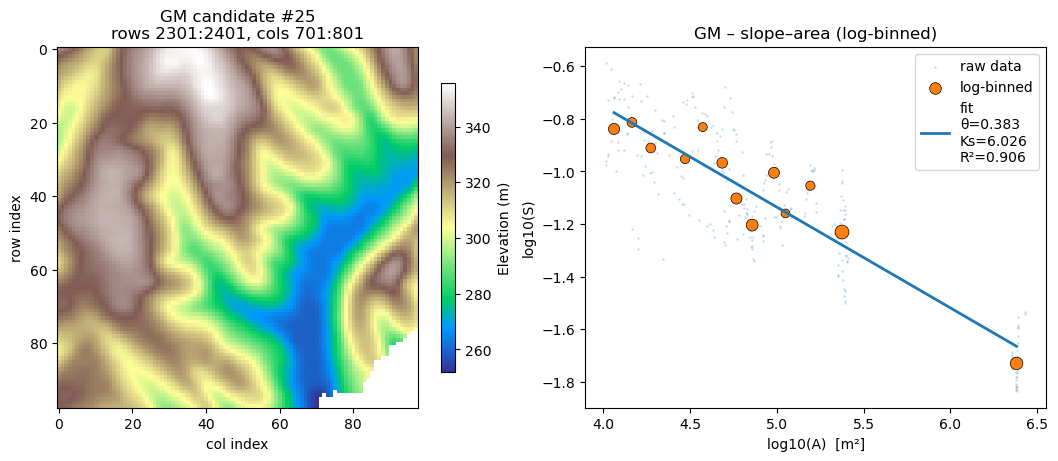


GM – candidate #26   (RMS = 2.309752)
Tile: rows 2201:2301, cols 601:701   (980 m × 980 m)

Results:
  Outlets: 22   Divides: 333   Valid curvatures: 307
  Median D: 1.07e-02 m²/yr  (IQR 8.0e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -13.69  (Taylor  12.80)
  Ks (m):  6.257  (Taylor  1.900)
  θ      :  0.358  (Taylor  0.292)
  R²(sl–A fit): 0.992

Individual errors:
  Curvature:   -7.0%   Ks: +229.3%   θ:  +22.7%
  3-term RMS error: 2.305524


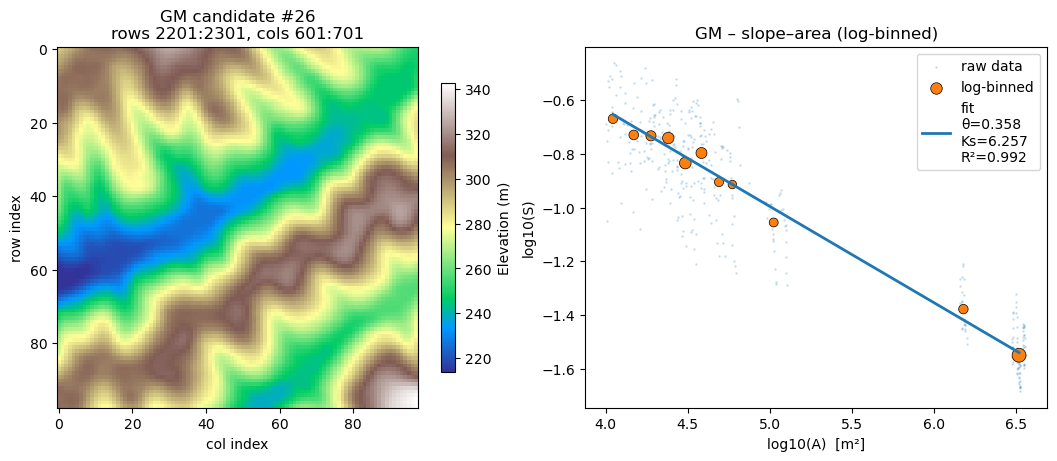


GM – candidate #27   (RMS = 2.537075)
Tile: rows 2101:2201, cols 801:901   (980 m × 980 m)

Results:
  Outlets: 18   Divides: 258   Valid curvatures: 235
  Median D: 1.61e-02 m²/yr  (IQR 1.1e-02–2.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -9.11  (Taylor  12.80)
  Ks (m):  6.511  (Taylor  1.900)
  θ      :  0.398  (Taylor  0.292)
  R²(sl–A fit): 0.892

Individual errors:
  Curvature:  +28.8%   Ks: +242.7%   θ:  +36.3%
  3-term RMS error: 2.470801


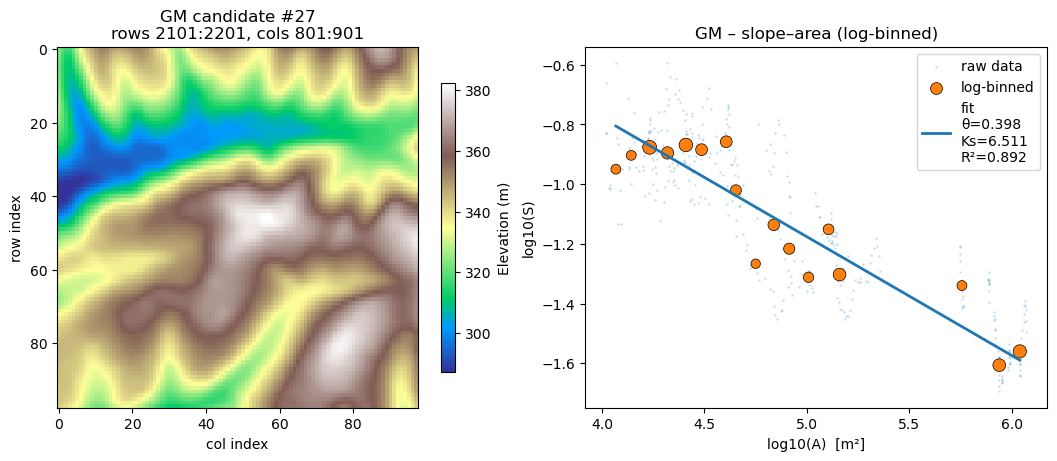


GM – candidate #28   (RMS = 2.680883)
Tile: rows 1401:1501, cols 1401:1501   (980 m × 980 m)

Results:
  Outlets: 21   Divides: 297   Valid curvatures: 263
  Median D: 9.61e-03 m²/yr  (IQR 6.9e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.30  (Taylor  12.80)
  Ks (m):  6.915  (Taylor  1.900)
  θ      :  0.342  (Taylor  0.292)
  R²(sl–A fit): 0.813

Individual errors:
  Curvature:  -19.5%   Ks: +264.0%   θ:  +17.0%
  3-term RMS error: 2.652350


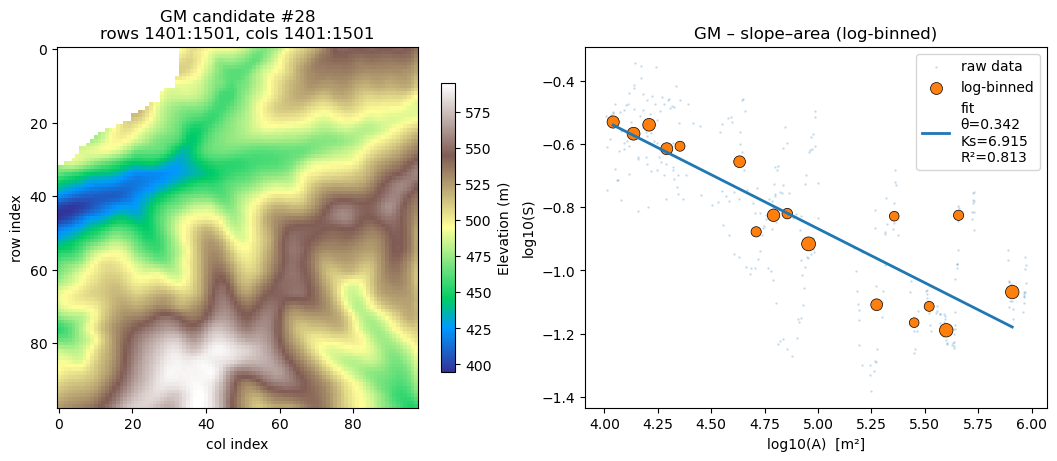


GM – candidate #29   (RMS = 2.757070)
Tile: rows 1501:1601, cols 1501:1601   (980 m × 980 m)

Results:
  Outlets: 25   Divides: 425   Valid curvatures: 403
  Median D: 6.54e-03 m²/yr  (IQR 5.2e-03–9.9e-03)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -22.48  (Taylor  12.80)
  Ks (m):  6.031  (Taylor  1.900)
  θ      :  0.327  (Taylor  0.292)
  R²(sl–A fit): 0.670

Individual errors:
  Curvature:  -75.6%   Ks: +217.4%   θ:  +12.0%
  3-term RMS error: 2.305070


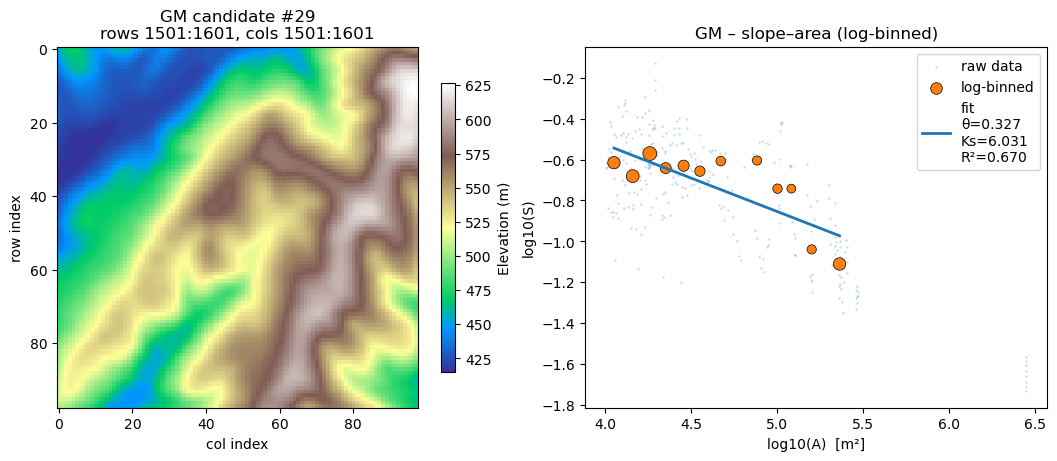


GM – candidate #30   (RMS = 2.848351)
Tile: rows 2301:2401, cols 601:701   (980 m × 980 m)

Results:
  Outlets: 18   Divides: 254   Valid curvatures: 239
  Median D: 1.43e-02 m²/yr  (IQR 1.0e-02–2.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -10.27  (Taylor  12.80)
  Ks (m):  7.218  (Taylor  1.900)
  θ      :  0.375  (Taylor  0.292)
  R²(sl–A fit): 0.887

Individual errors:
  Curvature:  +19.8%   Ks: +279.9%   θ:  +28.6%
  3-term RMS error: 2.820689


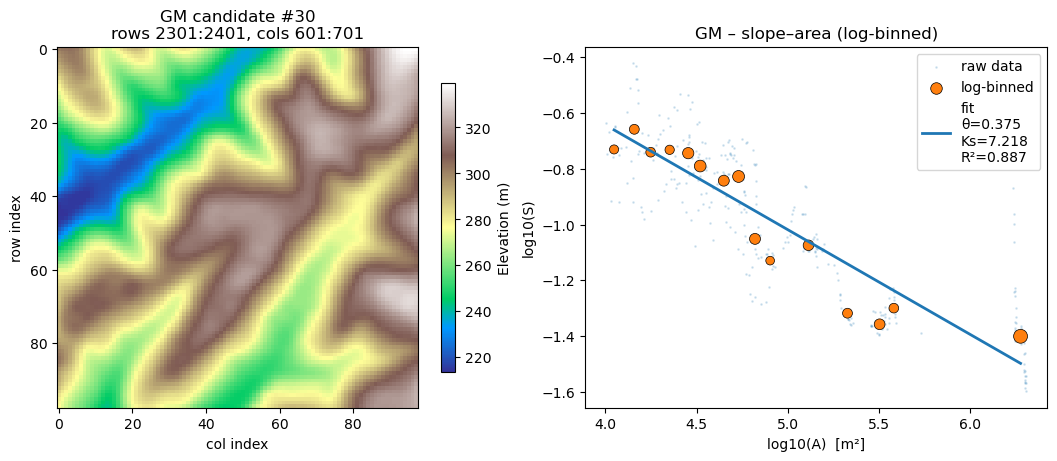


GM – candidate #31   (RMS = 3.307123)
Tile: rows 1601:1701, cols 1401:1501   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 263   Valid curvatures: 251
  Median D: 9.56e-03 m²/yr  (IQR 6.5e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.38  (Taylor  12.80)
  Ks (m):  8.090  (Taylor  1.900)
  θ      :  0.392  (Taylor  0.292)
  R²(sl–A fit): 0.973

Individual errors:
  Curvature:  -20.2%   Ks: +325.8%   θ:  +34.3%
  3-term RMS error: 3.282393


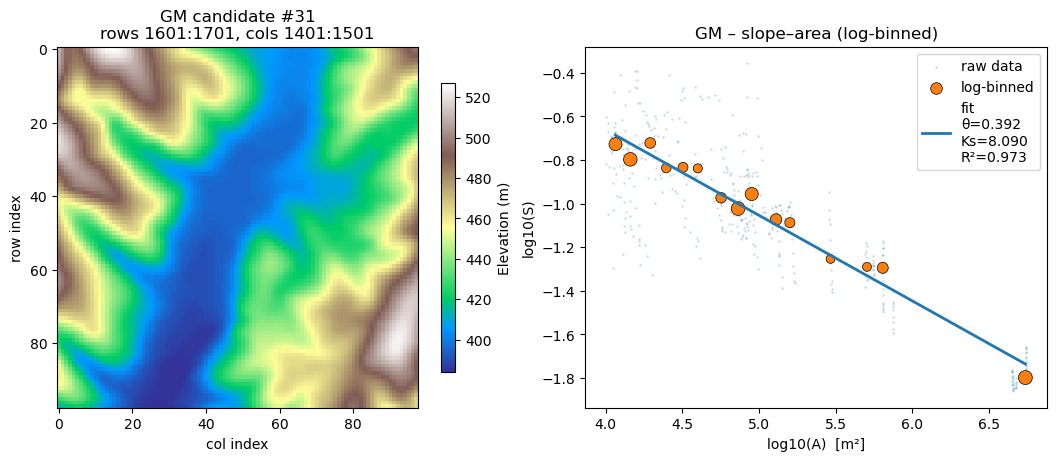


GM – candidate #32   (RMS = 3.968435)
Tile: rows 1401:1501, cols 1501:1601   (980 m × 980 m)

Results:
  Outlets: 24   Divides: 277   Valid curvatures: 248
  Median D: 8.75e-03 m²/yr  (IQR 6.0e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -16.79  (Taylor  12.80)
  Ks (m):  9.300  (Taylor  1.900)
  θ      :  0.381  (Taylor  0.292)
  R²(sl–A fit): 0.818

Individual errors:
  Curvature:  -31.2%   Ks: +389.5%   θ:  +30.3%
  3-term RMS error: 3.919103


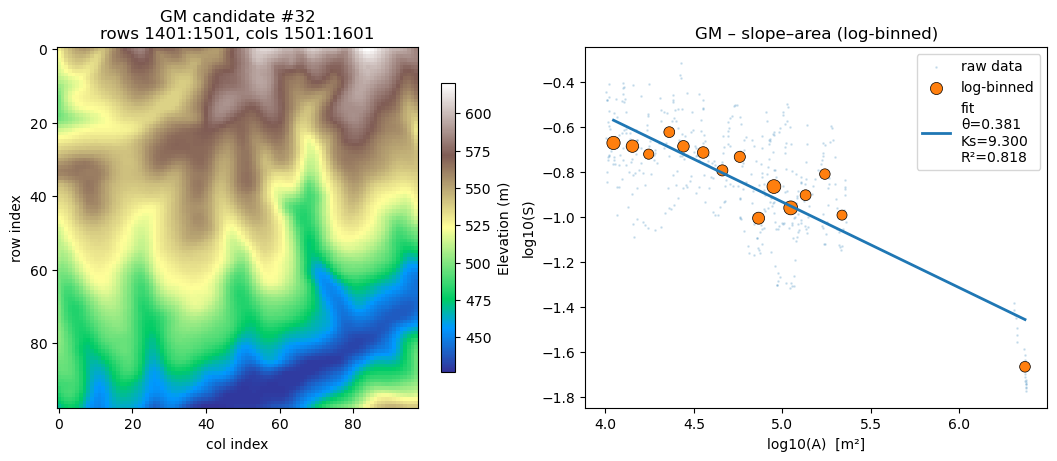


GM – candidate #33   (RMS = 4.664128)
Tile: rows 1701:1801, cols 1301:1401   (980 m × 980 m)

Results:
  Outlets: 22   Divides: 324   Valid curvatures: 305
  Median D: 1.17e-02 m²/yr  (IQR 8.2e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -12.53  (Taylor  12.80)
  Ks (m): 10.726  (Taylor  1.900)
  θ      :  0.414  (Taylor  0.292)
  R²(sl–A fit): 0.917

Individual errors:
  Curvature:   +2.1%   Ks: +464.5%   θ:  +41.9%
  3-term RMS error: 4.663931


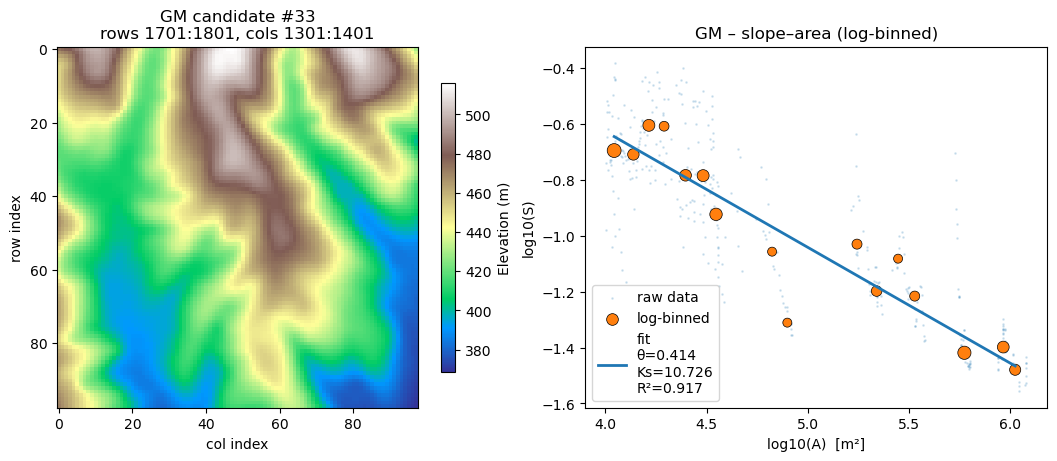


GM – candidate #34   (RMS = 7.574973)
Tile: rows 1601:1701, cols 1501:1601   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 289   Valid curvatures: 279
  Median D: 7.30e-03 m²/yr  (IQR 5.6e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -20.13  (Taylor  12.80)
  Ks (m): 16.050  (Taylor  1.900)
  θ      :  0.445  (Taylor  0.292)
  R²(sl–A fit): 0.959

Individual errors:
  Curvature:  -57.3%   Ks: +744.8%   θ:  +52.3%
  3-term RMS error: 7.487837


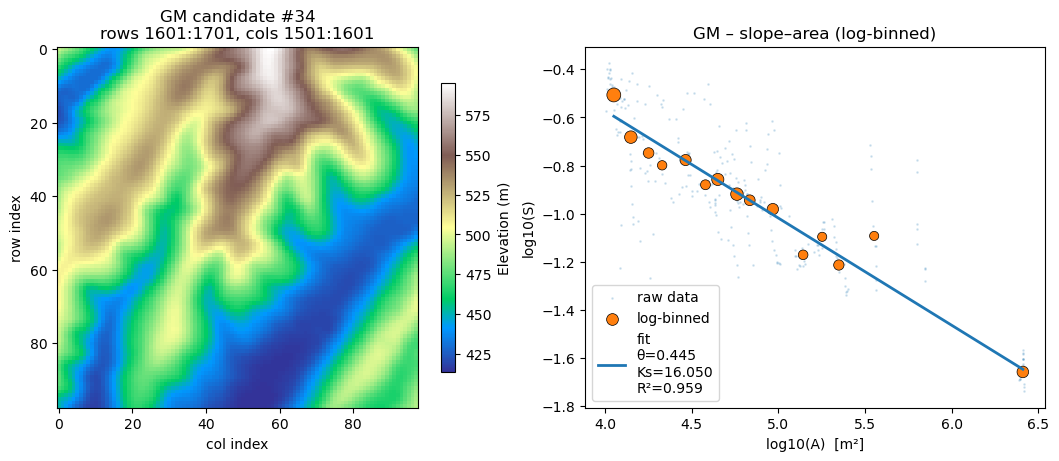


GM – candidate #35   (RMS = 7.974726)
Tile: rows 1501:1601, cols 1401:1501   (980 m × 980 m)

Results:
  Outlets: 20   Divides: 270   Valid curvatures: 258
  Median D: 9.51e-03 m²/yr  (IQR 7.4e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.46  (Taylor  12.80)
  Ks (m): 16.997  (Taylor  1.900)
  θ      :  0.435  (Taylor  0.292)
  R²(sl–A fit): 0.948

Individual errors:
  Curvature:  -20.8%   Ks: +794.6%   θ:  +49.1%
  3-term RMS error: 7.963898


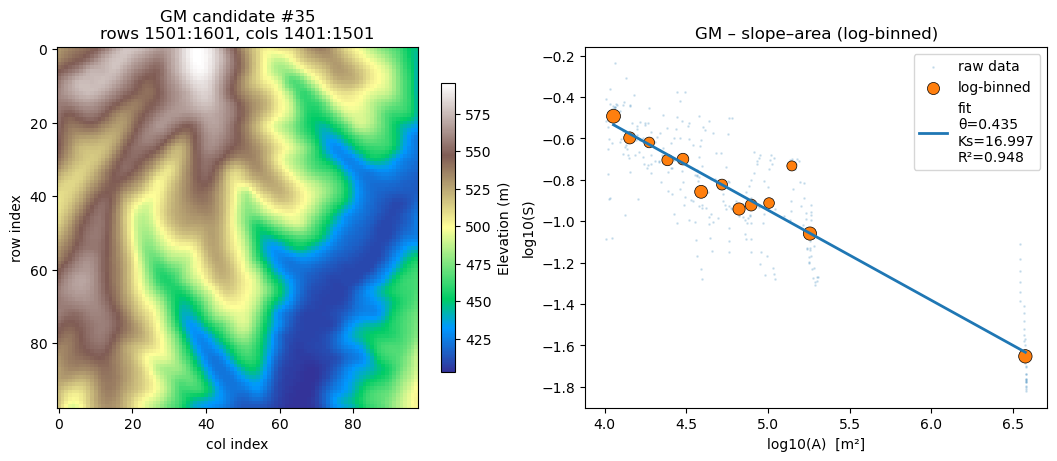


GM – candidate #36   (RMS = 9.390827)
Tile: rows 2101:2201, cols 901:1001   (980 m × 980 m)

Results:
  Outlets: 14   Divides: 200   Valid curvatures: 186
  Median D: 2.00e-02 m²/yr  (IQR 1.3e-02–3.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.36  (Taylor  12.80)
  Ks (m): 19.600  (Taylor  1.900)
  θ      :  0.498  (Taylor  0.292)
  R²(sl–A fit): 0.953

Individual errors:
  Curvature:  +42.5%   Ks: +931.6%   θ:  +70.6%
  3-term RMS error: 9.352346


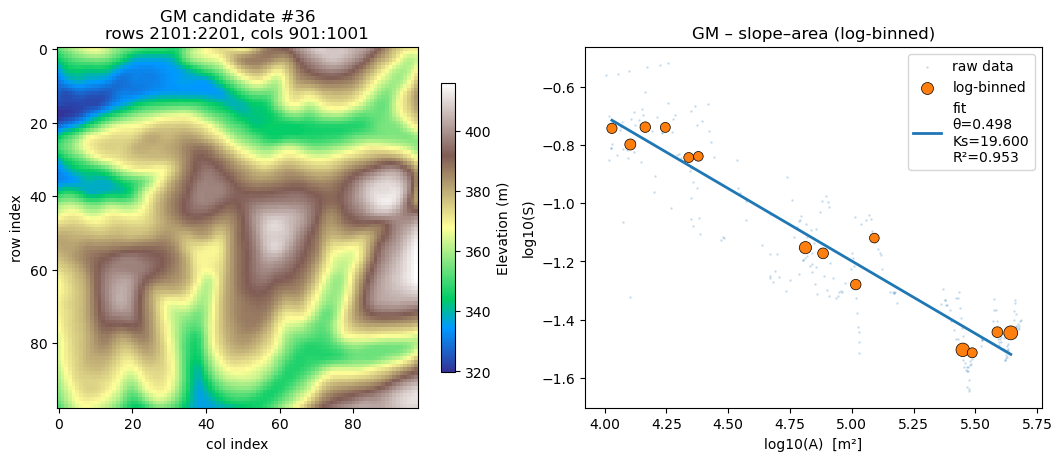


GM – candidate #37   (RMS = 9.502847)
Tile: rows 1601:1701, cols 1301:1401   (980 m × 980 m)

Results:
  Outlets: 20   Divides: 305   Valid curvatures: 292
  Median D: 9.19e-03 m²/yr  (IQR 7.0e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -16.00  (Taylor  12.80)
  Ks (m): 19.883  (Taylor  1.900)
  θ      :  0.478  (Taylor  0.292)
  R²(sl–A fit): 0.874

Individual errors:
  Curvature:  -25.0%   Ks: +946.5%   θ:  +63.8%
  3-term RMS error: 9.489683


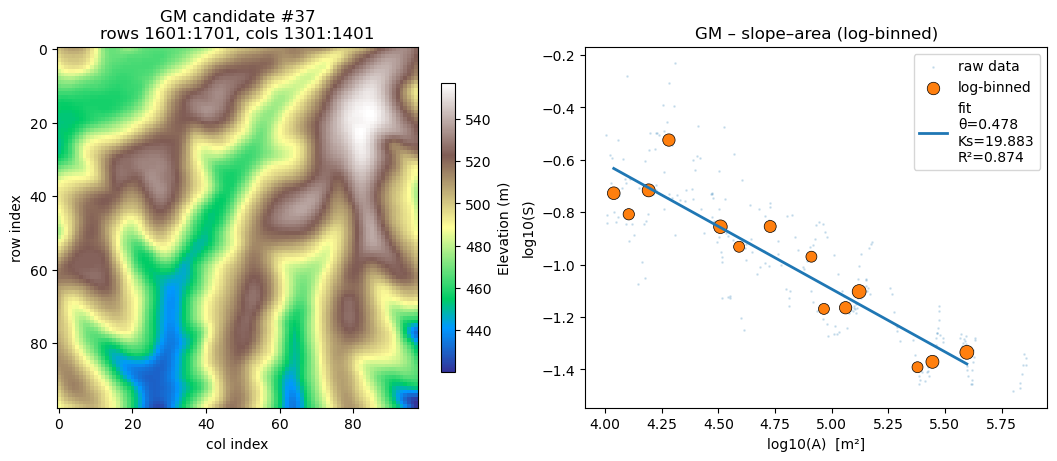


GM – candidate #38   (RMS = 10.428258)
Tile: rows 1501:1601, cols 1301:1401   (980 m × 980 m)

Results:
  Outlets: 22   Divides: 348   Valid curvatures: 330
  Median D: 9.76e-03 m²/yr  (IQR 7.1e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -15.06  (Taylor  12.80)
  Ks (m): 21.653  (Taylor  1.900)
  θ      :  0.500  (Taylor  0.292)
  R²(sl–A fit): 0.914

Individual errors:
  Curvature:  -17.6%   Ks: +1039.6%   θ:  +71.3%
  3-term RMS error: 10.422284


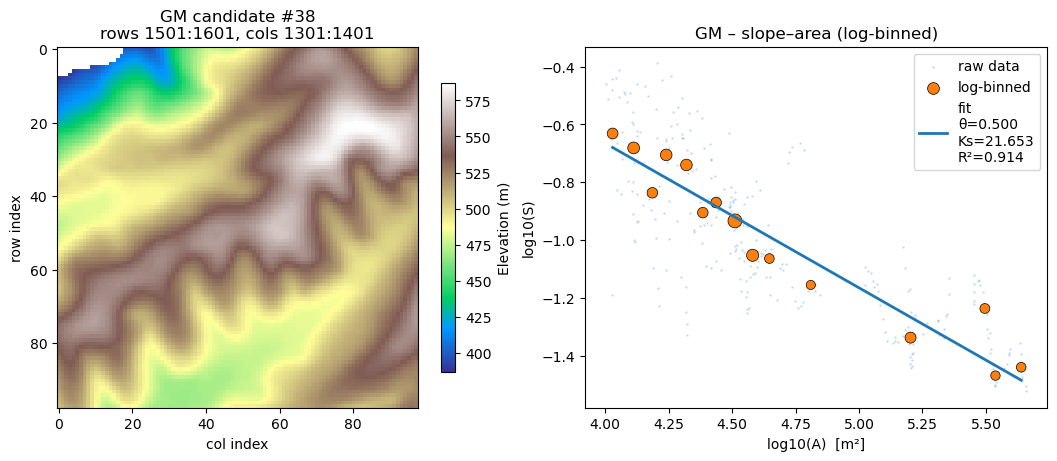


GM – candidate #39   (RMS = 13.182975)
Tile: rows 1401:1501, cols 1601:1701   (980 m × 980 m)

Results:
  Outlets: 23   Divides: 257   Valid curvatures: 248
  Median D: 7.96e-03 m²/yr  (IQR 5.5e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -18.46  (Taylor  12.80)
  Ks (m): 26.851  (Taylor  1.900)
  θ      :  0.467  (Taylor  0.292)
  R²(sl–A fit): 0.907

Individual errors:
  Curvature:  -44.2%   Ks: +1313.2%   θ:  +59.9%
  3-term RMS error: 13.153315


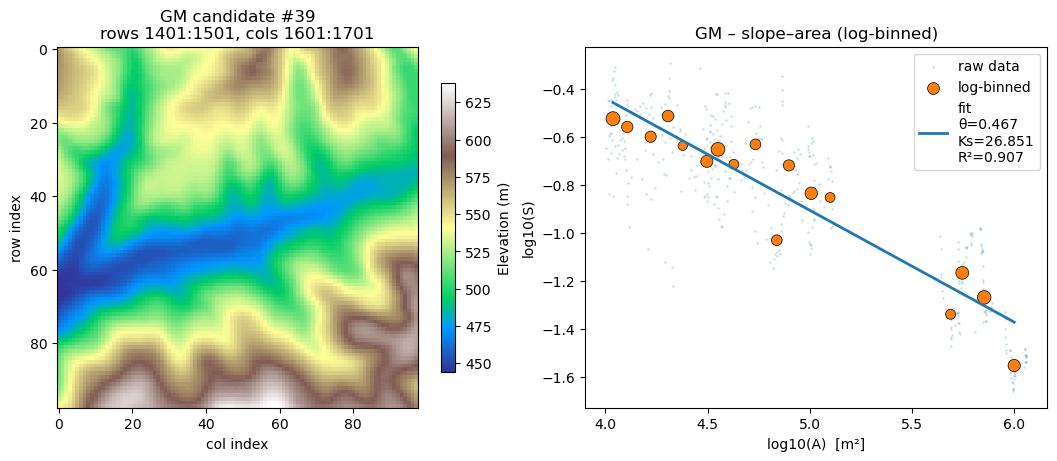


GM – candidate #40   (RMS = 16.254177)
Tile: rows 1501:1601, cols 1601:1701   (980 m × 980 m)

Results:
  Outlets: 20   Divides: 293   Valid curvatures: 286
  Median D: 5.73e-03 m²/yr  (IQR 4.3e-03–7.6e-03)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹): -25.66  (Taylor  12.80)
  Ks (m): 32.460  (Taylor  1.900)
  θ      :  0.487  (Taylor  0.292)
  R²(sl–A fit): 0.874

Individual errors:
  Curvature: -100.5%   Ks: +1608.4%   θ:  +66.8%
  3-term RMS error: 16.129522


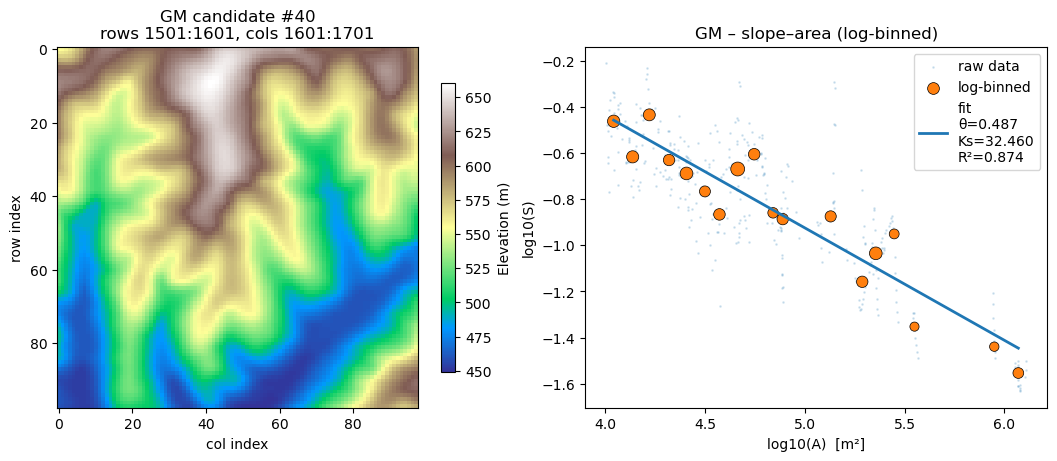

Loaded AP dataset: (1314, 1801) pixels

AP – candidate #1   (RMS = 0.123920)
Tile: rows 232:265, cols 1321:1354   (930 m × 930 m)

Results:
  Outlets: 3   Divides: 29   Valid curvatures: 28
  Median D: 9.61e-03 m²/yr  (IQR 7.7e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.73  (Taylor   5.93)
  Ks (m): 43.736  (Taylor 47.200)
  θ      :  0.576  (Taylor  0.540)
  R²(sl–A fit): 0.569

Individual errors:
  Curvature:   +3.4%   Ks:   -7.3%   θ:   +6.6%
  3-term RMS error: 0.104124


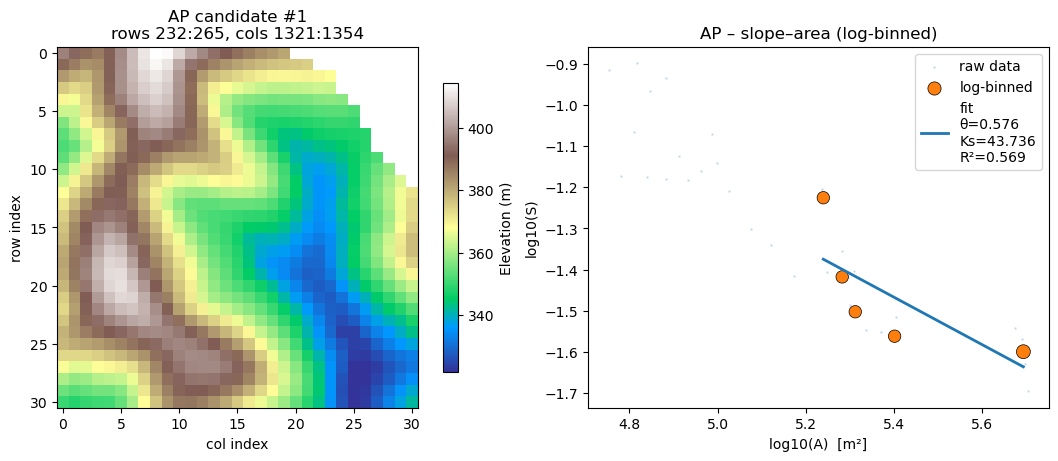


AP – candidate #2   (RMS = 0.126246)
Tile: rows 232:265, cols 793:826   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 40   Valid curvatures: 38
  Median D: 9.71e-03 m²/yr  (IQR 8.0e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.67  (Taylor   5.93)
  Ks (m): 43.821  (Taylor 47.200)
  θ      :  0.556  (Taylor  0.540)
  R²(sl–A fit): 0.924

Individual errors:
  Curvature:   +4.5%   Ks:   -7.2%   θ:   +3.0%
  3-term RMS error: 0.089445


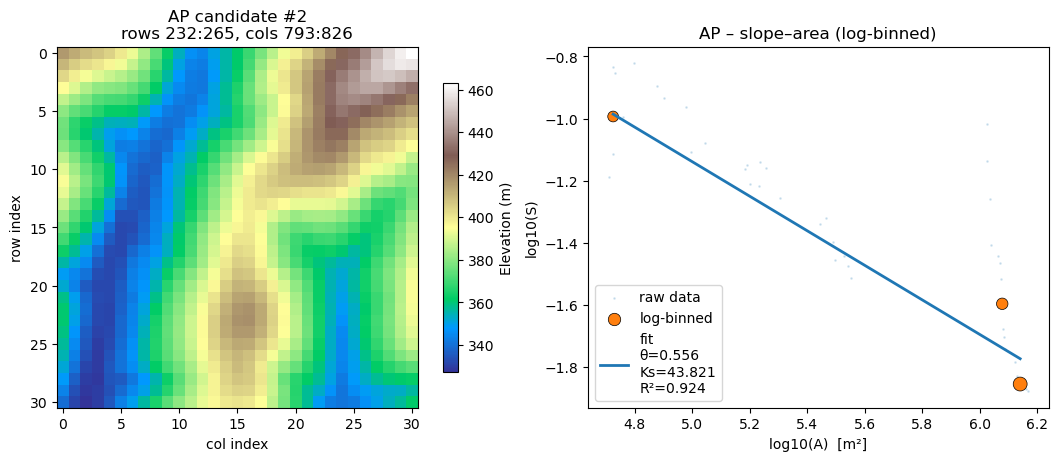


AP – candidate #3   (RMS = 0.131100)
Tile: rows 1123:1156, cols 1189:1222   (930 m × 930 m)

Results:
  Outlets: 7   Divides: 33   Valid curvatures: 31
  Median D: 8.87e-03 m²/yr  (IQR 6.8e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.20  (Taylor   5.93)
  Ks (m): 44.032  (Taylor 47.200)
  θ      :  0.516  (Taylor  0.540)
  R²(sl–A fit): 0.719

Individual errors:
  Curvature:   -4.6%   Ks:   -6.7%   θ:   -4.5%
  3-term RMS error: 0.093112


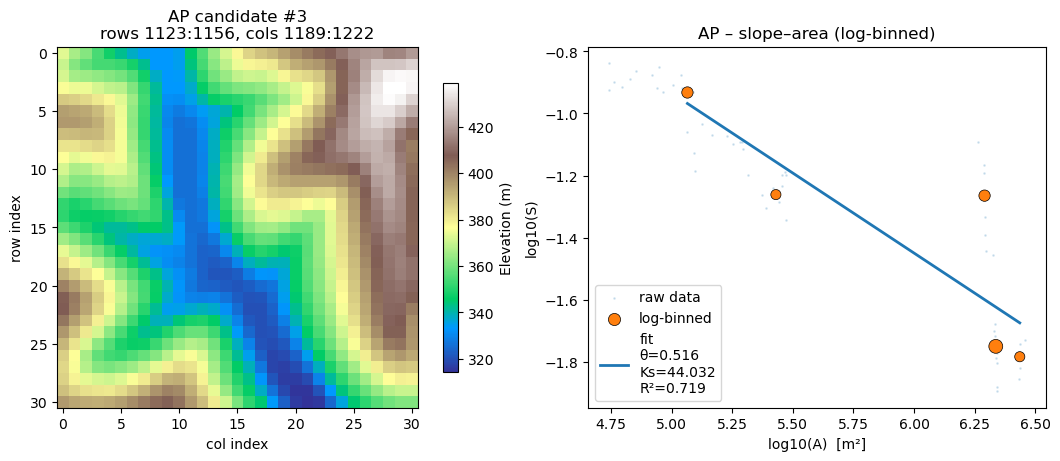


AP – candidate #4   (RMS = 0.133796)
Tile: rows 694:727, cols 1057:1090   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 36   Valid curvatures: 36
  Median D: 8.88e-03 m²/yr  (IQR 6.6e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.20  (Taylor   5.93)
  Ks (m): 43.242  (Taylor 47.200)
  θ      :  0.555  (Taylor  0.540)
  R²(sl–A fit): 0.991

Individual errors:
  Curvature:   -4.5%   Ks:   -8.4%   θ:   +2.8%
  3-term RMS error: 0.099190


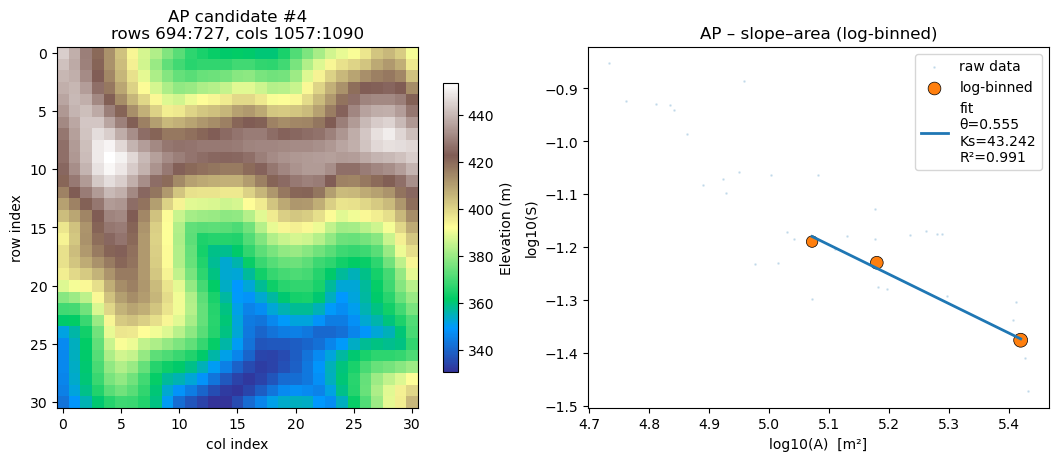


AP – candidate #5   (RMS = 0.137134)
Tile: rows 892:925, cols 34:67   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 67   Valid curvatures: 56
  Median D: 9.33e-03 m²/yr  (IQR 6.6e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.91  (Taylor   5.93)
  Ks (m): 52.700  (Taylor 47.200)
  θ      :  0.579  (Taylor  0.540)
  R²(sl–A fit): 0.902

Individual errors:
  Curvature:   +0.4%   Ks:  +11.7%   θ:   +7.2%
  3-term RMS error: 0.136887


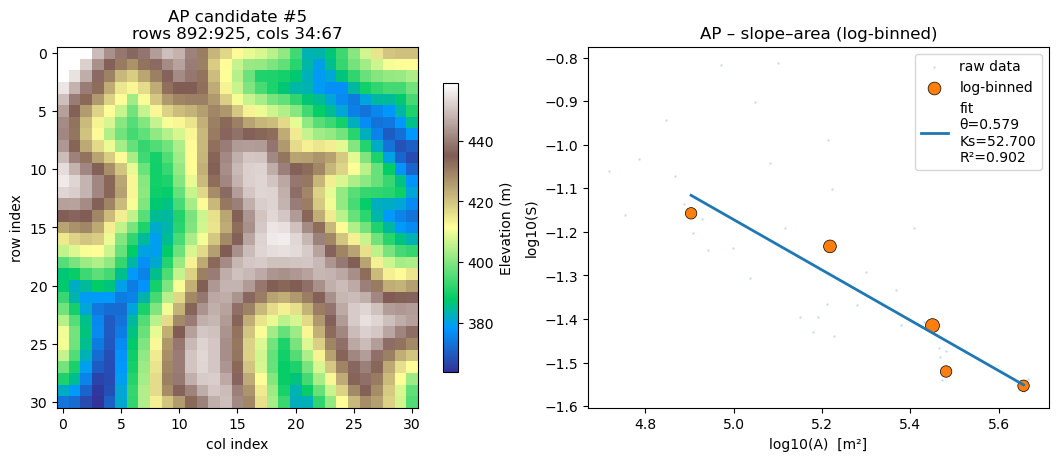


AP – candidate #6   (RMS = 0.137695)
Tile: rows 826:859, cols 793:826   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 39   Valid curvatures: 39
  Median D: 9.09e-03 m²/yr  (IQR 7.5e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.05  (Taylor   5.93)
  Ks (m): 41.064  (Taylor 47.200)
  θ      :  0.544  (Taylor  0.540)
  R²(sl–A fit): 0.974

Individual errors:
  Curvature:   -2.0%   Ks:  -13.0%   θ:   +0.7%
  3-term RMS error: 0.131705


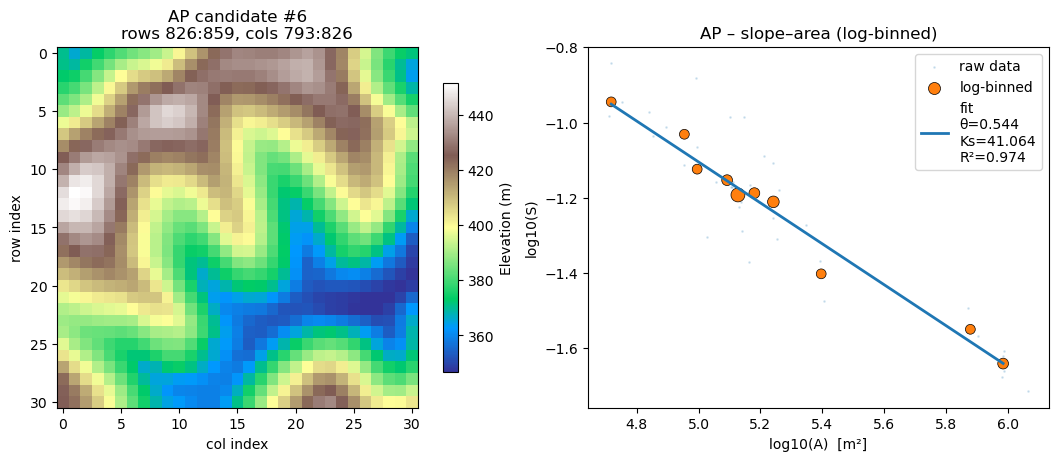


AP – candidate #7   (RMS = 0.195851)
Tile: rows 463:496, cols 1420:1453   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 17   Valid curvatures: 16
  Median D: 9.00e-03 m²/yr  (IQR 6.9e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.11  (Taylor   5.93)
  Ks (m): 54.750  (Taylor 47.200)
  θ      :  0.589  (Taylor  0.540)
  R²(sl–A fit): 0.986

Individual errors:
  Curvature:   -3.0%   Ks:  +16.0%   θ:   +9.0%
  3-term RMS error: 0.186188


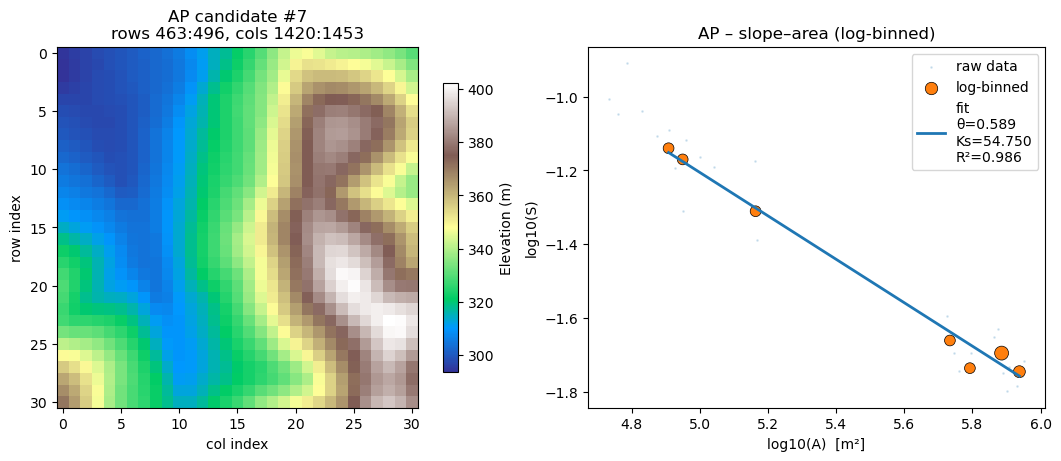


AP – candidate #8   (RMS = 0.199223)
Tile: rows 925:958, cols 166:199   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 46   Valid curvatures: 44
  Median D: 9.83e-03 m²/yr  (IQR 7.0e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.59  (Taylor   5.93)
  Ks (m): 39.949  (Taylor 47.200)
  θ      :  0.543  (Taylor  0.540)
  R²(sl–A fit): 0.979

Individual errors:
  Curvature:   +5.7%   Ks:  -15.4%   θ:   +0.6%
  3-term RMS error: 0.163861


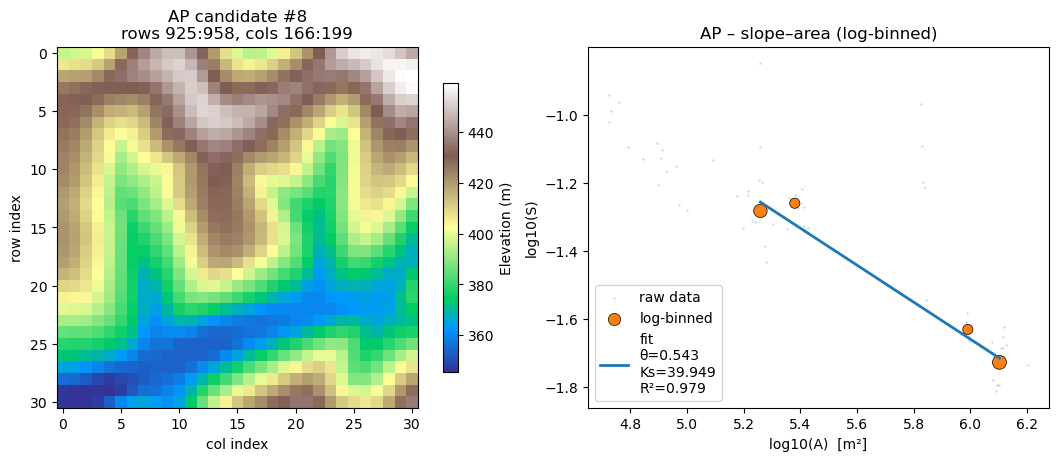


AP – candidate #9   (RMS = 0.199292)
Tile: rows 265:298, cols 694:727   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 81   Valid curvatures: 76
  Median D: 9.78e-03 m²/yr  (IQR 6.7e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.62  (Taylor   5.93)
  Ks (m): 54.277  (Taylor 47.200)
  θ      :  0.574  (Taylor  0.540)
  R²(sl–A fit): 0.943

Individual errors:
  Curvature:   +5.2%   Ks:  +15.0%   θ:   +6.2%
  3-term RMS error: 0.170351


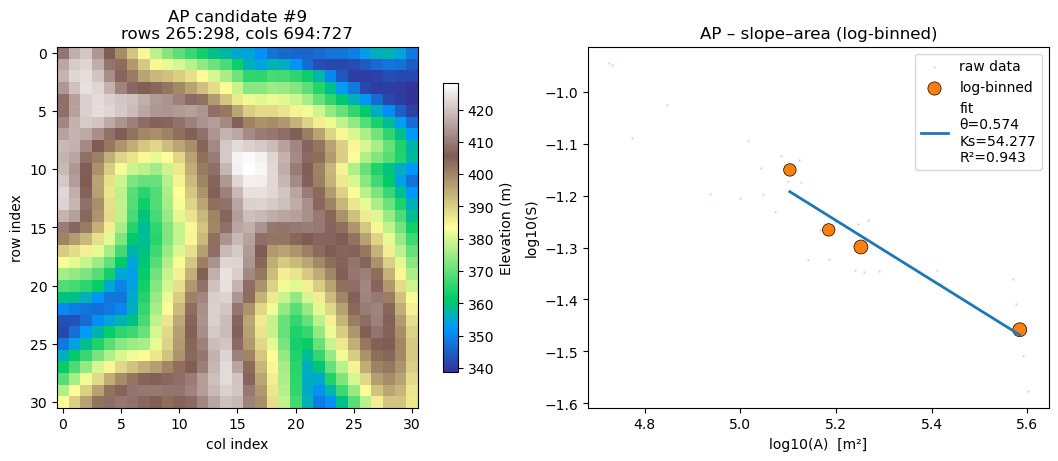


AP – candidate #10   (RMS = 0.204995)
Tile: rows 661:694, cols 661:694   (930 m × 930 m)

Results:
  Outlets: 3   Divides: 35   Valid curvatures: 31
  Median D: 9.47e-03 m²/yr  (IQR 6.8e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.81  (Taylor   5.93)
  Ks (m): 37.824  (Taylor 47.200)
  θ      :  0.528  (Taylor  0.540)
  R²(sl–A fit): 0.563

Individual errors:
  Curvature:   +2.0%   Ks:  -19.9%   θ:   -2.2%
  3-term RMS error: 0.200872


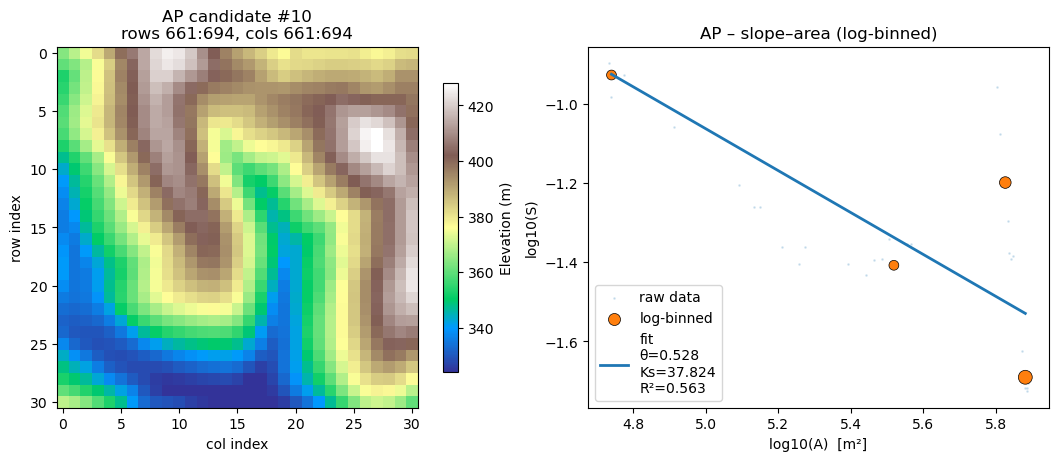


AP – candidate #11   (RMS = 0.218201)
Tile: rows 826:859, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 43   Valid curvatures: 42
  Median D: 1.03e-02 m²/yr  (IQR 6.9e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.37  (Taylor   5.93)
  Ks (m): 47.911  (Taylor 47.200)
  θ      :  0.567  (Taylor  0.540)
  R²(sl–A fit): 0.927

Individual errors:
  Curvature:   +9.5%   Ks:   +1.5%   θ:   +5.0%
  3-term RMS error: 0.108174


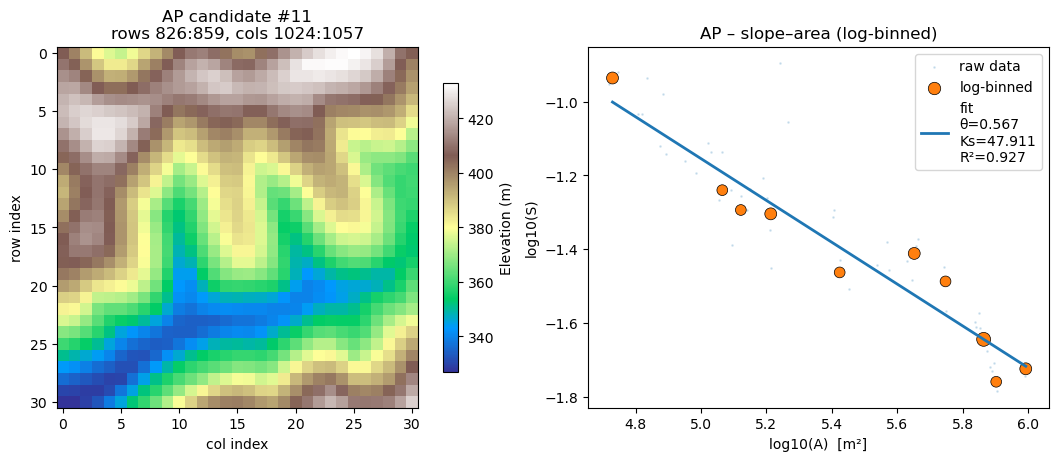


AP – candidate #12   (RMS = 0.239320)
Tile: rows 892:925, cols 760:793   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 66   Valid curvatures: 65
  Median D: 9.07e-03 m²/yr  (IQR 6.4e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.06  (Taylor   5.93)
  Ks (m): 57.498  (Taylor 47.200)
  θ      :  0.586  (Taylor  0.540)
  R²(sl–A fit): 0.869

Individual errors:
  Curvature:   -2.2%   Ks:  +21.8%   θ:   +8.5%
  3-term RMS error: 0.235060


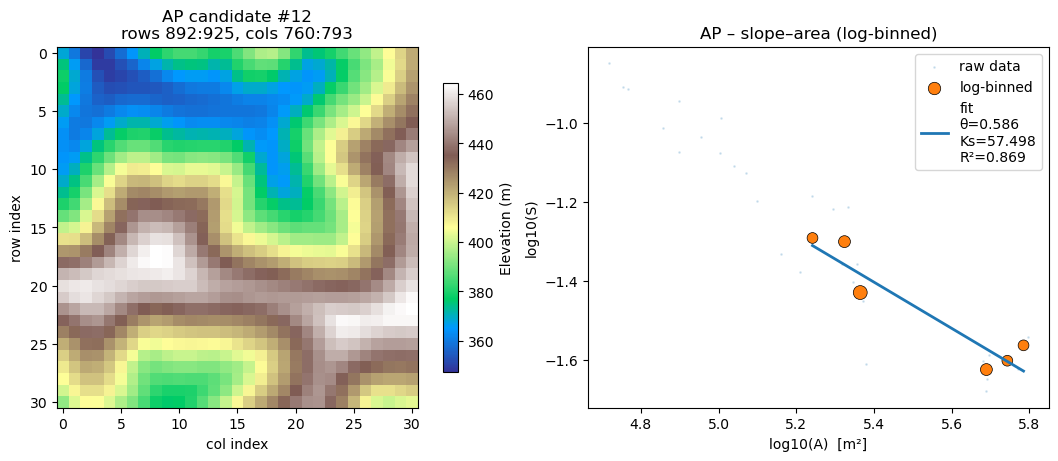


AP – candidate #13   (RMS = 0.250451)
Tile: rows 1090:1123, cols 463:496   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 54   Valid curvatures: 53
  Median D: 8.58e-03 m²/yr  (IQR 7.5e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.41  (Taylor   5.93)
  Ks (m): 55.266  (Taylor 47.200)
  θ      :  0.559  (Taylor  0.540)
  R²(sl–A fit): 0.957

Individual errors:
  Curvature:   -8.0%   Ks:  +17.1%   θ:   +3.5%
  3-term RMS error: 0.192050


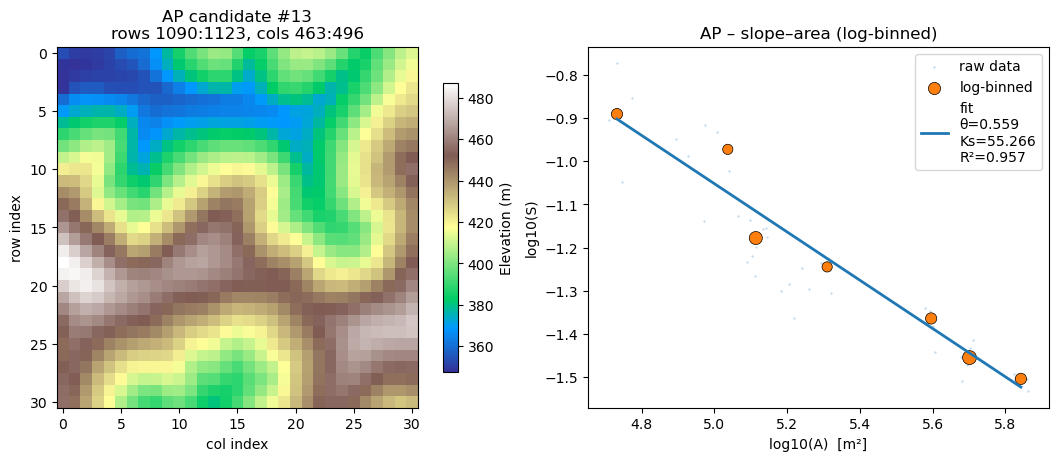


AP – candidate #14   (RMS = 0.257772)
Tile: rows 727:760, cols 826:859   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 88   Valid curvatures: 84
  Median D: 8.45e-03 m²/yr  (IQR 5.7e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.51  (Taylor   5.93)
  Ks (m): 53.409  (Taylor 47.200)
  θ      :  0.561  (Taylor  0.540)
  R²(sl–A fit): 0.924

Individual errors:
  Curvature:   -9.8%   Ks:  +13.2%   θ:   +3.9%
  3-term RMS error: 0.168331


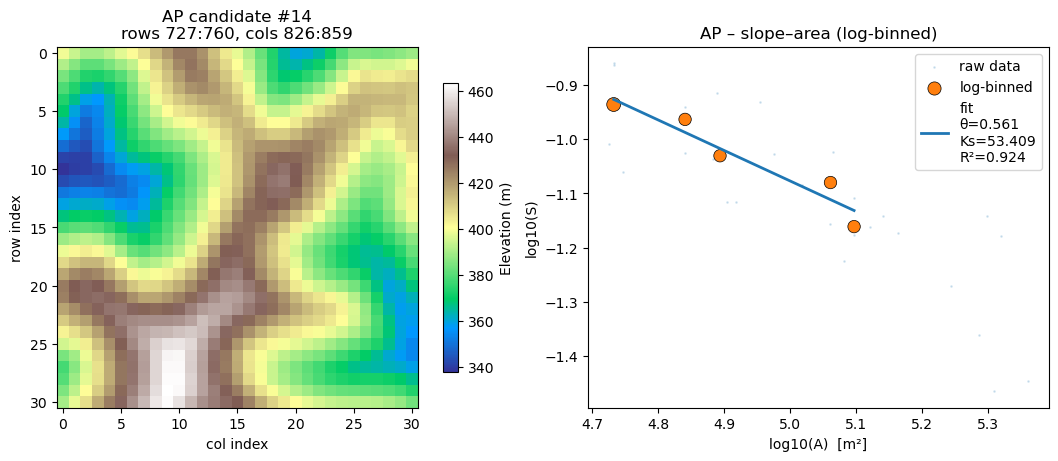


AP – candidate #15   (RMS = 0.258068)
Tile: rows 1024:1057, cols 298:331   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 14   Valid curvatures: 14
  Median D: 9.84e-03 m²/yr  (IQR 7.4e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.73  (Taylor   5.93)
  Ks (m): 36.237  (Taylor 47.200)
  θ      :  0.495  (Taylor  0.540)
  R²(sl–A fit): 0.512

Individual errors:
  Curvature:   +3.4%   Ks:  -23.2%   θ:   -8.4%
  3-term RMS error: 0.249112


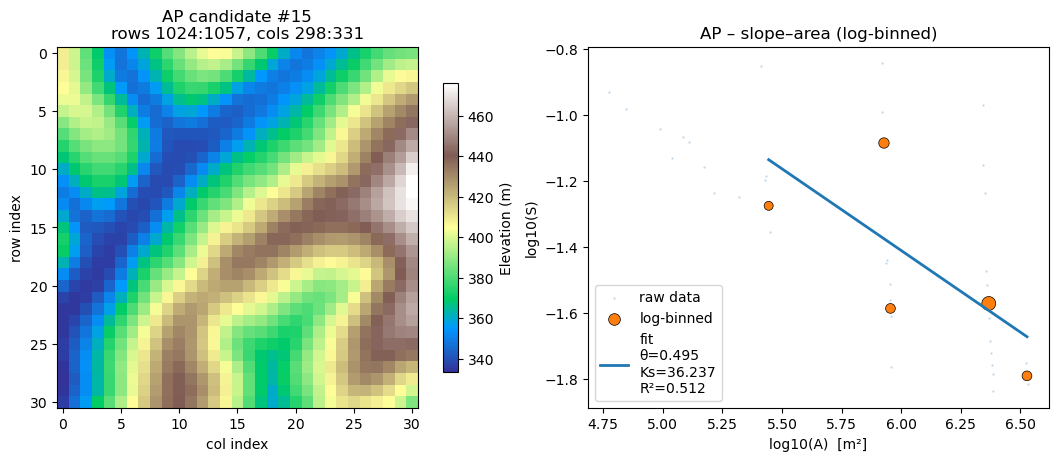


AP – candidate #16   (RMS = 0.266288)
Tile: rows 1057:1090, cols 991:1024   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 98   Valid curvatures: 95
  Median D: 8.47e-03 m²/yr  (IQR 7.0e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.49  (Taylor   5.93)
  Ks (m): 39.601  (Taylor 47.200)
  θ      :  0.533  (Taylor  0.540)
  R²(sl–A fit): 0.992

Individual errors:
  Curvature:   -9.5%   Ks:  -16.1%   θ:   -1.2%
  3-term RMS error: 0.187196


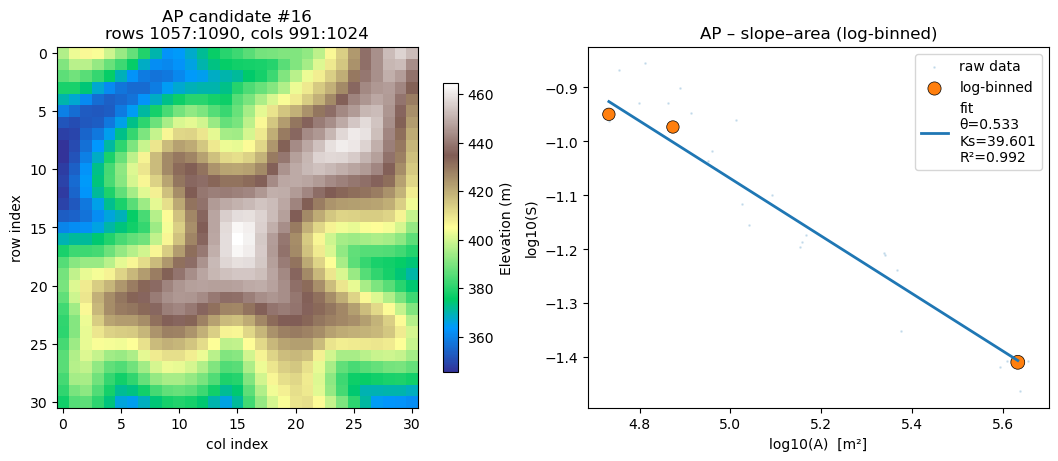


AP – candidate #17   (RMS = 0.266869)
Tile: rows 859:892, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 27   Valid curvatures: 15
  Median D: 8.33e-03 m²/yr  (IQR 6.3e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.61  (Taylor   5.93)
  Ks (m): 43.718  (Taylor 47.200)
  θ      :  0.556  (Taylor  0.540)
  R²(sl–A fit): 0.930

Individual errors:
  Curvature:  -11.4%   Ks:   -7.4%   θ:   +3.0%
  3-term RMS error: 0.138995


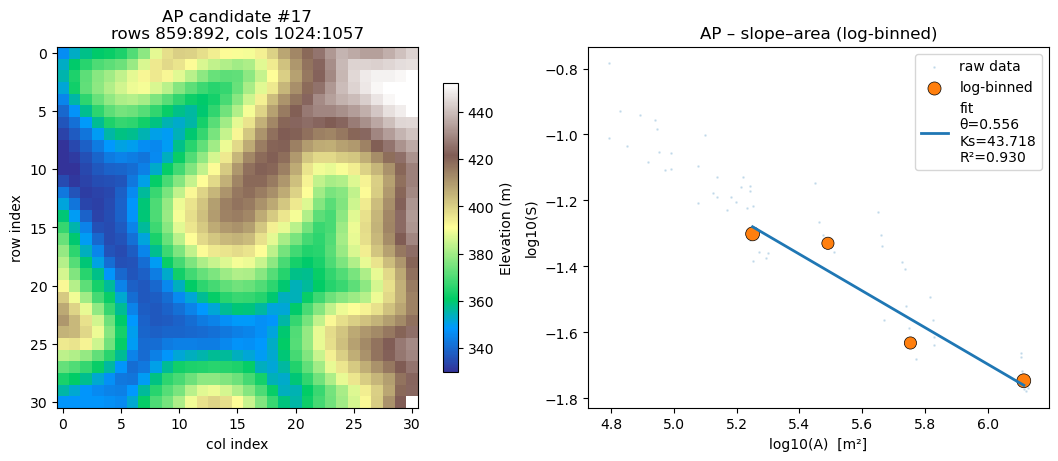


AP – candidate #18   (RMS = 0.271692)
Tile: rows 1222:1255, cols 232:265   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 61   Valid curvatures: 58
  Median D: 8.58e-03 m²/yr  (IQR 6.1e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.41  (Taylor   5.93)
  Ks (m): 37.598  (Taylor 47.200)
  θ      :  0.535  (Taylor  0.540)
  R²(sl–A fit): 0.777

Individual errors:
  Curvature:   -8.0%   Ks:  -20.3%   θ:   -0.9%
  3-term RMS error: 0.218959


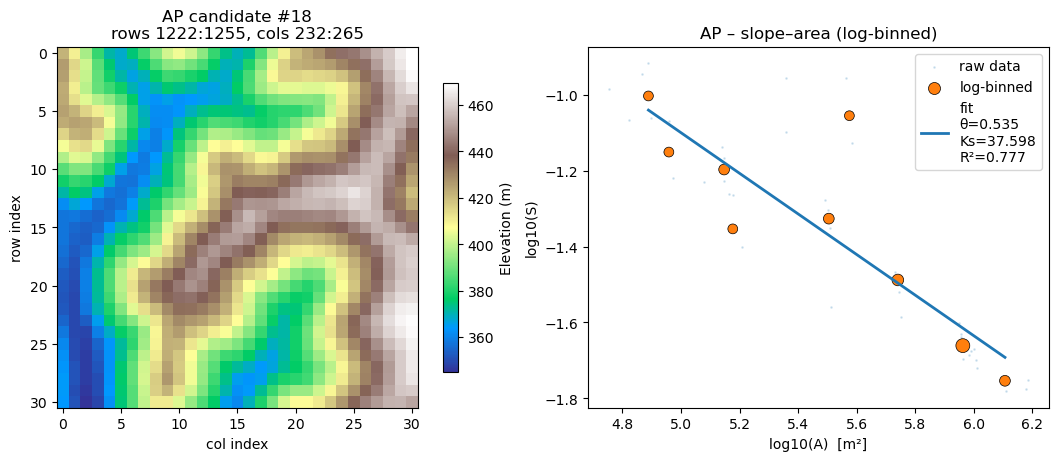


AP – candidate #19   (RMS = 0.299604)
Tile: rows 925:958, cols 859:892   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 26   Valid curvatures: 26
  Median D: 8.42e-03 m²/yr  (IQR 6.1e-03–1.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.53  (Taylor   5.93)
  Ks (m): 55.622  (Taylor 47.200)
  θ      :  0.584  (Taylor  0.540)
  R²(sl–A fit): 0.679

Individual errors:
  Curvature:  -10.1%   Ks:  +17.8%   θ:   +8.2%
  3-term RMS error: 0.220959


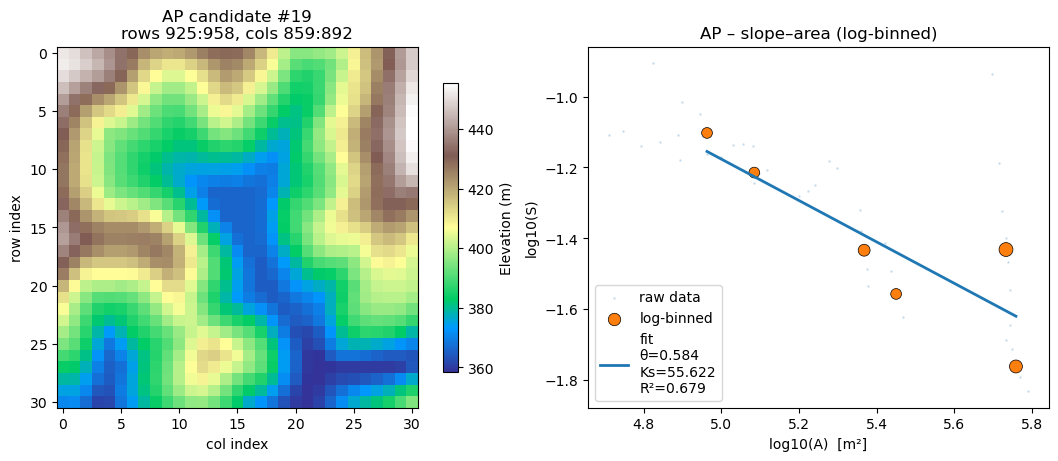


AP – candidate #20   (RMS = 0.304669)
Tile: rows 298:331, cols 694:727   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 51   Valid curvatures: 48
  Median D: 8.88e-03 m²/yr  (IQR 6.5e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.24  (Taylor   5.93)
  Ks (m): 59.956  (Taylor 47.200)
  θ      :  0.581  (Taylor  0.540)
  R²(sl–A fit): 0.996

Individual errors:
  Curvature:   -5.3%   Ks:  +27.0%   θ:   +7.7%
  3-term RMS error: 0.285839


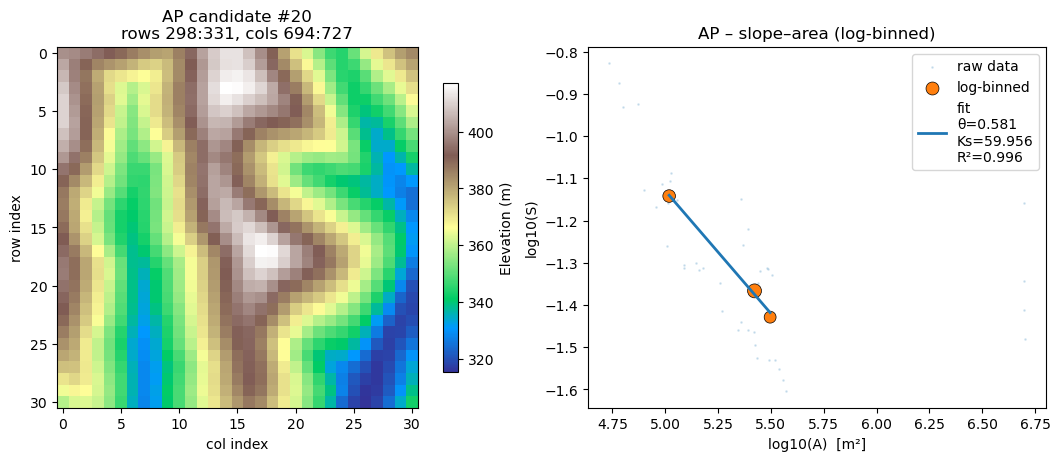


AP – candidate #21   (RMS = 0.311561)
Tile: rows 1222:1255, cols 166:199   (930 m × 930 m)

Results:
  Outlets: 7   Divides: 78   Valid curvatures: 75
  Median D: 8.20e-03 m²/yr  (IQR 5.1e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.71  (Taylor   5.93)
  Ks (m): 52.014  (Taylor 47.200)
  θ      :  0.556  (Taylor  0.540)
  R²(sl–A fit): 0.807

Individual errors:
  Curvature:  -13.1%   Ks:  +10.2%   θ:   +2.9%
  3-term RMS error: 0.168590


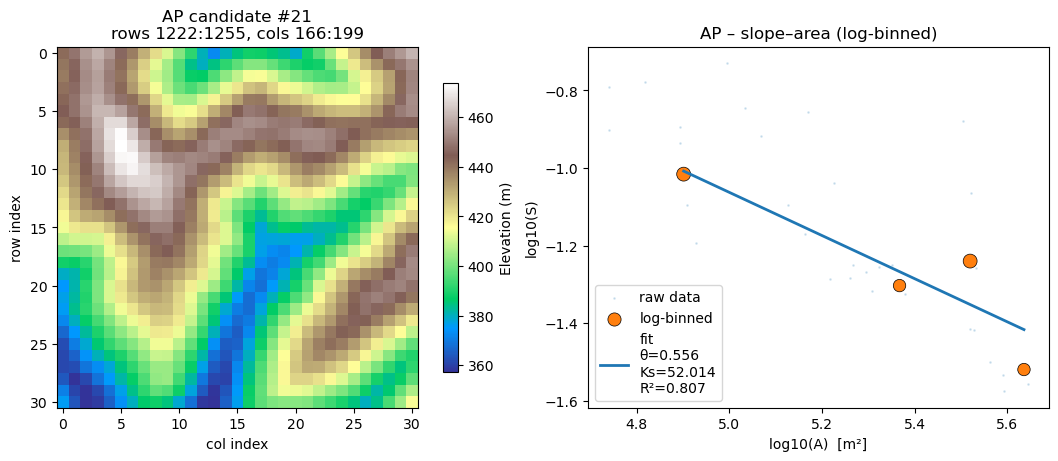


AP – candidate #22   (RMS = 0.317389)
Tile: rows 661:694, cols 892:925   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 55   Valid curvatures: 53
  Median D: 1.06e-02 m²/yr  (IQR 7.9e-03–1.8e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.18  (Taylor   5.93)
  Ks (m): 40.533  (Taylor 47.200)
  θ      :  0.521  (Taylor  0.540)
  R²(sl–A fit): 0.906

Individual errors:
  Curvature:  +12.6%   Ks:  -14.1%   θ:   -3.4%
  3-term RMS error: 0.192492


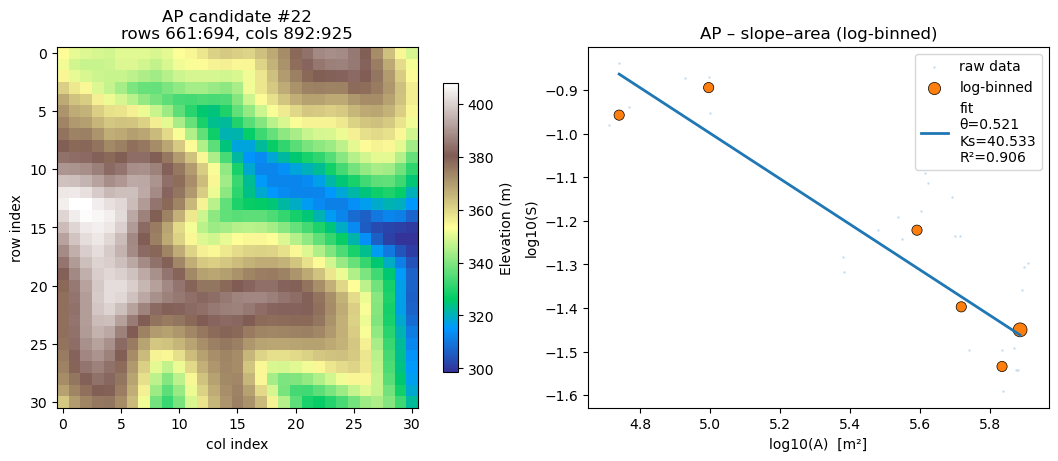


AP – candidate #23   (RMS = 0.320946)
Tile: rows 793:826, cols 595:628   (930 m × 930 m)

Results:
  Outlets: 3   Divides: 40   Valid curvatures: 40
  Median D: 8.13e-03 m²/yr  (IQR 6.9e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.76  (Taylor   5.93)
  Ks (m): 45.466  (Taylor 47.200)
  θ      :  0.569  (Taylor  0.540)
  R²(sl–A fit): 0.983

Individual errors:
  Curvature:  -14.1%   Ks:   -3.7%   θ:   +5.3%
  3-term RMS error: 0.154630


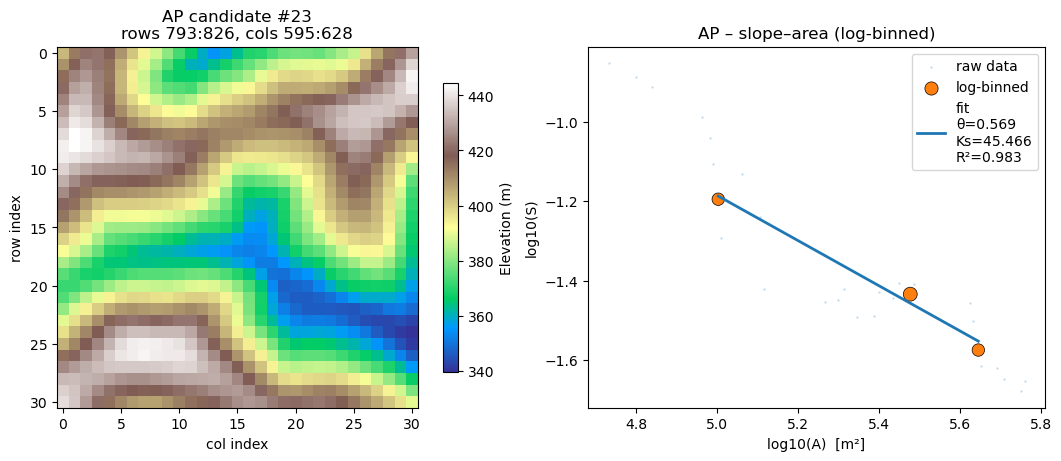


AP – candidate #24   (RMS = 0.324366)
Tile: rows 1156:1189, cols 199:232   (930 m × 930 m)

Results:
  Outlets: 8   Divides: 60   Valid curvatures: 58
  Median D: 8.73e-03 m²/yr  (IQR 6.4e-03–1.3e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.30  (Taylor   5.93)
  Ks (m): 33.786  (Taylor 47.200)
  θ      :  0.502  (Taylor  0.540)
  R²(sl–A fit): 0.963

Individual errors:
  Curvature:   -6.3%   Ks:  -28.4%   θ:   -7.0%
  3-term RMS error: 0.299235


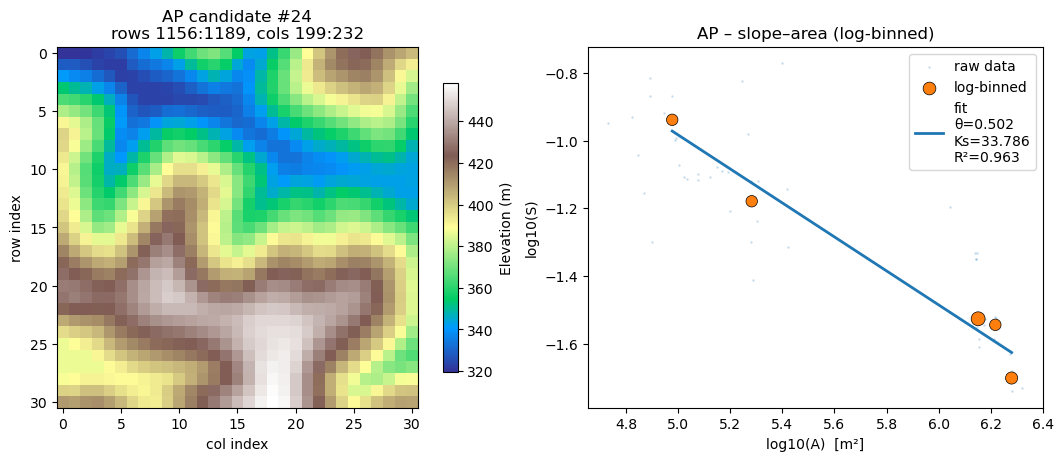


AP – candidate #25   (RMS = 0.365376)
Tile: rows 628:661, cols 529:562   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 23   Valid curvatures: 21
  Median D: 8.42e-03 m²/yr  (IQR 6.2e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.53  (Taylor   5.93)
  Ks (m): 33.755  (Taylor 47.200)
  θ      :  0.520  (Taylor  0.540)
  R²(sl–A fit): 0.937

Individual errors:
  Curvature:  -10.1%   Ks:  -28.5%   θ:   -3.8%
  3-term RMS error: 0.304538


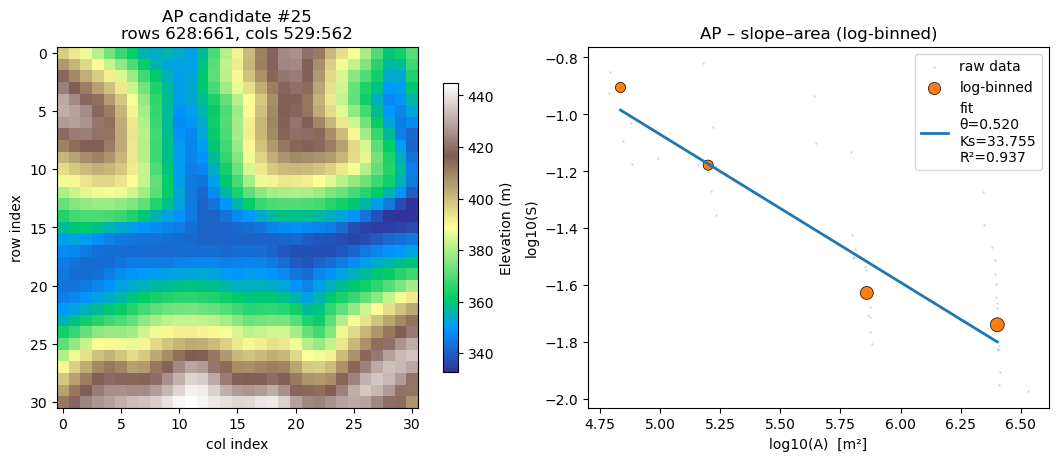


AP – candidate #26   (RMS = 0.367962)
Tile: rows 760:793, cols 793:826   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 49   Valid curvatures: 49
  Median D: 9.69e-03 m²/yr  (IQR 6.1e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.67  (Taylor   5.93)
  Ks (m): 63.789  (Taylor 47.200)
  θ      :  0.567  (Taylor  0.540)
  R²(sl–A fit): 0.978

Individual errors:
  Curvature:   +4.3%   Ks:  +35.1%   θ:   +5.1%
  3-term RMS error: 0.357716


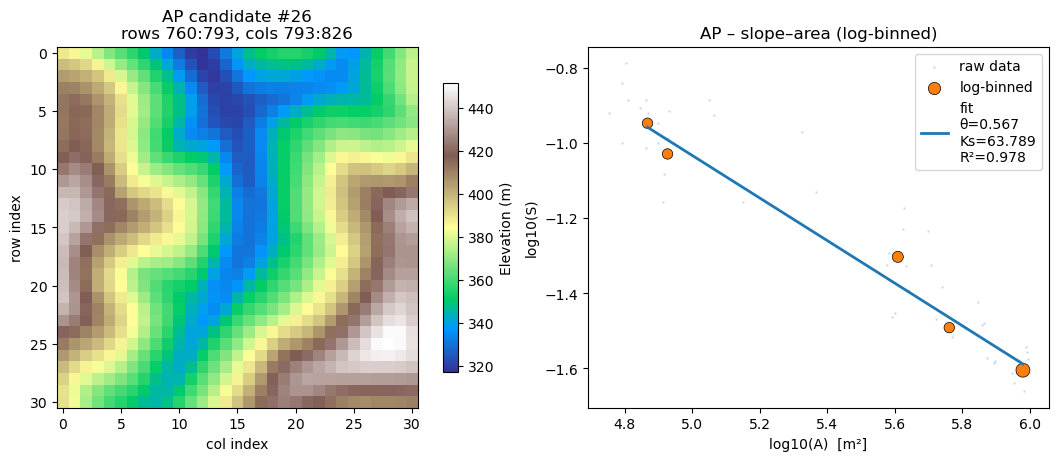


AP – candidate #27   (RMS = 0.382556)
Tile: rows 1123:1156, cols 595:628   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 45   Valid curvatures: 43
  Median D: 7.92e-03 m²/yr  (IQR 4.5e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.94  (Taylor   5.93)
  Ks (m): 48.050  (Taylor 47.200)
  θ      :  0.553  (Taylor  0.540)
  R²(sl–A fit): 0.916

Individual errors:
  Curvature:  -17.1%   Ks:   +1.8%   θ:   +2.5%
  3-term RMS error: 0.173236


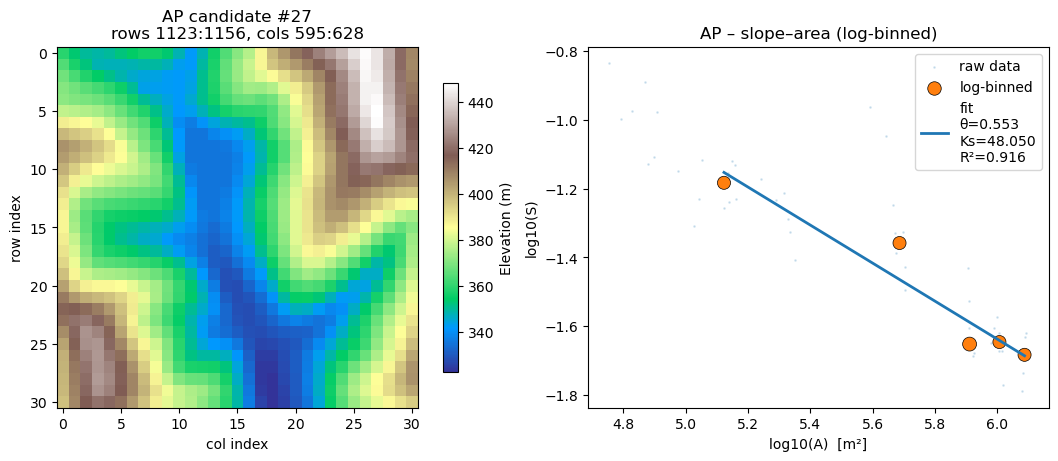


AP – candidate #28   (RMS = 0.384399)
Tile: rows 397:430, cols 595:628   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 46   Valid curvatures: 43
  Median D: 9.17e-03 m²/yr  (IQR 6.7e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.00  (Taylor   5.93)
  Ks (m): 64.492  (Taylor 47.200)
  θ      :  0.601  (Taylor  0.540)
  R²(sl–A fit): 0.814

Individual errors:
  Curvature:   -1.1%   Ks:  +36.6%   θ:  +11.4%
  3-term RMS error: 0.383720


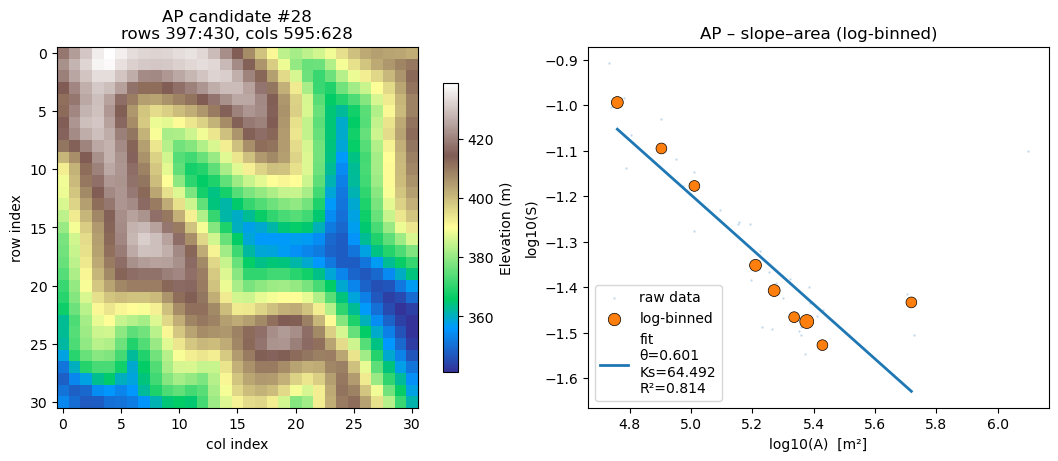


AP – candidate #29   (RMS = 0.399310)
Tile: rows 1057:1090, cols 1486:1519   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 86   Valid curvatures: 81
  Median D: 9.14e-03 m²/yr  (IQR 6.3e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.02  (Taylor   5.93)
  Ks (m): 28.477  (Taylor 47.200)
  θ      :  0.523  (Taylor  0.540)
  R²(sl–A fit): 0.908

Individual errors:
  Curvature:   -1.5%   Ks:  -39.7%   θ:   -3.2%
  3-term RMS error: 0.398215


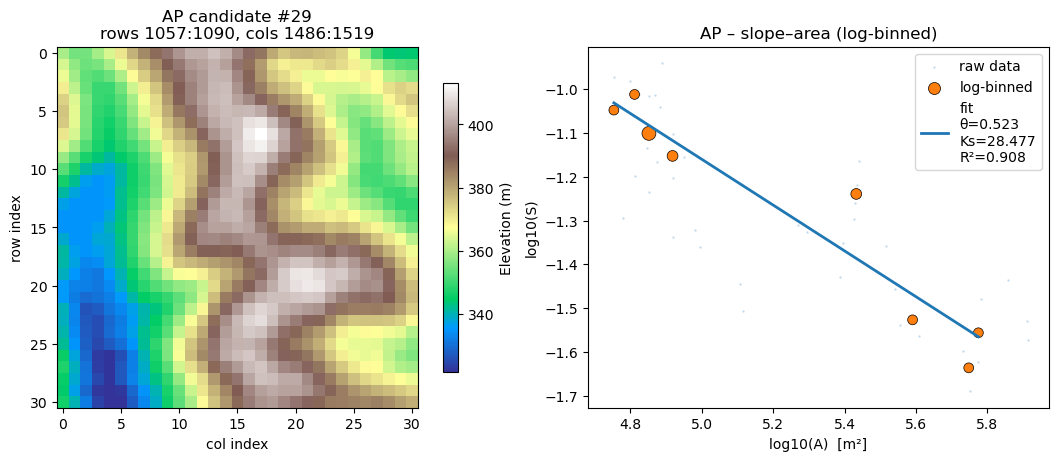


AP – candidate #30   (RMS = 0.403776)
Tile: rows 298:331, cols 628:661   (930 m × 930 m)

Results:
  Outlets: 7   Divides: 68   Valid curvatures: 67
  Median D: 1.06e-02 m²/yr  (IQR 7.6e-03–2.0e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.18  (Taylor   5.93)
  Ks (m): 33.543  (Taylor 47.200)
  θ      :  0.538  (Taylor  0.540)
  R²(sl–A fit): 0.903

Individual errors:
  Curvature:  +12.6%   Ks:  -28.9%   θ:   -0.4%
  3-term RMS error: 0.315579


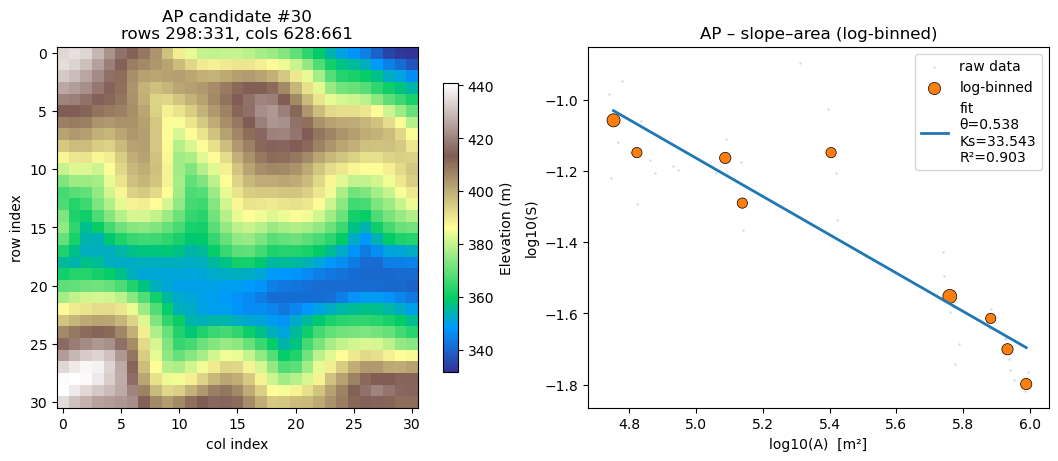


AP – candidate #31   (RMS = 0.427108)
Tile: rows 397:430, cols 562:595   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 38   Valid curvatures: 37
  Median D: 1.14e-02 m²/yr  (IQR 8.8e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.81  (Taylor   5.93)
  Ks (m): 46.831  (Taylor 47.200)
  θ      :  0.569  (Taylor  0.540)
  R²(sl–A fit): 0.574

Individual errors:
  Curvature:  +18.9%   Ks:   -0.8%   θ:   +5.3%
  3-term RMS error: 0.196953


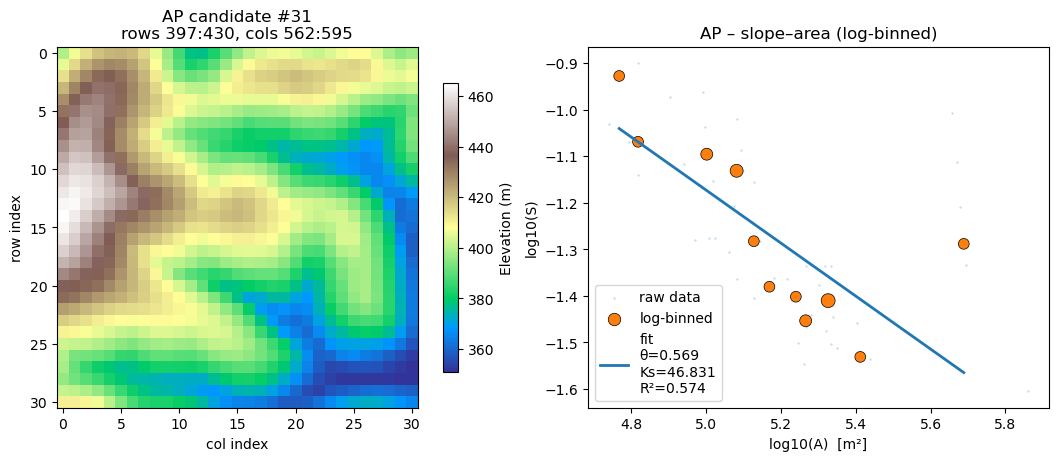


AP – candidate #32   (RMS = 0.429970)
Tile: rows 1057:1090, cols 1255:1288   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 27   Valid curvatures: 25
  Median D: 8.68e-03 m²/yr  (IQR 5.3e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.34  (Taylor   5.93)
  Ks (m): 66.029  (Taylor 47.200)
  θ      :  0.564  (Taylor  0.540)
  R²(sl–A fit): 0.807

Individual errors:
  Curvature:   -6.9%   Ks:  +39.9%   θ:   +4.5%
  3-term RMS error: 0.407271


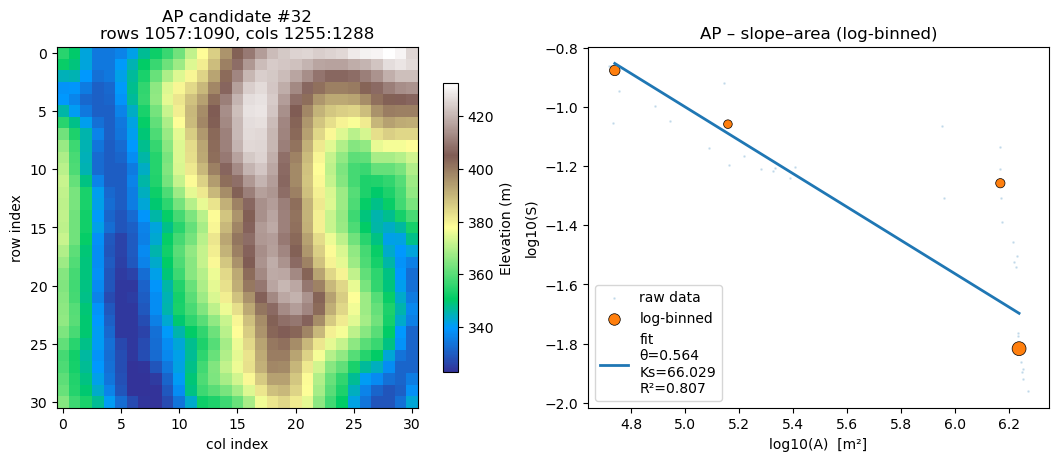


AP – candidate #33   (RMS = 0.434065)
Tile: rows 694:727, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 20   Valid curvatures: 18
  Median D: 8.38e-03 m²/yr  (IQR 5.4e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.82  (Taylor   5.93)
  Ks (m): 34.385  (Taylor 47.200)
  θ      :  0.512  (Taylor  0.540)
  R²(sl–A fit): 0.989

Individual errors:
  Curvature:  -15.0%   Ks:  -27.1%   θ:   -5.2%
  3-term RMS error: 0.314331


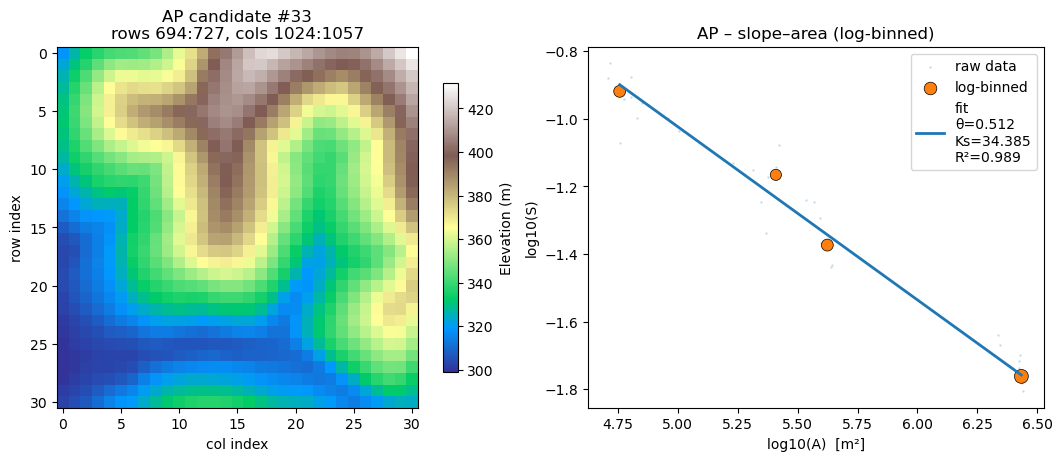


AP – candidate #34   (RMS = 0.436833)
Tile: rows 859:892, cols 826:859   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 42   Valid curvatures: 41
  Median D: 7.79e-03 m²/yr  (IQR 6.3e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.06  (Taylor   5.93)
  Ks (m): 42.472  (Taylor 47.200)
  θ      :  0.552  (Taylor  0.540)
  R²(sl–A fit): 0.936

Individual errors:
  Curvature:  -19.0%   Ks:  -10.0%   θ:   +2.1%
  3-term RMS error: 0.215776


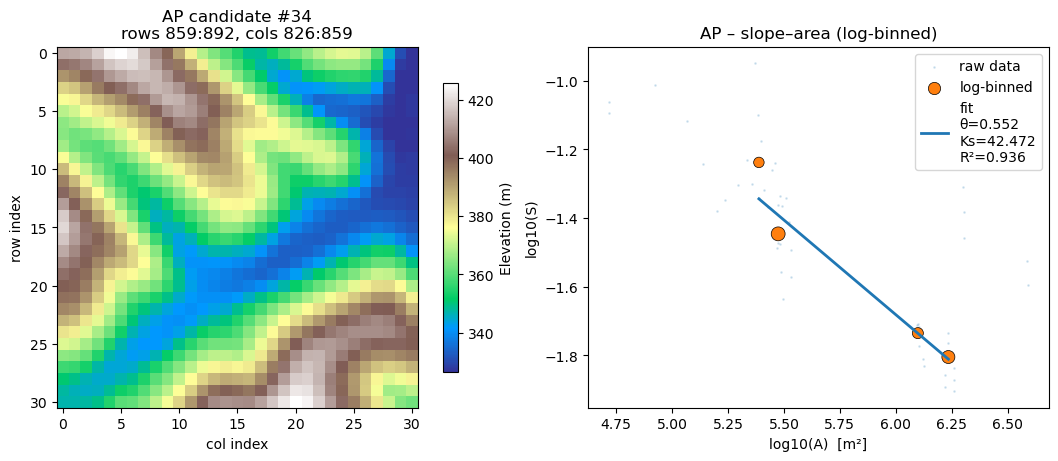


AP – candidate #35   (RMS = 0.450383)
Tile: rows 793:826, cols 727:760   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 28   Valid curvatures: 28
  Median D: 8.40e-03 m²/yr  (IQR 6.5e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.55  (Taylor   5.93)
  Ks (m): 29.402  (Taylor 47.200)
  θ      :  0.498  (Taylor  0.540)
  R²(sl–A fit): 0.485

Individual errors:
  Curvature:  -10.5%   Ks:  -37.7%   θ:   -7.8%
  3-term RMS error: 0.398938


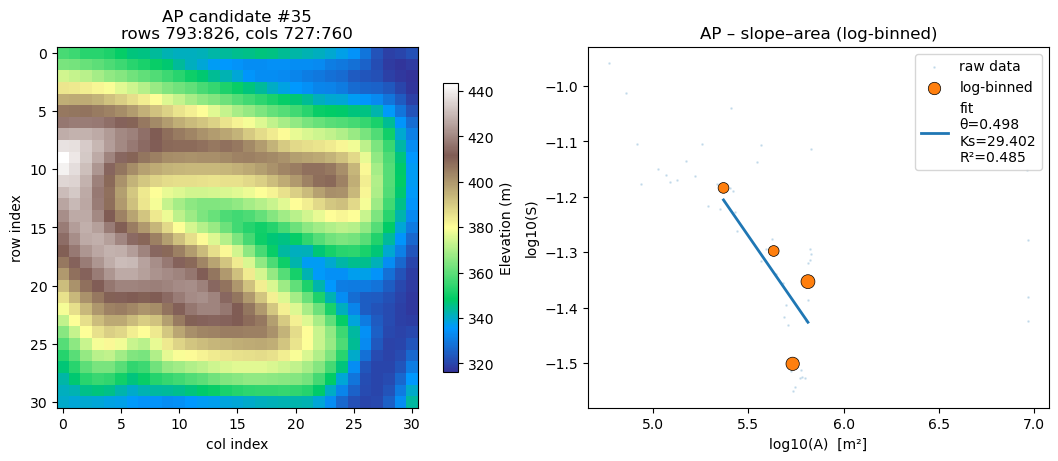


AP – candidate #36   (RMS = 0.455043)
Tile: rows 463:496, cols 727:760   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 69   Valid curvatures: 66
  Median D: 7.77e-03 m²/yr  (IQR 5.7e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.08  (Taylor   5.93)
  Ks (m): 53.084  (Taylor 47.200)
  θ      :  0.575  (Taylor  0.540)
  R²(sl–A fit): 0.964

Individual errors:
  Curvature:  -19.4%   Ks:  +12.5%   θ:   +6.6%
  3-term RMS error: 0.239324


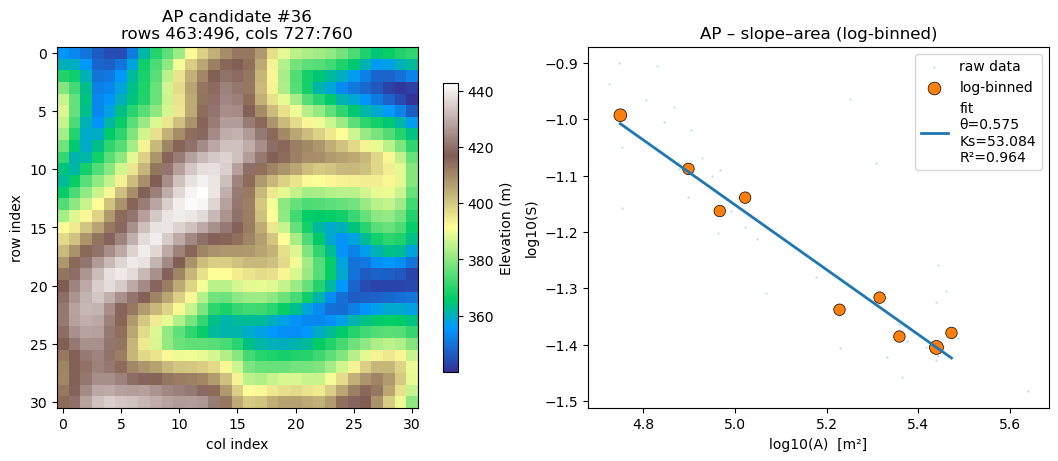


AP – candidate #37   (RMS = 0.471941)
Tile: rows 331:364, cols 562:595   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 36   Valid curvatures: 33
  Median D: 9.12e-03 m²/yr  (IQR 6.2e-03–1.4e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.03  (Taylor   5.93)
  Ks (m): 25.087  (Taylor 47.200)
  θ      :  0.517  (Taylor  0.540)
  R²(sl–A fit): 0.809

Individual errors:
  Curvature:   -1.7%   Ks:  -46.8%   θ:   -4.2%
  3-term RMS error: 0.470714


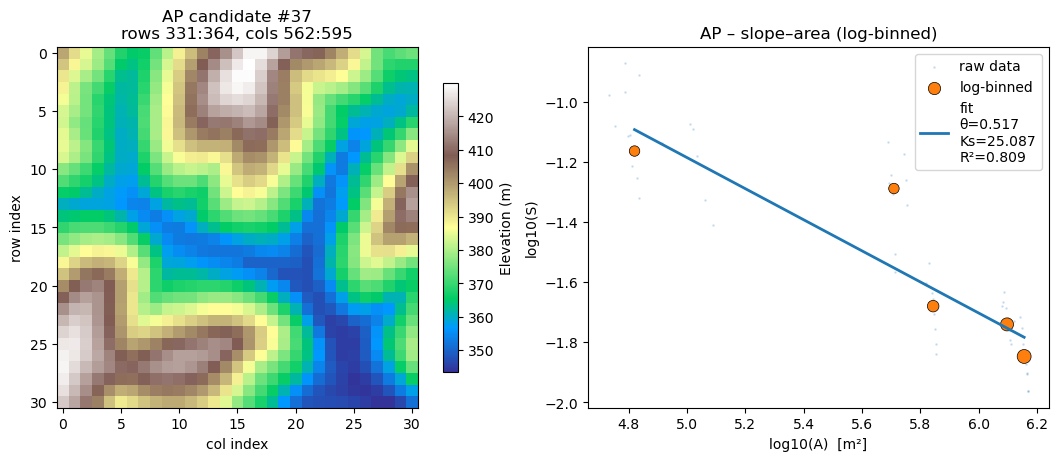


AP – candidate #38   (RMS = 0.474484)
Tile: rows 232:265, cols 628:661   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 33   Valid curvatures: 30
  Median D: 8.03e-03 m²/yr  (IQR 5.8e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.85  (Taylor   5.93)
  Ks (m): 62.079  (Taylor 47.200)
  θ      :  0.576  (Taylor  0.540)
  R²(sl–A fit): 0.931

Individual errors:
  Curvature:  -15.6%   Ks:  +31.5%   θ:   +6.7%
  3-term RMS error: 0.357955


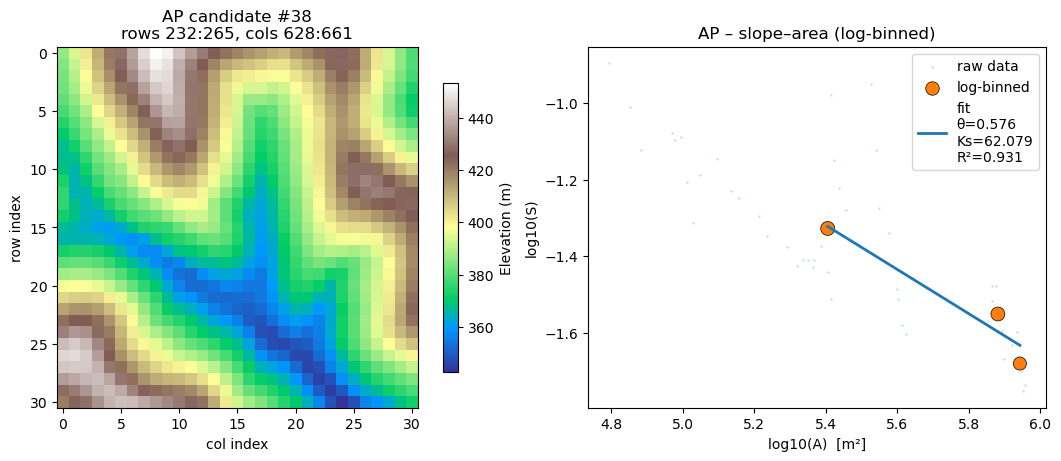


AP – candidate #39   (RMS = 0.475446)
Tile: rows 1024:1057, cols 397:430   (930 m × 930 m)

Results:
  Outlets: 5   Divides: 28   Valid curvatures: 26
  Median D: 7.80e-03 m²/yr  (IQR 4.9e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.19  (Taylor   5.93)
  Ks (m): 45.924  (Taylor 47.200)
  θ      :  0.552  (Taylor  0.540)
  R²(sl–A fit): 0.935

Individual errors:
  Curvature:  -21.2%   Ks:   -2.7%   θ:   +2.2%
  3-term RMS error: 0.214939


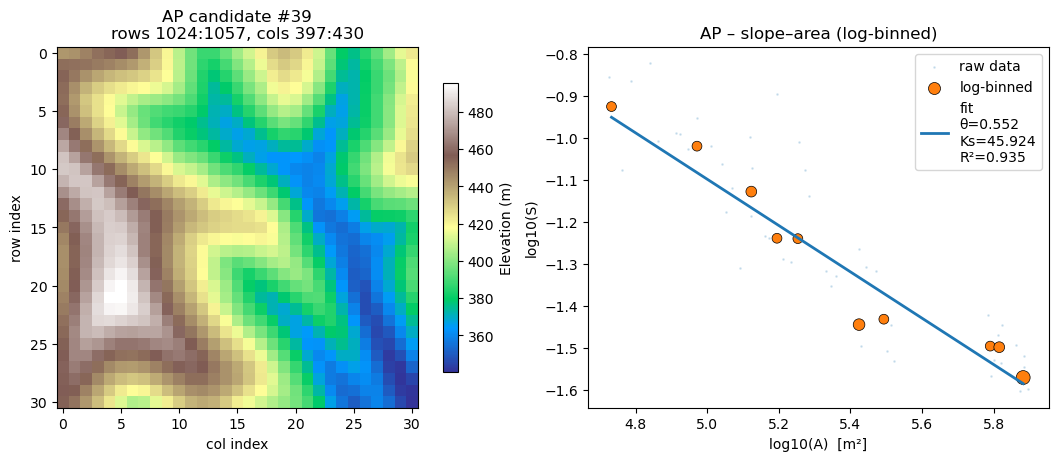


AP – candidate #40   (RMS = 0.477226)
Tile: rows 397:430, cols 793:826   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 53   Valid curvatures: 51
  Median D: 1.15e-02 m²/yr  (IQR 5.9e-03–1.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.77  (Taylor   5.93)
  Ks (m): 56.279  (Taylor 47.200)
  θ      :  0.552  (Taylor  0.540)
  R²(sl–A fit): 0.827

Individual errors:
  Curvature:  +19.5%   Ks:  +19.2%   θ:   +2.2%
  3-term RMS error: 0.274824


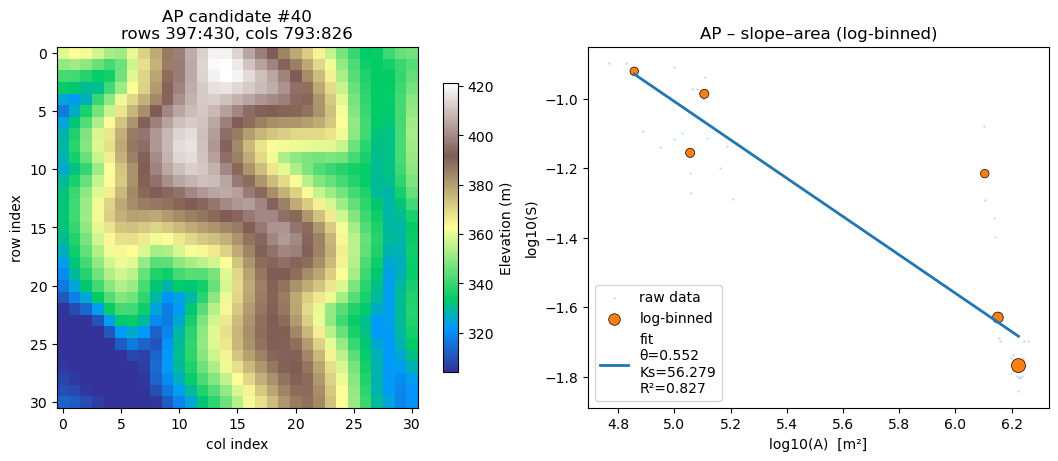


AP – candidate #41   (RMS = 0.477494)
Tile: rows 595:628, cols 1255:1288   (930 m × 930 m)

Results:
  Outlets: 8   Divides: 21   Valid curvatures: 21
  Median D: 1.14e-02 m²/yr  (IQR 8.2e-03–2.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.81  (Taylor   5.93)
  Ks (m): 36.914  (Taylor 47.200)
  θ      :  0.559  (Taylor  0.540)
  R²(sl–A fit): 0.907

Individual errors:
  Curvature:  +18.9%   Ks:  -21.8%   θ:   +3.5%
  3-term RMS error: 0.290787


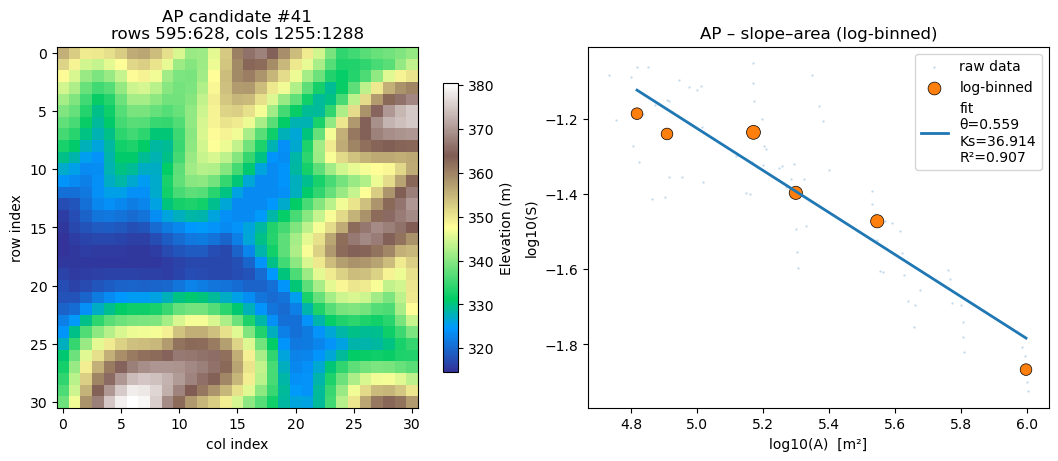


AP – candidate #42   (RMS = 0.484522)
Tile: rows 793:826, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 38   Valid curvatures: 38
  Median D: 7.99e-03 m²/yr  (IQR 6.1e-03–1.7e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.89  (Taylor   5.93)
  Ks (m): 32.067  (Taylor 47.200)
  θ      :  0.517  (Taylor  0.540)
  R²(sl–A fit): 0.957

Individual errors:
  Curvature:  -16.1%   Ks:  -32.1%   θ:   -4.3%
  3-term RMS error: 0.361523


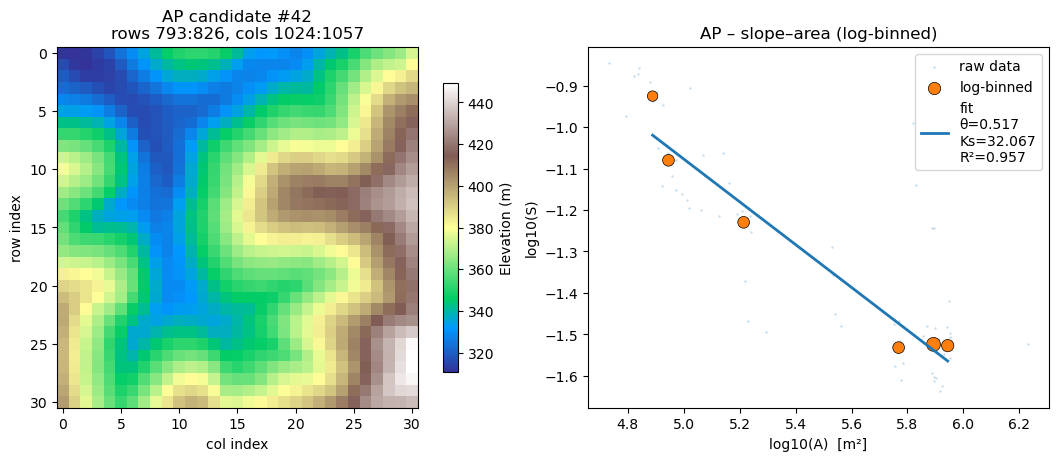


AP – candidate #43   (RMS = 0.487526)
Tile: rows 364:397, cols 958:991   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 12   Valid curvatures: 10
  Median D: 1.20e-02 m²/yr  (IQR 9.2e-03–1.9e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.75  (Taylor   5.93)
  Ks (m): 37.727  (Taylor 47.200)
  θ      :  0.553  (Taylor  0.540)
  R²(sl–A fit): 0.830

Individual errors:
  Curvature:  +19.8%   Ks:  -20.1%   θ:   +2.3%
  3-term RMS error: 0.283185


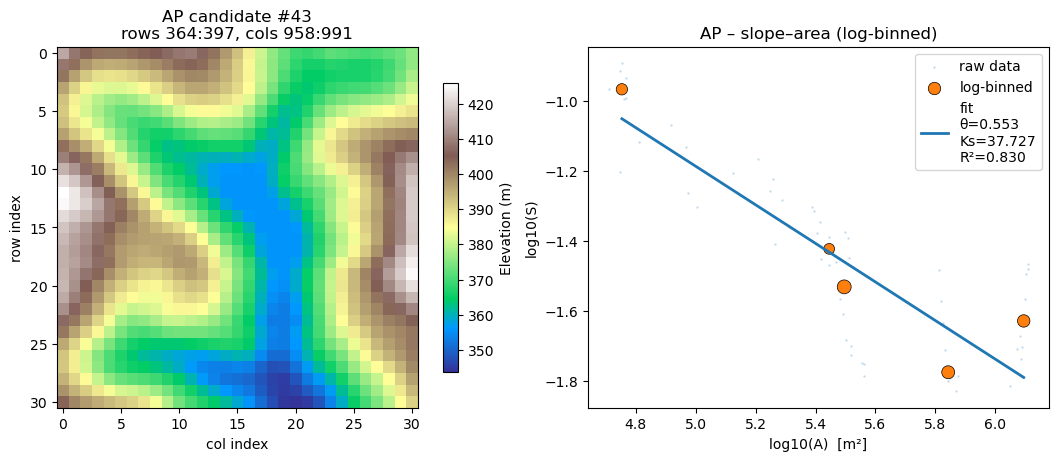


AP – candidate #44   (RMS = 0.487835)
Tile: rows 991:1024, cols 1288:1321   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 75   Valid curvatures: 66
  Median D: 9.57e-03 m²/yr  (IQR 6.8e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.75  (Taylor   5.93)
  Ks (m): 24.733  (Taylor 47.200)
  θ      :  0.496  (Taylor  0.540)
  R²(sl–A fit): 1.000

Individual errors:
  Curvature:   +3.0%   Ks:  -47.6%   θ:   -8.2%
  3-term RMS error: 0.484021


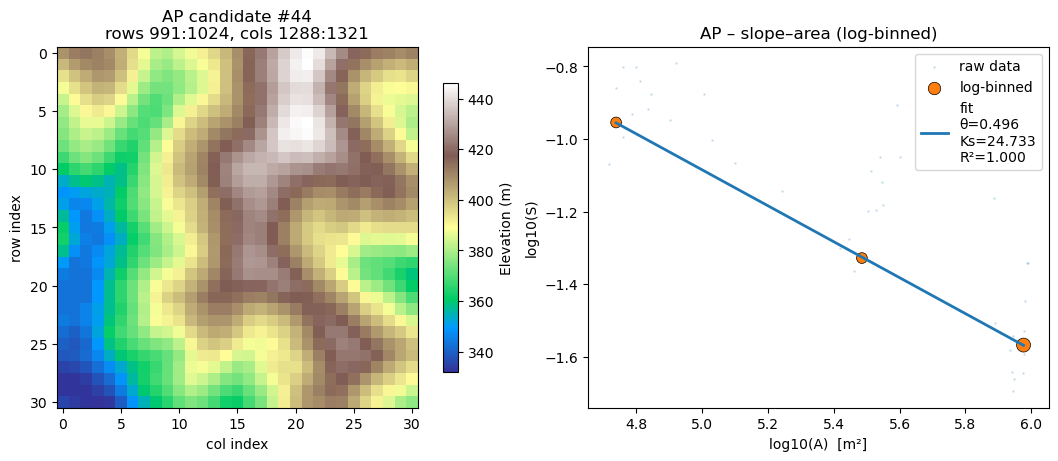


AP – candidate #45   (RMS = 0.489201)
Tile: rows 232:265, cols 826:859   (930 m × 930 m)

Results:
  Outlets: 4   Divides: 50   Valid curvatures: 48
  Median D: 1.06e-02 m²/yr  (IQR 7.2e-03–1.6e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.20  (Taylor   5.93)
  Ks (m): 28.308  (Taylor 47.200)
  θ      :  0.509  (Taylor  0.540)
  R²(sl–A fit): 0.928

Individual errors:
  Curvature:  +12.3%   Ks:  -40.0%   θ:   -5.7%
  3-term RMS error: 0.422598


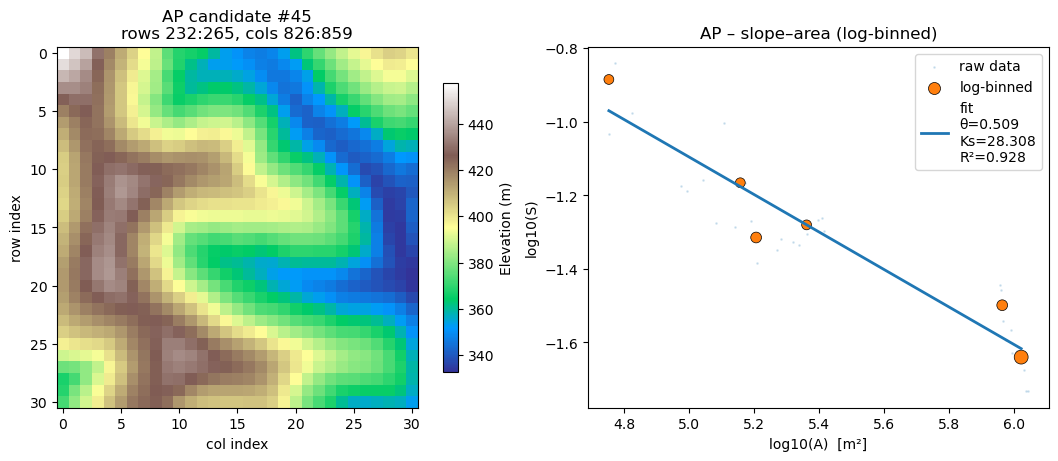


AP – candidate #46   (RMS = 0.497980)
Tile: rows 199:232, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 20   Valid curvatures: 18
  Median D: 1.16e-02 m²/yr  (IQR 7.0e-03–1.5e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.75  (Taylor   5.93)
  Ks (m): 36.758  (Taylor 47.200)
  θ      :  0.542  (Taylor  0.540)
  R²(sl–A fit): 0.862

Individual errors:
  Curvature:  +20.0%   Ks:  -22.1%   θ:   +0.3%
  3-term RMS error: 0.297925


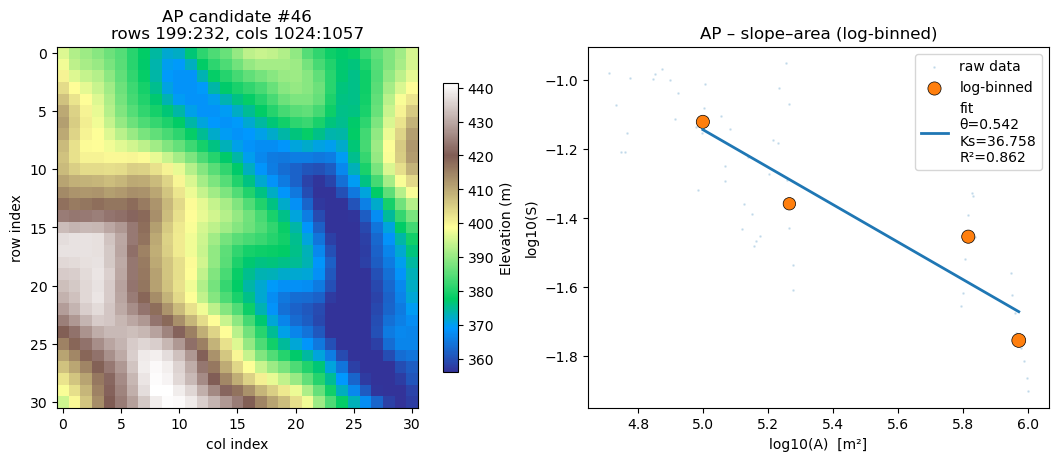


AP – candidate #47   (RMS = 0.512565)
Tile: rows 1057:1090, cols 1024:1057   (930 m × 930 m)

Results:
  Outlets: 7   Divides: 84   Valid curvatures: 79
  Median D: 8.65e-03 m²/yr  (IQR 5.9e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -6.36  (Taylor   5.93)
  Ks (m): 24.798  (Taylor 47.200)
  θ      :  0.482  (Taylor  0.540)
  R²(sl–A fit): 0.972

Individual errors:
  Curvature:   -7.2%   Ks:  -47.5%   θ:  -10.7%
  3-term RMS error: 0.491830


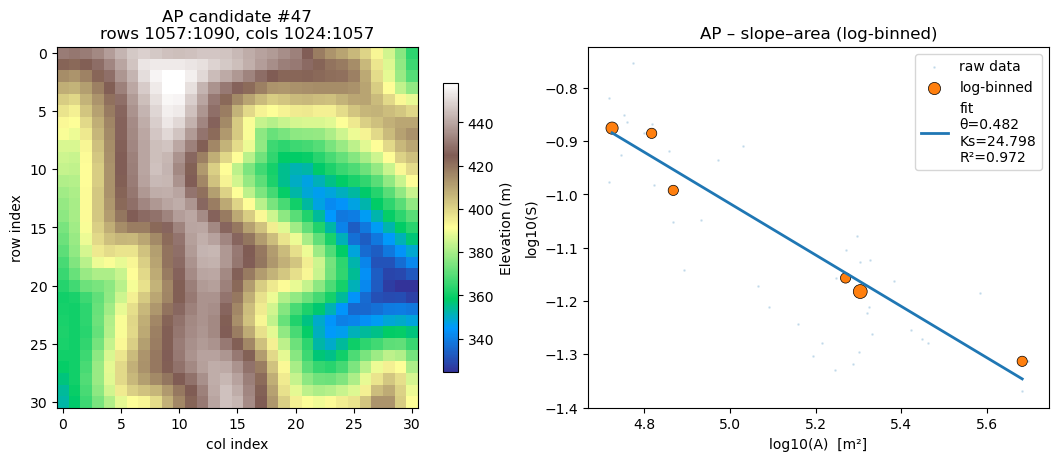


AP – candidate #48   (RMS = 0.522218)
Tile: rows 859:892, cols 694:727   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 65   Valid curvatures: 59
  Median D: 9.37e-03 m²/yr  (IQR 6.8e-03–1.2e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -5.87  (Taylor   5.93)
  Ks (m): 71.418  (Taylor 47.200)
  θ      :  0.591  (Taylor  0.540)
  R²(sl–A fit): 0.929

Individual errors:
  Curvature:   +1.1%   Ks:  +51.3%   θ:   +9.4%
  3-term RMS error: 0.521793


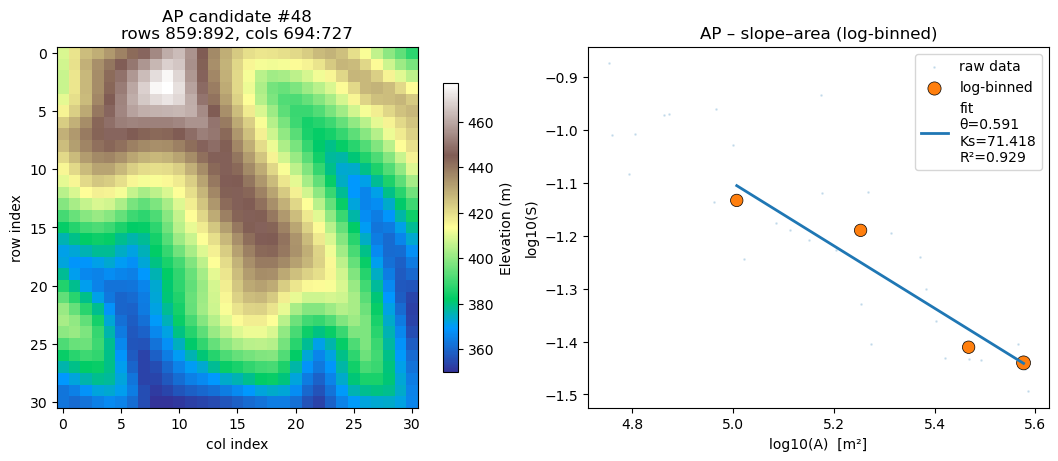


AP – candidate #49   (RMS = 0.538182)
Tile: rows 1222:1255, cols 661:694   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 66   Valid curvatures: 63
  Median D: 7.60e-03 m²/yr  (IQR 4.9e-03–1.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -7.24  (Taylor   5.93)
  Ks (m): 37.121  (Taylor 47.200)
  θ      :  0.539  (Taylor  0.540)
  R²(sl–A fit): 1.000

Individual errors:
  Curvature:  -22.1%   Ks:  -21.4%   θ:   -0.1%
  3-term RMS error: 0.307261


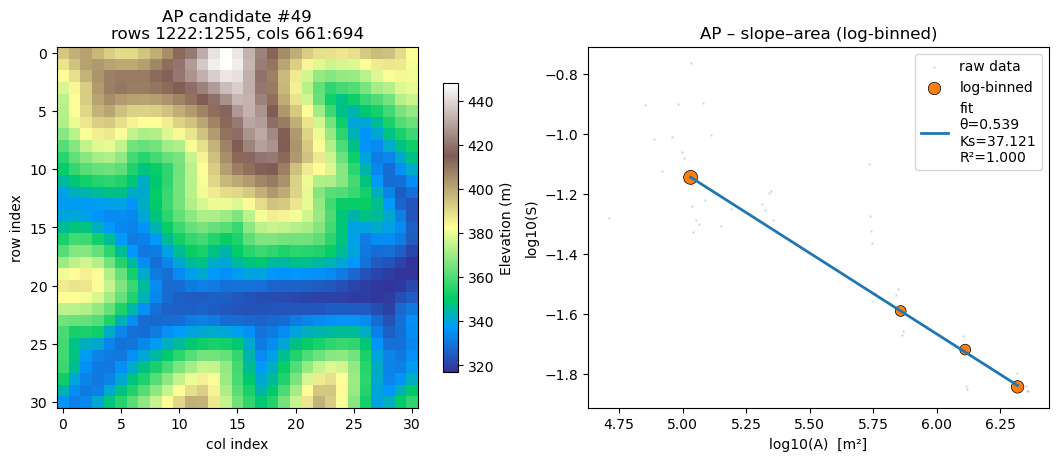


AP – candidate #50   (RMS = 0.549681)
Tile: rows 364:397, cols 760:793   (930 m × 930 m)

Results:
  Outlets: 6   Divides: 81   Valid curvatures: 80
  Median D: 1.16e-02 m²/yr  (IQR 7.6e-03–2.1e-02)

Comparison with Taylor et al. (2006):
  Curvature |∇²z| (10⁻³ m⁻¹):  -4.73  (Taylor   5.93)
  Ks (m): 32.618  (Taylor 47.200)
  θ      :  0.515  (Taylor  0.540)
  R²(sl–A fit): 0.914

Individual errors:
  Curvature:  +20.2%   Ks:  -30.9%   θ:   -4.7%
  3-term RMS error: 0.372183


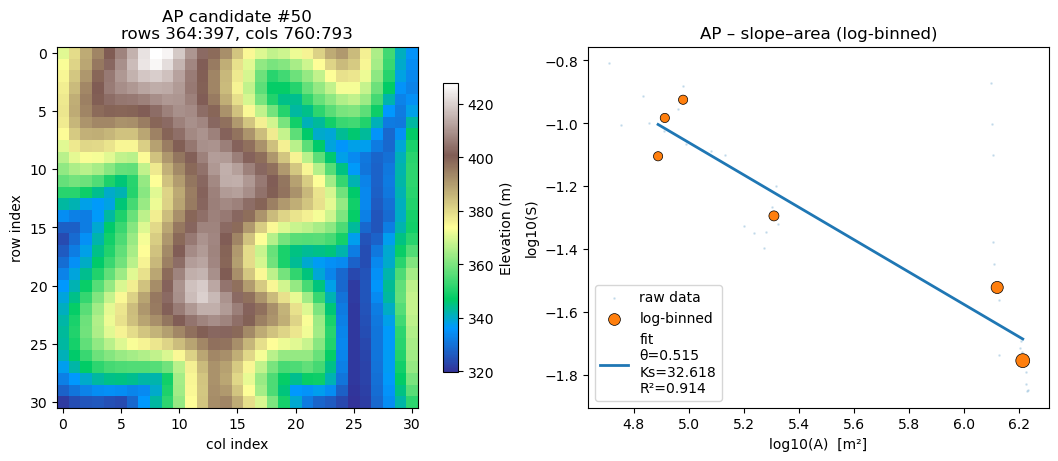


TILE ANALYSIS COMPLETE

Analysed successfully: 90/90 tiles


In [77]:
##### ── make sure this is imported / in scope somewhere above ───────────────
# from your_module import slope_area_regression_binned

import numpy as np
import matplotlib.pyplot as plt

# ════════════════════════════════════════════════════════════════════════
#  ANALYSIS OF SELECTED TILES  –  TOP-3 PER LANDSCAPE
# ════════════════════════════════════════════════════════════════════════
print("="*80)
print("ANALYSIS OF SELECTED TILES (TOP-3 PER LANDSCAPE)")
print("="*80)

results = {}

for tag in DATA:
    # -------------------------------------------------------------------
    if tag not in BEST_TILE:
        print(f"\n⚠️  Skipping {tag} – no tiles recorded")
        continue

    # --- load the *full* landscape (ignore any stored crop) -------------
    saved_crop          = DATA[tag]["crop"]   # remember single-best crop
    DATA[tag]["crop"]   = None                # disable cropping
    elev_full, area_full, fd_full, cfg = load_site(tag)
    DATA[tag]["crop"]   = saved_crop          # restore

    dx, U      = cfg["dx"], cfg["U"]
    ref        = TAYLOR_REF[tag]

    # -------------------------------------------------------------------
    for rank, (best_err, (rs, cs)) in enumerate(BEST_TILE[tag], 1):
        print(f"\n{'='*60}")
        print(f"{tag} – candidate #{rank}   (RMS = {best_err:.6f})")
        print(f"{'='*60}")

        # ---- crop the full grids to this candidate ---------------------
        elev, area, fd = crop((elev_full, area_full, fd_full),
                              extent_indexes=(rs.start, rs.stop, cs.start, cs.stop))
        ny, nx = elev._griddata.shape
        print(f"Tile: rows {rs.start}:{rs.stop}, cols {cs.start}:{cs.stop}   "
              f"({ny*dx} m × {nx*dx} m)")

        try:
            # —— curvature on first-order divides ————————————————
            curv_vals, divides, labels, outs = ta.extract_hilltop_curvature_first_order(
                elev, area, fd, ref["Acrit"], stencil=9)

            # —— diffusivity stats ————————————————————————————————
            D_stats, _      = ta.diffusivity_stats_new(curv_vals, U)
            D_med, D_iqr, _ = D_stats

            # —— channel steepness & concavity — LOG-BINNED regression —
            Ks, theta, sa_dbg = slope_area_regression_binned(
                elev, area, fd,
                min_area=ref["Acrit"],
                vertical_interval=10,   # keep your convention
                nbins=24,               # tweak if you prefer
                min_per_bin=10,
                agg="median",
                require_weighted=True,
                relax_if_sparse=True
            )

            # —— compute weighted R² on the binned regression points ——
            bA = np.asarray(sa_dbg["bin_logA"])
            bS = np.asarray(sa_dbg["bin_logS"])
            w  = np.asarray(sa_dbg.get("bin_counts", np.ones_like(bA)))

            m = np.isfinite(bA) & np.isfinite(bS) & (w > 0)
            if np.count_nonzero(m) >= 2:
                a = np.log10(Ks)              # intercept in log10 space
                yhat = a - theta * bA[m]
                y    = bS[m]
                ww   = w[m].astype(float)

                ybar   = np.sum(ww * y) / np.sum(ww)
                ss_res = np.sum(ww * (y - yhat)**2)
                ss_tot = np.sum(ww * (y - ybar)**2)
                r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else np.nan
            else:
                r2 = np.nan

            # —— store results ———————————————————————————————
            results[(tag, rank)] = dict(
                curvature=curv_vals, divides=divides, outlets=outs,
                Ks=Ks, theta=theta, r2=r2, D_stats=D_stats,
                elev=elev, area=area, fd=fd,
                sa_debug=sa_dbg,         # raw + binned arrays for plotting
                success=True
            )

            # —— reporting ————————————————————————————————
            # Positive magnitude for hilltop curvature (median hilltops are negative):
            med_curv_mag   = -np.median(curv_vals)      # > 0 for convex hilltops
            ks_target      = ref["ks"]
            theta_target   = ref["theta"]
            curv_tbl       = med_curv_mag*1e3           # ×10⁻³ m⁻¹ (positive)
            target_tbl     = -ref["curv"]*1e3           # if ref["curv"] is negative

            print("\nResults:")
            print(f"  Outlets: {len(outs)}   Divides: {len(divides)}   "
                  f"Valid curvatures: {len(curv_vals)}")
            print(f"  Median D: {D_med:.2e} m²/yr  "
                  f"(IQR {D_iqr[0]:.1e}–{D_iqr[1]:.1e})")

            print("\nComparison with Taylor et al. (2006):")
            print(f"  Curvature |∇²z| (10⁻³ m⁻¹): {curv_tbl:6.2f}  "
                  f"(Taylor {target_tbl:6.2f})")
            print(f"  Ks (m): {Ks:6.3f}  (Taylor {ks_target:6.3f})")
            print(f"  θ      : {theta:6.3f}  (Taylor {theta_target:6.3f})")
            print(f"  R²(sl–A fit): {r2:.3f}")

            # —— error metrics ——————————————————————————————
            # Note: this preserves your earlier convention of comparing the
            # positive magnitude med_curv_mag to ref["curv"] (typically negative).
            curv_err  = 100*(med_curv_mag - ref["curv"]) / abs(ref["curv"])
            ks_err    = 100*(Ks - ks_target) / ks_target
            theta_err = 100*(theta - theta_target) / theta_target
            rms_err   = np.sqrt((curv_err/100)**2 +
                                 (ks_err/100)**2 +
                                 (theta_err/100)**2)

            print("\nIndividual errors:")
            print(f"  Curvature: {curv_err:+6.1f}%   "
                  f"Ks: {ks_err:+6.1f}%   θ: {theta_err:+6.1f}%")
            print(f"  3-term RMS error: {rms_err:.6f}")

        except Exception as e:
            print(f"❌  Analysis failed: {e}")
            results[(tag, rank)] = dict(success=False, error=str(e))
            continue

        # ── quick elevation + slope–area plots for each candidate ───────
        fig, (ax_e, ax_sa) = plt.subplots(1, 2, figsize=(11, 4.5),
                                          constrained_layout=True)

        # Elevation
        im = ax_e.imshow(elev._griddata, cmap="terrain", origin="upper")
        ax_e.set_title(f"{tag} candidate #{rank}\nrows {rs.start}:{rs.stop}, cols {cs.start}:{cs.stop}")
        ax_e.set_xlabel("col index"); ax_e.set_ylabel("row index")
        plt.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

        # Slope–Area: raw + binned + fit
        logA_raw, logS_raw = sa_dbg["logA"], sa_dbg["logS"]
        ax_sa.scatter(logA_raw, logS_raw, s=1, alpha=0.15, label="raw data")

        bA, bS, bN = sa_dbg["bin_logA"], sa_dbg["bin_logS"], sa_dbg["bin_counts"]
        sizes = 20 + 80 * (bN / np.max(bN)) if np.max(bN) > 0 else 40
        ax_sa.scatter(bA, bS, s=sizes, edgecolor="k", linewidths=0.5, label="log-binned")

        x_fit = np.linspace(np.nanmin(bA), np.nanmax(bA), 2)
        ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2,
                   label=f"fit\nθ={theta:.3f}\nKs={Ks:.3f}\nR²={results[(tag, rank)]['r2']:.3f}")

        ax_sa.set_xlabel("log10(A)  [m²]")
        ax_sa.set_ylabel("log10(S)")
        ax_sa.set_title(f"{tag} – slope–area (log-binned)")
        ax_sa.legend(loc="best", frameon=True)

        plt.show()

# ────────────────────────────────────────────────────────────────────────

# ─── summary ─────────────────────────────────────────────────────────────
print("\n" + "="*80)
print("TILE ANALYSIS COMPLETE")
print("="*80)

success_count = sum(1 for v in results.values() if v.get('success'))
print(f"\nAnalysed successfully: {success_count}/{len(results)} tiles")


In [80]:
# ────────────────────────────────────────────────────────────────
#  UTM extent for the hand-picked tiles
#  (GM rows 2041-2191 / cols 901-1051;  AP rows 291-341 / cols 691-741)
# ────────────────────────────────────────────────────────────────
import rasterio

TILES = {
    "GM": dict(rows=(1801, 1901), cols=( 1001, 1101)),  # Tile: rows 1801:1901, cols 1001:1101   (980 m × 980 m)



    "AP": dict(rows=( 355,  388), cols=(637,  670)),   } #Tile: rows 355:388, cols 637:670   (930 m × 930 m)


def tile_bounds(transform, r0, r1, c0, c1):
    """
    Convert pixel-space tile limits (Python slices) to UTM coordinates.

    Parameters
    ----------
    transform : rasterio.transform.Affine
        Affine mapping from pixel-space to map-space.
    r0, r1 : int
        Slice start / stop rows   (NOTE: r1 is exclusive, just like Python slices).
    c0, c1 : int
        Slice start / stop cols   (c1 exclusive).

    Returns
    -------
    (west, east, south, north)  in metres
    """
    west  = transform.c + c0 * transform.a
    east  = transform.c + c1 * transform.a
    north = transform.f + r0 * transform.e     # transform.e is usually negative
    south = transform.f + r1 * transform.e
    return west, east, south, north


print("="*78)
print("UTM BOUNDING BOXES FOR SELECTED 1.5 km × 1.5 km TILES")
print("="*78)
print(f"{'Dataset':<6} {'West (mE)':>13} {'East (mE)':>13} "
      f"{'South (mN)':>13} {'North (mN)':>13}")

for tag, idx in TILES.items():
    path = DATA[tag]["elev"]          # path to the DEM you’re already using
    with rasterio.open(path) as src:
        tr = src.transform
    w, e, s, n = tile_bounds(tr,
                             idx["rows"][0], idx["rows"][1],
                             idx["cols"][0], idx["cols"][1])

    print(f"{tag:<6} {w:13.0f} {e:13.0f} {s:13.0f} {n:13.0f}")

print("\nCopy-and-paste those four numbers into your LiDAR-download or "
      "gdal_translate command to crop the raw LiDAR tiles.")


UTM BOUNDING BOXES FOR SELECTED 1.5 km × 1.5 km TILES
Dataset     West (mE)     East (mE)    South (mN)    North (mN)
GM            699991        700991       3981451       3982451
AP            556893        557883       4422470       4423460

Copy-and-paste those four numbers into your LiDAR-download or gdal_translate command to crop the raw LiDAR tiles.


In [89]:
# ─────────────────────────────────────────────────────────────────
#  LOG BINNED APPROACH
#  Curvature, log-binned Ks/θ, diffusivity, Taylor comparison
#  (printing style identical to 30 m workflow)
# ─────────────────────────────────────────────────────────────────
import numpy as np
from pathlib import Path
from TopoAnalysis import dem as d
import topo_analysis as ta

#  Assumes:
#    • diffusivity_stats_new is defined above
#    • TAYLOR_REF and DATA dictionaries are in memory

# ── log-binned slope–area regression (paste if not already imported) ───
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """Return (Ks, theta, debug) from a log-binned fit of log10 S vs log10 A."""
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            left, right = bin_edges[i], bin_edges[i+1]
            idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
            c = int(np.count_nonzero(idx))
            if c < min_required: continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3: break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)
    # Weighted least squares on binned aggregates
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0: raise RuntimeError("Zero variance in binned log10(A).")
    b1 = num / den
    b0 = wy - b1 * wx
    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=bin_edges)
    return Ks, theta, dbg

# ── inputs ──────────────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/")
tiles = {
    "AP": dict(prefix="AP_1m_best_tile_5", theta=0.54, Acrit=5.04e4),
    "GM": dict(prefix="GM_1m_best_tile_5",                theta=0.29, Acrit=1.0e4),
}

line = "-" * 60
for tag, cfg in tiles.items():
    print(f"Analyzing selected tile for {tag}\n{line}")

    stem   = tile_dir / cfg["prefix"]
    # filled acts as elevation for 1 m; no separate _elevation required
    filled = d.FilledElevation.load(str(stem) + "_filled")
    area   = d.Area.load(           str(stem) + "_area")
    fd     = d.FlowDirectionD8.load(str(stem) + "_fd")

    # 1) Hilltop curvature (positive magnitudes in m⁻¹ from TA helper)
    curv_vals_px, divides, labels, outs = ta.extract_hilltop_curvature_first_order(
        filled, area, fd, cfg["Acrit"], stencil=9
    )
    med_curv_mag = np.median(curv_vals_px)

    # 2) Ks & θ from LOG-BINNED slope–area on the 1 m data
    Ks, theta, _sa_dbg = slope_area_regression_binned(
        elev_obj=filled, area_obj=area, fd_obj=fd,
        min_area=cfg["Acrit"],
        vertical_interval=10,   # keep consistent smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # 3) Diffusivity stats
    U = DATA[tag]["U"]          # uplift rate (m/yr)
    D_stats, _ = ta.diffusivity_stats_new(curv_vals_px, U)
    D_med, (D_q25, D_q75), _ = D_stats

    # 4) Taylor reference & error metrics
    ref = TAYLOR_REF[tag]
    curv_target = abs(ref["curv"])
    Ks_target   = ref["ks"]

    curv_err  = 100 * (med_curv_mag - curv_target) / curv_target
    ks_err    = 100 * (Ks           - Ks_target)   / Ks_target
    theta_err = 100 * (theta        - ref["theta"]) / ref["theta"]
    rms_err   = np.sqrt((curv_err/100)**2 + (ks_err/100)**2 + (theta_err/100)**2)

    # 5) Report
    unit = "×10⁻³ m⁻¹"
    print("Comparison with Taylor et al. (2006):")
    print(f"  Curvature |∇²z| : {med_curv_mag*1e3:7.2f} {unit}  "
          f"(Taylor: {curv_target*1e3:6.2f} {unit})")
    print(f"  Channel steepness Ks (m):   {Ks:6.3f} "
          f"(Taylor: {Ks_target:6.3f})")
    print(f"  Channel concavity θ:        {theta:6.3f} "
          f"(Taylor: {ref['theta']:6.3f})\n")

    print("Individual errors:")
    print(f"  Curvature error:  {curv_err:+6.1f}%")
    print(f"  Steepness error:  {ks_err:+6.1f}%")
    print(f"  Concavity error:  {theta_err:+6.1f}%")
    print(f"  3-term RMS error: {rms_err:.6f}\n")

    print("Diffusivity statistics:")
    print(f"  Median D: {D_med:6.2e} m²/yr "
          f"(IQR: {D_q25:6.2e} – {D_q75:6.2e})")
    print(line, "\n")


Analyzing selected tile for AP
------------------------------------------------------------
Comparison with Taylor et al. (2006):
  Curvature |∇²z| : 1096.06 ×10⁻³ m⁻¹  (Taylor:   5.93 ×10⁻³ m⁻¹)
  Channel steepness Ks (m):   129.417 (Taylor: 47.200)
  Channel concavity θ:         0.564 (Taylor:  0.540)

Individual errors:
  Curvature error:  +18383.2%
  Steepness error:  +174.2%
  Concavity error:    +4.5%
  3-term RMS error: 183.840671

Diffusivity statistics:
  Median D: 5.02e-05 m²/yr (IQR: 2.91e-05 – 9.91e-05)
------------------------------------------------------------ 

Analyzing selected tile for GM
------------------------------------------------------------
Comparison with Taylor et al. (2006):
  Curvature |∇²z| :  125.17 ×10⁻³ m⁻¹  (Taylor:  12.80 ×10⁻³ m⁻¹)
  Channel steepness Ks (m):    5.194 (Taylor:  1.900)
  Channel concavity θ:         0.356 (Taylor:  0.292)

Individual errors:
  Curvature error:  +877.9%
  Steepness error:  +173.4%
  Concavity error:   +22.1%
  3-term

In [90]:
# ──────────────────────────────────────────────────────────────────────────
# LOG BINNED VERSION 
#    LOW-PASS vs. SUBSAMPLED analysis for 1 m best-fit tiles  – log-binned Ks/θ
#
#  • Requires:
#        from TopoAnalysis import dem as d
#        import topo_analysis as ta
#        plus   DATA   and   TAYLOR_REF   dicts in memory
#  • Computes curvature, Ks, θ, and diffusivity for:
#        ① Gaussian-blurred 1 m grids (low-pass)
#        ② Block-mean 10 m (GM) / 30 m (AP) grids (subsampled)
#  • Uses log-binned slope–area regression for Ks and θ
# ──────────────────────────────────────────────────────────────────────────
import numpy as np, copy
from pathlib import Path
from scipy.ndimage import gaussian_filter
from TopoAnalysis import dem as d

# ─── log-binned slope–area regression ────────────────────────────────────
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """
    Fit log10(S) vs log10(A) using log-binned aggregates to obtain Ks and theta.
    Returns (Ks, theta, debug).
    """
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")

    bin_edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            left, right = bin_edges[i], bin_edges[i+1]
            idx = (logA >= left) & (logA < right) if i < nbins - 1 else (logA >= left) & (logA <= right)
            c = int(np.count_nonzero(idx))
            if c < min_required: continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3: break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)

    # Weighted least squares on binned aggregates
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")

    b1 = num / den
    b0 = wy - b1 * wx

    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=bin_edges)
    return Ks, theta, dbg

# ─── helper functions ─────────────────────────────────────────────────────
def fwhm_to_sigma(fwhm_m):
    """Gaussian σ (pixels) from FWHM in metres (native px = 1 m)."""
    return fwhm_m / (2 * np.sqrt(2 * np.log(2)))

def block_mean(arr, k):
    """Down-sample *arr* by integer factor *k* via block averaging."""
    ny, nx = arr.shape
    return (arr[:ny//k*k, :nx//k*k]          # truncate so divisible by k
              .reshape(ny//k, k, nx//k, k)
              .mean(axis=(1, 3)))

def analyse_variant(elev_for_curv, elev_for_slope, area, fd, acrit, tag, dx_out):
    """
    Run curvature → log-binned Ks/θ → diffusivity and return summary dict.
      elev_for_curv : Elevation object for curvature extraction
      elev_for_slope: Elevation object used in slope calc (often same as above)
      area, fd      : corresponding Area and FlowDirectionD8 objects
      acrit         : min contributing area (m²)
      dx_out        : effective output pixel size (m) for vertical_interval scaling
    """
    # Hilltop curvature (positive magnitudes in m⁻¹)
    curv_vals, divides, _, _ = ta.extract_hilltop_curvature_first_order(
        elev_for_curv, area, fd, acrit, stencil=9)
    curv_med = np.median(curv_vals)

    # Log-binned Ks & theta at this effective resolution
    vertical_interval = 10.0   # keep your smoothing convention
    Ks, theta, _ = slope_area_regression_binned(
        elev_for_slope, area, fd, min_area=acrit,
        vertical_interval=vertical_interval,
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # Diffusivity stats
    U = DATA[tag]["U"]
    D_stats, _ = ta.diffusivity_stats_new(curv_vals, U)
    D_med, D_IQR, _ = D_stats

    return dict(curv=curv_med, Ks=Ks, theta=theta,
                D_med=D_med, D_IQR=D_IQR, dx=dx_out)

def print_report(tag, label, stats):
    ref = TAYLOR_REF[tag]
    curv_ref, ks_ref, th_ref = abs(ref["curv"]), ref["ks"], ref["theta"]
    errs = [(stats["curv"]  - curv_ref)/curv_ref,
            (stats["Ks"]    - ks_ref)  /ks_ref,
            (stats["theta"] - th_ref)  /th_ref]
    rms = np.sqrt(np.square(errs).sum())
    print(f"\n--- {label:<9} (dx = {int(stats['dx']):>3} m) ---")
    u = "×10⁻³ m⁻¹"
    print(f"|∇²z|  : {stats['curv']*1e3:7.2f} {u}  "
          f"(Taylor {curv_ref*1e3:6.2f} {u})  "
          f"err {errs[0]*100:+6.1f}%")          
    print(f"Ks     : {stats['Ks']:7.3f}             (Taylor {ks_ref:6.3f})  "
          f"err {errs[1]*100:+6.1f}%")
    print(f"θ      : {stats['theta']:7.3f}             (Taylor {th_ref:6.3f})  "
          f"err {errs[2]*100:+6.1f}%")
    print(f"D_med  : {stats['D_med']:.2e}  (IQR {stats['D_IQR'][0]:.1e}–{stats['D_IQR'][1]:.1e})")
    print(f"RMS (3-term) = {rms:.6f}")

# ─── per-tile configuration ───────────────────────────────────────────────

tile_dir = Path("data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/")
tiles = {
    "AP": dict(prefix="AP_1m_best_tile_5", theta=0.54, Acrit=5.04e4, fwhm=30, subs=30),
    "GM": dict(prefix="GM_1m_best_tile_5",                theta=0.29, Acrit=1.0e4, fwhm=10, subs=10),
}
# ─── main loop ────────────────────────────────────────────────────────────
for tag, cfg in tiles.items():
    print(f"\n======== {tag}  (filter {cfg['fwhm']} m  |  subs {cfg['subs']} m) ========")

    # Load native 1 m datasets (filled acts as elevation)
    stem = tile_dir / cfg["prefix"]
    fill1 = d.FilledElevation.load(str(stem) + "_filled")
    area1 = d.Area.load(           str(stem) + "_area")
    fd1   = d.FlowDirectionD8.load(str(stem) + "_fd")

    z_native = fill1._griddata.copy()

    # LOW-PASS branch -------------------------------------------------------
    z_lp = gaussian_filter(z_native, sigma=fwhm_to_sigma(cfg["fwhm"]), mode="nearest")
    elev_lp = copy.deepcopy(fill1);  elev_lp._griddata = z_lp
    fill_lp = elev_lp  # same array for slope calculation

    stats_lp = analyse_variant(elev_lp, fill_lp, area1, fd1,
                               cfg["Acrit"], tag, dx_out=1)
    print_report(tag, "low-pass", stats_lp)

    # SUBSAMPLED branch -----------------------------------------------------
    k = cfg["subs"]
    z_sub = block_mean(z_native, k)

    # Build 1:k subsampled Elevation/Fill with updated georef
    elev_sub = copy.deepcopy(fill1)
    elev_sub._griddata = z_sub
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny  = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx  = z_sub.shape[1]
    fill_sub = elev_sub  # same array for slope

    # Rebuild flow direction & area at subsampled resolution
    fd_sub   = d.FlowDirectionD8(flooded_dem=fill_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    stats_sub = analyse_variant(elev_sub, fill_sub, area_sub, fd_sub,
                                cfg["Acrit"], tag, dx_out=k)
    print_report(tag, "subsample", stats_sub)



======== AP  (filter 30 m  |  subs 30 m) ========

--- low-pass  (dx =   1 m) ---
|∇²z|  :   14.08 ×10⁻³ m⁻¹  (Taylor   5.93 ×10⁻³ m⁻¹)  err +137.5%
Ks     :  94.912             (Taylor 47.200)  err +101.1%
θ      :   0.533             (Taylor  0.540)  err   -1.2%
D_med  : 3.91e-03  (IQR 2.7e-03–7.1e-03)
RMS (3-term) = 1.706249

--- subsample (dx =  30 m) ---
|∇²z|  :   21.99 ×10⁻³ m⁻¹  (Taylor   5.93 ×10⁻³ m⁻¹)  err +270.9%
Ks     : 123.654             (Taylor 47.200)  err +162.0%
θ      :   0.599             (Taylor  0.540)  err  +11.0%
D_med  : 2.50e-03  (IQR 1.8e-03–3.9e-03)
RMS (3-term) = 3.157893

======== GM  (filter 10 m  |  subs 10 m) ========

--- low-pass  (dx =   1 m) ---
|∇²z|  :   11.34 ×10⁻³ m⁻¹  (Taylor  12.80 ×10⁻³ m⁻¹)  err  -11.4%
Ks     :   5.658             (Taylor  1.900)  err +197.8%
θ      :   0.363             (Taylor  0.292)  err  +24.4%
D_med  : 1.30e-02  (IQR 8.2e-03–2.2e-02)
RMS (3-term) = 1.995882

--- subsample (dx =  10 m) ---
|∇²z|  :   16.35 ×10⁻³ m⁻¹

AP: concavity θ = 0.564   steepness Ks = 129.417
GM: concavity θ = 0.356   steepness Ks = 5.194


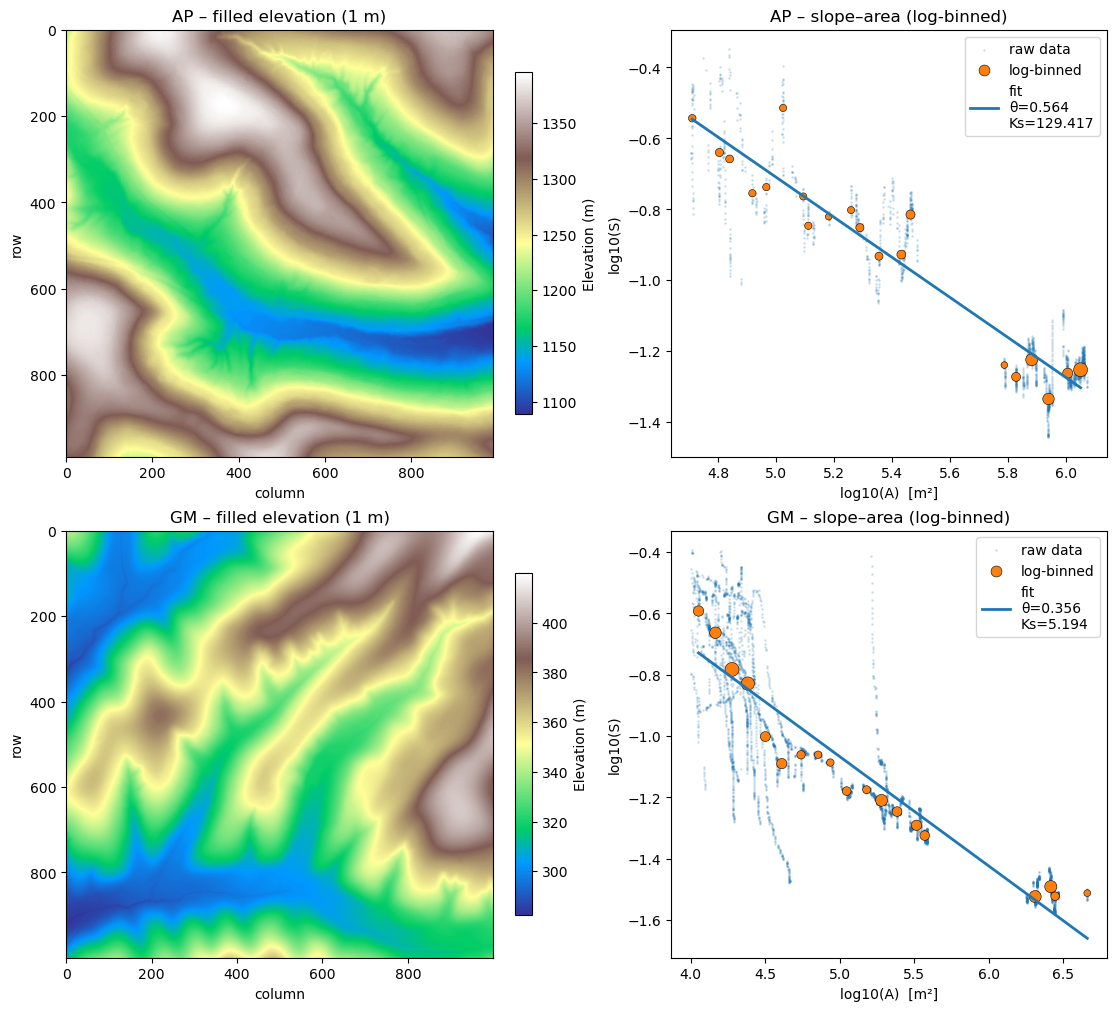

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from TopoAnalysis import dem as d  # TopoAnalysis must be on PYTHONPATH

# ── config ───────────────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/")
tiles = {
    "AP": dict(prefix="AP_1m_best_tile_5", theta=0.54, Acrit=5.04e4, fwhm=30, subs=30),
    "GM": dict(prefix="GM_1m_best_tile_5",                theta=0.29, Acrit=1.0e4, fwhm=10, subs=10),
}

# ── helpers ──────────────────────────────────────────────────────────────
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10.0, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """Fit log10(S) vs log10(A) using log-binned aggregates → (Ks, theta, dbg)."""
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            L, R = edges[i], edges[i+1]
            idx = (logA >= L) & (logA < R) if i < nbins - 1 else (logA >= L) & (logA <= R)
            c = int(np.count_nonzero(idx))
            if c < min_required: 
                continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3:
                break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")
    b1 = num / den
    b0 = wy - b1 * wx
    Ks = 10**b0
    theta = -b1
    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=edges)
    return Ks, theta, dbg


# ── plotting canvas ──────────────────────────────────────────────────────
nrows = len(tiles)
fig, axes = plt.subplots(nrows, 2, figsize=(11, 5*nrows), constrained_layout=True)
if nrows == 1:
    axes = np.array([axes])  # 2-D for uniform indexing

# ── loop over tiles ──────────────────────────────────────────────────────
for row, (tag, cfg) in enumerate(tiles.items()):
    stem = tile_dir / cfg["prefix"]
    fill = d.FilledElevation.load(str(stem) + "_filled")
    area = d.Area.load(           str(stem) + "_area")
    fd   = d.FlowDirectionD8.load(str(stem) + "_fd")

    # ── elevation plot
    ax_e = axes[row, 0]
    im = ax_e.imshow(fill._griddata, cmap="terrain", origin="upper")
    ax_e.set_title(f"{tag} – filled elevation (1 m)")
    ax_e.set_xlabel("column"); ax_e.set_ylabel("row")
    fig.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

    # ── slope–area (log-binned) regression
    Ks, theta, dbg = slope_area_regression_binned(
        elev_obj=fill, area_obj=area, fd_obj=fd,
        min_area=cfg["Acrit"],
        vertical_interval=10.0,   # match 30 m workflow smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # ── slope–area plot: raw + binned + fit
    ax_sa = axes[row, 1]
    logA_raw, logS_raw = dbg["logA"], dbg["logS"]
    ax_sa.scatter(logA_raw, logS_raw, s=1, alpha=0.15, label="raw data")

    bA, bS, bN = dbg["bin_logA"], dbg["bin_logS"], dbg["bin_counts"]
    size = 20 + 80 * (bN / bN.max()) if bN.size and bN.max() > 0 else 40
    ax_sa.scatter(bA, bS, s=size, edgecolor="k", linewidths=0.4, label="log-binned")

    x_fit = np.linspace(bA.min(), bA.max(), 2)
    ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2,
               label=f"fit\nθ={theta:.3f}\nKs={Ks:.3f}")

    ax_sa.set_xlabel("log10(A)  [m²]")
    ax_sa.set_ylabel("log10(S)")
    ax_sa.set_title(f"{tag} – slope–area (log-binned)")
    ax_sa.legend(loc="best", frameon=True)

    # ── console output
    print(f"{tag}: concavity θ = {theta:.3f}   steepness Ks = {Ks:.3f}")

plt.show()


In [92]:
# ─────────────────────────────────────────────────────────────────────────
#  FINAL DATA TABLE
# ─────────────────────────────────────────────────────────────────────────
FINAL_DATA_TABLE = {
    "GM": dict(
        curv  = -1.281e-02,   # m⁻¹, our measurement
        U     = 147.0,        # m Myr⁻¹ (Taylor)
        K     = 100.2,        # m¹⁻²ᵐ Myr⁻¹ (Taylor)
        Ks    = 1.9,          # χ-based
        D     = 124.0 / 1e4,  # cm²/yr → m²/yr
        Acrit = 1.0e4,        # m²
        theta = 0.292         # χ-based
    ),
    "AP": dict(
        curv  = -5.930e-03,
        U     = 55.0,
        K     = 12.5,
        Ks    = 47.2,
        D     = 100.0 / 1e4,
        Acrit = 5.04e4,
        theta = 0.54
    ),
}

# ----------------------------------------------------------------------
#  FINAL SUMMARY (uses FINAL_DATA_TABLE with Ks and D fields)
#  • Ks, θ, R² from LOG-BINNED slope–area (vertical_interval = 10 m)
#  • filled == elevation
#  • Area grids normalized to m² to avoid Ks drift
# ----------------------------------------------------------------------
from pathlib import Path
import numpy as np
import copy
from TopoAnalysis import dem as d
import topo_analysis as ta   # for curvature

# ── helpers ──────────────────────────────────────────────────────────────
def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10.0, nbins=24, min_per_bin=10,
    agg="median", require_weighted=True, relax_if_sparse=True
):
    """
    Fit log10(S) vs log10(A) using log-binned aggregates (weighted LS)
    Returns: Ks, theta, r2, dbg
      - Ks, theta: fit parameters (log10 S = log10 Ks − theta * log10 A)
      - r2: weighted coefficient of determination on binned points
      - dbg: dict with raw and binned arrays for plotting/inspection
    """
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)
    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = np.min(logA), np.max(logA)
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            L, R = edges[i], edges[i+1]
            idx = (logA >= L) & (logA < R) if i < nbins-1 else (logA >= L) & (logA <= R)
            c = int(np.count_nonzero(idx))
            if c < min_required:
                continue
            a_val = np.median(logA[idx]) if agg == "median" else np.mean(logA[idx])
            s_val = np.median(logS[idx]) if agg == "median" else np.mean(logS[idx])
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return outA, outS, outN

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and len(bA) < 3:
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if len(bA) >= 3:
                break
    if len(bA) < 3:
        raise ValueError("Too few populated bins for regression.")

    bA = np.asarray(bA); bS = np.asarray(bS); w = np.asarray(w, float)

    # Weighted LS in log space
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den == 0:
        raise RuntimeError("Zero variance in binned log10(A).")

    b1 = num / den
    b0 = wy - b1 * wx

    Ks    = 10**b0
    theta = -b1

    # Weighted R² on binned points
    yhat = b0 + b1 * bA          # NOTE: y = b0 + b1*x
    y    = bS
    ybar = wy
    ss_res = np.sum(w * (y - yhat)**2)
    ss_tot = np.sum(w * (y - ybar)**2)
    r2 = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan

    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w)
    return Ks, theta, r2, dbg

def block_mean(arr, k):
    ny, nx = arr.shape
    return (arr[:ny//k*k, :nx//k*k]
              .reshape(ny//k, k, nx//k, k)
              .mean(axis=(1, 3)))

# ── paths & config ───────────────────────────────────────────────────────
tile_dir = Path("data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/")
tiles = {
    "AP": dict(prefix="AP_1m_best_tile_5", theta=0.54, Acrit=5.04e4, fwhm=30, subs=30),
    "GM": dict(prefix="GM_1m_best_tile_5", theta=0.29, Acrit=1.0e4, fwhm=10,  subs=10),
}

# ── main ─────────────────────────────────────────────────────────────────
for tag, cfg in tiles.items():
    print("\n" + "="*70)
    print(f"{tag}  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)")
    print("="*70)

    # ---- load native 1-m filled DEM, area, FD ------------------------
    stem  = tile_dir / cfg["prefix"]
    fill1 = d.FilledElevation.load(str(stem) + "_filled")  # elevation == filled
    area1 = d.Area.load(           str(stem) + "_area")
    fd1   = d.FlowDirectionD8.load(str(stem) + "_fd")

    # ---- high-resolution Ks, θ, R² via LOG-BINNED fit ---------------
    Acrit = FINAL_DATA_TABLE[tag].get("Acrit", cfg["Acrit"])
    Ks_hr, theta_hr, r2_hr, sa_dbg = slope_area_regression_binned(
        fill1, area1, fd1, min_area=Acrit,
        vertical_interval=10.0,          # match 30 m workflow smoothing
        nbins=24, min_per_bin=10, agg="median",
        require_weighted=True, relax_if_sparse=True
    )

    # ---- subsampled grid for diffusivity ----------------------------
    k = cfg["subs"]
    z_sub = block_mean(fill1._griddata, k)
    elev_sub = copy.deepcopy(fill1); elev_sub._griddata = z_sub
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny  = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx  = z_sub.shape[1]

    # recompute flow & area at subsampled scale
    fd_sub   = d.FlowDirectionD8(flooded_dem=elev_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    curv_vals, *_ = ta.extract_hilltop_curvature_first_order(
        elev_sub, area_sub, fd_sub, Acrit, stencil=9
    )

    # ---- robust diffusivity from hilltop curvature ------------------
    U_m_per_Myr = FINAL_DATA_TABLE[tag]["U"]
    U_m_per_yr  = U_m_per_Myr / 1e6

    curv_vals = np.asarray(curv_vals, float)
    m_finite  = np.isfinite(curv_vals)
    curv_clean = curv_vals[m_finite]
    if curv_clean.size == 0:
        raise ValueError("No finite hilltop curvature values available for D calculation.")

    curv_neg = curv_clean[curv_clean < 0]
    if curv_neg.size >= 5:
        curv_mag = np.median(-curv_neg)        # positive magnitude
    elif curv_clean.size >= 10:
        curv_mag = np.median(np.abs(curv_clean))
    else:
        raise ValueError(
            f"Too few valid hilltop curvature samples (neg={curv_neg.size}, total={curv_clean.size})."
        )

    if not np.isfinite(curv_mag) or curv_mag <= 0:
        raise ValueError(f"Invalid curvature magnitude for D calculation (curv_mag={curv_mag}).")

    D_med = U_m_per_yr / curv_mag

    # ---- pull reference numbers -------------------------------------
    Ks_ref    = FINAL_DATA_TABLE[tag]["Ks"]
    theta_ref = FINAL_DATA_TABLE[tag]["theta"]
    D_ref     = FINAL_DATA_TABLE[tag]["D"]

    # ---- percent differences ----------------------------------------
    err_Ks = 100*(Ks_hr    - Ks_ref)    / Ks_ref
    err_th = 100*(theta_hr - theta_ref) / theta_ref
    err_D  = 100*(D_med    - D_ref)     / D_ref

    # ---- print summary (now includes R²) -----------------------------
    print("High-resolution (1 m) regression (log-binned):")
    print(f"  Ks      = {Ks_hr:8.3f} m   (Final {Ks_ref:6.3f})   Δ {err_Ks:+6.1f}%")
    print(f"  θ       = {theta_hr:8.3f}     (Final {theta_ref:6.3f})   Δ {err_th:+6.1f}%")
    print(f"  R²      = {r2_hr:8.3f}     (log-binned, weighted by bin counts)")

    print("\nDiffusivity from subsampled curvature:")
    print(f"  D_med   = {D_med:.2e} m²/yr   (Final {D_ref:.2e})   Δ {err_D:+6.1f}%")
    print("-"*70)



AP  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)
High-resolution (1 m) regression (log-binned):
  Ks      =  129.417 m   (Final 47.200)   Δ +174.2%
  θ       =    0.564     (Final  0.540)   Δ   +4.5%
  R²      =    0.922     (log-binned, weighted by bin counts)

Diffusivity from subsampled curvature:
  D_med   = 2.50e-03 m²/yr   (Final 1.00e-02)   Δ  -75.0%
----------------------------------------------------------------------

GM  –  FINAL SUMMARY (updated refs, log-binned Ks/θ)
High-resolution (1 m) regression (log-binned):
  Ks      =    5.194 m   (Final  1.900)   Δ +173.4%
  θ       =    0.356     (Final  0.292)   Δ  +22.1%
  R²      =    0.935     (log-binned, weighted by bin counts)

Diffusivity from subsampled curvature:
  D_med   = 8.99e-03 m²/yr   (Final 1.24e-02)   Δ  -27.5%
----------------------------------------------------------------------


[LOAD] AP: grid 990×990, dx=0.9998259595959833 m
[OUTLETS] coastline outlets: 11844
[SELECT] Using ALL coastline outlets: 11844 (no filtering)
[BASINS] using 11844 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse done in 13.3s
[OPT] refine around θ=0.550 → [0.490, 0.610] …
[OPT] refine done in 14.2s

[RESULT] θ*_coarse=0.550  SSR=2.563e+05
[RESULT] θ*_refine=0.562  SSR=2.550e+05


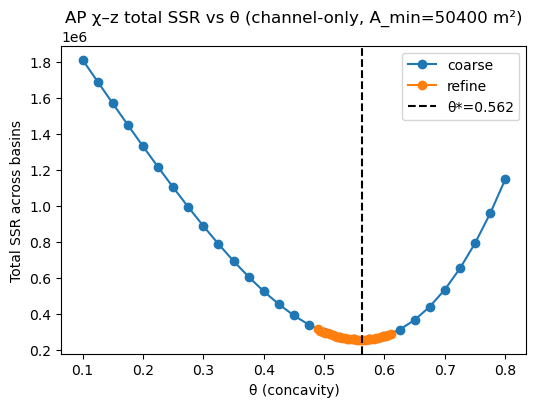


[QUALITY @ θ*=0.562]
  ks median=138.5288
  RMSE (m): median=4.50  IQR=(4.49, 4.50)  min/max=(0.02, 4.51)  n=6
  R²₀:      median=0.997  IQR=(0.997, 0.997)  min/max=(0.682, 0.997)  n=6
  nRMSE:    median=0.031  IQR=(0.031, 0.031)
  Global RMS per point ≈ 4.50 m


In [93]:
# ===============================================
# χ-based concavity optimization (final settings)
# Channel-only χ (stream_A_min = A_MIN), no caps
# With option to bypass outlet filtering and use ALL outlets
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/AP_1m_best_tile_1_filled",
        area="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/AP_1m_best_tile_1_area",
        flow="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/AP_1m_best_tile_1_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/GM_1m_best_tile_1_filled",  # or GM_10mN_filled / combined
        area="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/GM_1m_best_tile_1_area",
        flow="data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis/GM_1m_best_tile_1_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "AP"  # <-- change to "GM" as needed
USE_ALL_OUTLETS = True   # <-- set True to bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000); None = use all selected

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None: 
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    # Use ALL outlets; attach area if finite (NaN otherwise). No filtering here.
    chosen_all = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen_all.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen_all)} (no filtering)")
    chosen = chosen_all
else:
    # Original “good outlet” filter
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]): 
            nan_elev += 1; 
            continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; 
            continue
        if upstream_deg(i, j) <= 0:
            no_up += 1
            continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

# Optional cap
if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4) χ traversal (channel-only, no caps)
# -----------------------
def chi_traverse(theta, root_ij, A, Z, fd, dx, stream_A_min):
    """
    Compute (chi, z - z0) for one basin by upstream D8 walk.
    Channel-only: require A >= stream_A_min.
    No visit/time caps.
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

# -----------------------
# 5) θ optimization (coarse→refine) on total SSR across basins
# -----------------------
def total_ssr_for_theta(theta, outlets):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        x, y = chi_traverse(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)
coarse = []
t0 = time.time()
for th in coarse_thetas:
    coarse.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] coarse done in {time.time()-t0:.1f}s")

best_th_coarse, best_ssr_coarse = min(coarse, key=lambda kv: kv[1])
lo = max(0.10, best_th_coarse - 0.06)
hi = min(0.80, best_th_coarse + 0.06)

print(f"[OPT] refine around θ={best_th_coarse:.3f} → [{lo:.3f}, {hi:.3f}] …")
refine_thetas = np.linspace(lo, hi, 31)
refine = []
t1 = time.time()
for th in refine_thetas:
    refine.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] refine done in {time.time()-t1:.1f}s")

best_th_refine, best_ssr_refine = min(refine, key=lambda kv: kv[1])
theta_star = best_th_refine
print(f"\n[RESULT] θ*_coarse={best_th_coarse:.3f}  SSR={best_ssr_coarse:.3e}")
print(f"[RESULT] θ*_refine={best_th_refine:.3f}  SSR={best_ssr_refine:.3e}")

plt.figure(figsize=(6,4))
plt.plot([t for t,_ in coarse], [s for _,s in coarse], 'o-', label='coarse')
plt.plot([t for t,_ in refine], [s for _,s in refine], 'o-', label='refine')
plt.axvline(best_th_refine, color='k', ls='--', label=f'θ*={best_th_refine:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only, A_min={A_MIN:.0f} m²)")
plt.legend(); plt.show()

# -----------------------
# 6) Fit-quality diagnostics at θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

rows = []
total_n = 0
total_ssr = 0.0
for bi, (i0, j0, a0) in enumerate(chosen, 1):
    x, y = chi_traverse(theta_star, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
    if x.size < 3:
        rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                         ssr=np.nan, relief=np.nan, nrmse=np.nan))
        continue
    den = float(np.dot(x, x))
    ks = float(np.dot(x, y) / den) if den > 0 else np.nan
    yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
    R2, ssr = r2_through_origin(y, yhat)
    rmse = math.sqrt(ssr / y.size)
    relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
    nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

    total_n += y.size
    if np.isfinite(ssr): total_ssr += ssr
    rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                     ssr=ssr, relief=relief, nrmse=nrmse))

def stats(arr):
    arr = np.array([v for v in arr if np.isfinite(v)])
    if arr.size == 0:
        return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
    return dict(med=float(np.median(arr)),
                p25=float(np.percentile(arr, 25)),
                p75=float(np.percentile(arr, 75)),
                mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

rmse_stats = stats([r['rmse'] for r in rows])
r2_stats   = stats([r['r2']   for r in rows])
nrmse_stats= stats([r['nrmse']for r in rows])
rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan

print(f"\n[QUALITY @ θ*={theta_star:.3f}]")
print(f"  ks median={np.nanmedian([r['ks'] for r in rows]):.4f}")
print(f"  RMSE (m): median={rmse_stats['med']:.2f}  IQR=({rmse_stats['p25']:.2f}, {rmse_stats['p75']:.2f})  "
      f"min/max=({rmse_stats['mn']:.2f}, {rmse_stats['mx']:.2f})  n={rmse_stats['n']}")
print(f"  R²₀:      median={r2_stats['med']:.3f}  IQR=({r2_stats['p25']:.3f}, {r2_stats['p75']:.3f})  "
      f"min/max=({r2_stats['mn']:.3f}, {r2_stats['mx']:.3f})  n={r2_stats['n']}")
print(f"  nRMSE:    median={nrmse_stats['med']:.3f}  IQR=({nrmse_stats['p25']:.3f}, {nrmse_stats['p75']:.3f})")
print(f"  Global RMS per point ≈ {rms_total:.2f} m")


In [94]:
# ===============================================
# χ-based concavity optimization – batch runner
# Iterates AP_1..5 and GM_1..5; reports θ*, Ks, R²
# Channel-only χ (A >= A_MIN), no caps; ALL outlets optional
# ===============================================
import numpy as np, math, time
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry (templates for _1.._5)
# -----------------------
BASE = "data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis"
DATA = {
    "AP": dict(
        elev=f"{BASE}/AP_1m_best_tile_{{i}}_filled",
        area=f"{BASE}/AP_1m_best_tile_{{i}}_area",
        flow=f"{BASE}/AP_1m_best_tile_{{i}}_fd",
        A_MIN=5.04e4,   # Taylor AP threshold (m^2)
    ),
    "GM": dict(
        elev=f"{BASE}/GM_1m_best_tile_{{i}}_filled",
        area=f"{BASE}/GM_1m_best_tile_{{i}}_area",
        flow=f"{BASE}/GM_1m_best_tile_{{i}}_fd",
        A_MIN=1.0e4,    # Taylor GM threshold (m^2)
    ),
}

# -----------------------
# 1) knobs
# -----------------------
USE_ALL_OUTLETS = True   # True = bypass outlet filtering; use ALL coastline outlets
N_BASINS = None          # optional cap on basins per tile; None = all
COARSE_GRID = np.linspace(0.10, 0.80, 29)
REFINE_HALFSPAN = 0.06
REFINE_STEPS = 31

# -----------------------
# 2) utilities
# -----------------------
def upstream_deg(fd, Z, i, j):
    """Count finite upstream neighbors."""
    ny, nx = Z.shape
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None:
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

def chi_traverse(theta, root_ij, A, Z, fd, dx, stream_A_min):
    """
    Compute (chi, z - z0) by upstream D8 walk (channel-only: A >= stream_A_min).
    """
    ny, nx = Z.shape
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None:
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]:
                continue
            if not np.isfinite(Z[ui, uj]):
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

def ols_origin(x, y):
    """Slope (Ks surrogate) and SSR for OLS through the origin."""
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

def total_ssr_for_theta(theta, outlets, A, Z, fd, dx, A_MIN):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        x, y = chi_traverse(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

def choose_outlets(elev, area, fd, A_MIN, use_all=True, ny=None, nx=None):
    Z, A = elev._griddata, area._griddata
    if ny is None or nx is None:
        ny, nx = Z.shape
    rc_all = elev._xy_to_rowscols(list(elev.outlets_at_coastlines()))
    if use_all:
        chosen = []
        for (i, j) in rc_all:
            aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
            chosen.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
        return chosen
    # conservative filter (fallback)
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx):
            continue
        if not np.isfinite(Z[i, j]):
            nan_elev += 1; continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; continue
        if upstream_deg(fd, Z, i, j) <= 0:
            no_up += 1; continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    return good_rc

def analyze_tile(tag, cfg, i_tile):
    """Run θ* search, then compute global Ks and R² (all basins pooled)."""
    # ---- load grids
    elev = d.Elevation.load(cfg["elev"].format(i=i_tile))
    area = d.Area.load(cfg["area"].format(i=i_tile))
    fd   = d.FlowDirectionD8.load(cfg["flow"].format(i=i_tile))
    Z, A = elev._griddata, area._griddata
    ny, nx = Z.shape
    dx = elev._georef_info.dx
    A_MIN = cfg["A_MIN"]

    # sanity
    if not (np.isfinite(Z).any() and np.isfinite(A).any() and (np.nanmax(A) > 0)):
        raise ValueError("Invalid DEM/Area for tile")

    # ---- outlets
    chosen = choose_outlets(elev, area, fd, A_MIN, use_all=USE_ALL_OUTLETS, ny=ny, nx=nx)
    if (N_BASINS is not None) and (len(chosen) > N_BASINS):
        idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
        chosen = [chosen[k] for k in idxs]
    if len(chosen) == 0:
        return dict(tag=tag, tile=i_tile, theta=np.nan, Ks=np.nan, R2=np.nan,
                    n_points=0, n_basins=0)

    # ---- θ optimization: coarse → refine
    coarse = [(th, total_ssr_for_theta(th, chosen, A, Z, fd, dx, A_MIN))
              for th in COARSE_GRID]
    best_th_coarse, _ = min(coarse, key=lambda kv: kv[1])
    lo = max(0.10, best_th_coarse - REFINE_HALFSPAN)
    hi = min(0.80, best_th_coarse + REFINE_HALFSPAN)
    refine_grid = np.linspace(lo, hi, REFINE_STEPS)
    refine = [(th, total_ssr_for_theta(th, chosen, A, Z, fd, dx, A_MIN))
              for th in refine_grid]
    theta_star, _best_ssr = min(refine, key=lambda kv: kv[1])

    # ---- at θ*: pool all χ–z points across basins → single Ks, R²
    X_all, Y_all = [], []
    used_basins = 0
    for (i0, j0, _a0) in chosen:
        x, y = chi_traverse(theta_star, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        if x.size >= 3:
            X_all.append(x); Y_all.append(y); used_basins += 1
    if used_basins == 0:
        return dict(tag=tag, tile=i_tile, theta=theta_star, Ks=np.nan, R2=np.nan,
                    n_points=0, n_basins=0)

    X_all = np.concatenate(X_all)
    Y_all = np.concatenate(Y_all)

    Ks, ssr = ols_origin(X_all, Y_all)
    yhat = Ks * X_all if np.isfinite(Ks) else np.full_like(Y_all, np.nan)
    R2, _ = r2_through_origin(Y_all, yhat)

    return dict(tag=tag, tile=i_tile, theta=float(theta_star),
                Ks=float(Ks), R2=float(R2),
                n_points=int(X_all.size), n_basins=int(used_basins))

# -----------------------
# 3) run batch
# -----------------------
results = []
for tag in ("AP", "GM"):
    cfg = DATA[tag]
    for i_tile in range(1, 6):  # _1 ... _5
        try:
            print(f"[RUN] {tag} tile_{i_tile} …")
            t0 = time.time()
            res = analyze_tile(tag, cfg, i_tile)
            res["sec"] = round(time.time()-t0, 2)
            results.append(res)
            print(f"      → θ*={res['theta']:.3f}  Ks={res['Ks']:.3f}  R²={res['R2']:.3f}  "
                  f"pts={res['n_points']:,} basins={res['n_basins']}  ({res['sec']} s)")
        except Exception as e:
            print(f"      ❌ {tag} tile_{i_tile} failed: {e}")
            results.append(dict(tag=tag, tile=i_tile, theta=np.nan, Ks=np.nan, R2=np.nan,
                                n_points=0, n_basins=0, sec=np.nan, error=str(e)))

# -----------------------
# 4) print final table
# -----------------------
hdr = ("final data table\n"
       "Tag  Tile  θ* (concavity)   Ks (steepness, m)   R² (global)   Points   Basins   Time(s)")
print("\n" + "="*80)
print(hdr)
print("="*80)

def _fmt(v, f="{:6.3f}"):
    return ("   " + (f.format(v) if np.isfinite(v) else "  nan ").rjust(8))

for tag in ("AP", "GM"):
    for row in [r for r in results if r["tag"] == tag]:
        theta = row["theta"]; Ks = row["Ks"]; R2 = row["R2"]
        print(f"{tag:>3}   {row['tile']:>2}   {theta:8.3f}" if np.isfinite(theta) else f"{tag:>3}   {row['tile']:>2}      nan  ",
              end="")
        print(f"            {Ks:10.3f}" if np.isfinite(Ks) else "          " + "     nan  ",
              end="")
        print(f"          {R2:7.3f}" if np.isfinite(R2) else "           " + "  nan  ",
              end="")
        print(f"     {row['n_points']:>7}   {row['n_basins']:>6}    {row['sec'] if row.get('sec') is not None else 'nan'}")

print("="*80)
# (Optional) you can also access 'results' as a list of dicts for programmatic use.


[RUN] AP tile_1 …
      → θ*=0.562  Ks=138.555  R²=0.997  pts=12,593 basins=6  (28.19 s)
[RUN] AP tile_2 …
      → θ*=0.592  Ks=190.918  R²=0.994  pts=7,521 basins=6  (23.03 s)
[RUN] AP tile_3 …
      → θ*=0.542  Ks=111.454  R²=0.996  pts=7,218 basins=4  (23.14 s)
[RUN] AP tile_4 …
      → θ*=0.438  Ks=27.907  R²=0.978  pts=6,044 basins=19  (23.1 s)
[RUN] AP tile_5 …
      → θ*=0.400  Ks=15.468  R²=0.970  pts=12,023 basins=15  (27.91 s)
[RUN] GM tile_1 …
      → θ*=0.379  Ks=6.539  R²=0.990  pts=14,597 basins=60  (28.96 s)
[RUN] GM tile_2 …
      → θ*=0.308  Ks=2.414  R²=0.986  pts=16,586 basins=35  (30.7 s)
[RUN] GM tile_3 …
      → θ*=0.417  Ks=7.720  R²=0.979  pts=12,984 basins=43  (27.12 s)
[RUN] GM tile_4 …
      → θ*=0.313  Ks=4.153  R²=0.970  pts=14,269 basins=29  (28.53 s)
[RUN] GM tile_5 …
      → θ*=0.300  Ks=2.507  R²=0.985  pts=18,544 basins=25  (33.18 s)

final data table
Tag  Tile  θ* (concavity)   Ks (steepness, m)   R² (global)   Points   Basins   Time(s)
 AP    1      

In [95]:
# ================================================================
# Per-tile diffusivity (D) from subsampled hilltop curvature
#  • Iterates AP_1..5 and GM_1..5
#  • Subsamples: AP→30 m, GM→10 m (block mean)
#  • Hilltop curvature at first-order divides (stencil=9)
#  • Robust curvature magnitude → D = (U/1e6) / |∇²z|_median
#  • Prints a final table
# ================================================================
import numpy as np
import copy
from TopoAnalysis import dem as d
import topo_analysis as ta  # extract_hilltop_curvature_first_order

# -----------------------
# paths & dataset templates
# -----------------------
BASE = "data/best_fit_tiles/after_chi_opt/no_tif_extensions_for_topoanalysis"
DATA = {
    "AP": dict(
        elev=f"{BASE}/AP_1m_best_tile_{{i}}_filled",
        area=f"{BASE}/AP_1m_best_tile_{{i}}_area",
        flow=f"{BASE}/AP_1m_best_tile_{{i}}_fd",
        Acrit=5.04e4,  # m^2
        subs=30        # → 30 m block-mean
    ),
    "GM": dict(
        elev=f"{BASE}/GM_1m_best_tile_{{i}}_filled",
        area=f"{BASE}/GM_1m_best_tile_{{i}}_area",
        flow=f"{BASE}/GM_1m_best_tile_{{i}}_fd",
        Acrit=1.00e4,  # m^2
        subs=10        # → 10 m block-mean
    ),
}

# Long-term uplift (m/Myr) for each landscape (from your reference table)
UPLIFT_M_PER_MYR = {
    "AP": 55.0,
    "GM": 147.0,
}

# -----------------------
# helpers
# -----------------------
def block_mean(arr, k):
    ny, nx = arr.shape
    nyk, nxk = ny // k, nx // k
    if nyk == 0 or nxk == 0:
        raise ValueError(f"Subsample factor {k} is too large for array {arr.shape}.")
    return (arr[:nyk*k, :nxk*k]
              .reshape(nyk, k, nxk, k)
              .mean(axis=(1, 3)))

def robust_curv_mag(curv_vals):
    """
    Prefer the median of negative curvatures (convex hilltops),
    else fallback to median absolute curvature. Returns positive magnitude.
    """
    curv_vals = np.asarray(curv_vals, float)
    curv_vals = curv_vals[np.isfinite(curv_vals)]
    if curv_vals.size == 0:
        return np.nan, 0, 0, 0.0
    curv_neg = curv_vals[curv_vals < 0.0]
    if curv_neg.size >= 5:
        mag = float(np.median(-curv_neg))   # flip sign → positive magnitude
    elif curv_vals.size >= 10:
        mag = float(np.median(np.abs(curv_vals)))
    else:
        return np.nan, int(curv_vals.size), int(curv_neg.size), float(100.0*curv_neg.size/max(1,curv_vals.size))
    pct_neg = 100.0 * curv_neg.size / curv_vals.size
    return mag, int(curv_vals.size), int(curv_neg.size), float(pct_neg)

def compute_D_for_tile(tag, i_tile):
    """Load a 1 m tile, subsample, extract hilltop curvature, compute D."""
    cfg = DATA[tag]
    # load 1 m grids
    elev1 = d.FilledElevation.load(cfg["elev"].format(i=i_tile))
    area1 = d.Area.load(           cfg["area"].format(i=i_tile))
    fd1   = d.FlowDirectionD8.load(cfg["flow"].format(i=i_tile))

    # subsample elevation to target scale (block mean)
    k = cfg["subs"]
    z_sub = block_mean(elev1._griddata, k)
    elev_sub = copy.deepcopy(elev1)
    elev_sub._griddata = z_sub

    # update georef (pixel size & shape)
    elev_sub._georef_info.dx = elev_sub._georef_info.dy = k
    elev_sub._georef_info.nrows = elev_sub._georef_info.ny = z_sub.shape[0]
    elev_sub._georef_info.ncols = elev_sub._georef_info.nx = z_sub.shape[1]

    # recompute flow & area at subsampled scale
    fd_sub   = d.FlowDirectionD8(flooded_dem=elev_sub)
    area_sub = d.Area(flow_direction=fd_sub)

    # hilltop curvature (first-order divides)
    Acrit = cfg["Acrit"]
    curv_vals, *_ = ta.extract_hilltop_curvature_first_order(
        elev_sub, area_sub, fd_sub, Acrit, stencil=9
    )

    # robust magnitude
    curv_mag, n_all, n_neg, pct_neg = robust_curv_mag(curv_vals)

    # compute D
    U_myr = UPLIFT_M_PER_MYR[tag]
    U_yr  = U_myr / 1e6
    if not (np.isfinite(curv_mag) and curv_mag > 0):
        D_med = np.nan
    else:
        D_med = U_yr / curv_mag  # m^2/yr

    return dict(
        tag=tag, tile=i_tile, D=D_med, curv_mag=curv_mag,
        n_hilltops=n_all, n_neg=n_neg, pct_neg=pct_neg,
        subs_m=k, Acrit=Acrit, U_m_per_Myr=U_myr
    )

# -----------------------
# run and print table
# -----------------------
rows = []
for tag in ("AP", "GM"):
    for i in range(1, 6):  # _1 ... _5
        try:
            rec = compute_D_for_tile(tag, i)
        except Exception as e:
            rec = dict(tag=tag, tile=i, D=np.nan, curv_mag=np.nan,
                       n_hilltops=0, n_neg=0, pct_neg=0.0,
                       subs_m=DATA[tag]["subs"], Acrit=DATA[tag]["Acrit"],
                       U_m_per_Myr=UPLIFT_M_PER_MYR[tag],
                       error=str(e))
        rows.append(rec)

# print “final data table” for D
print("\n" + "="*100)
print("final data table – per-tile diffusivity (D) from subsampled hilltop curvature")
print("Tag  Tile   D (m^2/yr)    |∇²z|_med (1/m)   n(hilltops)  neg%   subs(m)   Acrit(m^2)   U (m/Myr)")
print("-"*100)
for r in rows:
    D     = f"{r['D']:.3e}"       if np.isfinite(r['D'])     else "   nan   "
    cmag  = f"{r['curv_mag']:.3e}"if np.isfinite(r['curv_mag']) else "   nan   "
    nht   = f"{r['n_hilltops']:6d}"
    pneg  = f"{r['pct_neg']:5.1f}"
    print(f"{r['tag']:>3}   {r['tile']:>2}   {D:>10}      {cmag:>12}      {nht}     {pneg:>5}%"
          f"     {r['subs_m']:>3}     {int(r['Acrit']):>9}     {r['U_m_per_Myr']:>7.1f}")
print("="*100)

# 'rows' now contains a programmatic list of dicts with all values per tile.



final data table – per-tile diffusivity (D) from subsampled hilltop curvature
Tag  Tile   D (m^2/yr)    |∇²z|_med (1/m)   n(hilltops)  neg%   subs(m)   Acrit(m^2)   U (m/Myr)
----------------------------------------------------------------------------------------------------
 AP    1    2.764e-03         1.990e-02         201       0.0%      30         50400        55.0
 AP    2    2.830e-03         1.944e-02         156       0.0%      30         50400        55.0
 AP    3    2.670e-03         2.060e-02         175       0.0%      30         50400        55.0
 AP    4    2.507e-03         2.194e-02         165       0.0%      30         50400        55.0
 AP    5    2.501e-03         2.199e-02          66       0.0%      30         50400        55.0
 GM    1    1.019e-02         1.442e-02         703       0.0%      10         10000       147.0
 GM    2    1.014e-02         1.450e-02         634       0.0%      10         10000       147.0
 GM    3    2.066e-02         7.114e-03     